# Employee Attrition
### Agustus 2026
 Taufiq Bariz

# Latar Belakang

Saat ini perusahaan mengalami peningkatan attrition pada karyawan dari tahun sebelumnya. Untuk meminimalisir attrition pada karyawan perusahaan ingin mencari tahu seperti apa  pola attrition pada karyawan, dan ingin mengetahui penyebab attrition pada karyawan.

Untuk meningkatkan loyalitas karyawan, perusahaan ingin mencari tahu strategi apa yang sekiranya bisa digunakan untuk meningkatkan loyalitas karyawan dan mengantisipasi gelombang attrition di waktu mendatang.

Oleh karena itu pada kesempatan kali ini kami akan melakukann analisa pada data attrition karyawan untuk melihat pola yang terjadi dan menentukan strategi seperti apa yang bisa diterapkan pada fenomena attrition pada karyawan kali ini.

# Tujuan & Rumusan Masalah

## Tujuan:
Adapun tujuan dari analisa yang akan dilakukan yaitu:

1. Mengetahui kelompok karyawan yang paling rentan terhadap attrition.

2. Mengidentifikasi pola attrition yang terjadi.

3. Membantu tim HRD untuk meminimalisir attrition dan meningkatkan loyalitas karyawan.

## Rumusan masalah:
Dapat dirumuskan beberapa masalah utama sebagai berikut:

 - Siapa saja karyawan yang paling rentan terhadap attrition?
 - Pola yang terbentuk pada fenomena attrition
 - Alasan karyawan melakukan attrition
 - Rekomendasi strategis untuk meminimalisir attrition dan meningkatkan loyalitas karyawan


# Hipotesis:
- Adapun hipotesis H0 untuk studi analitik ini yaitu:

**H0**: ___Masih dipikirin___.

**H1**: ___Masih dipikirin___.

# Data Understanding

Note :
- Dataset merupakan data dari salah satu perusahaan teknologi
- Setiap baris mereprestasikan informasi dari karyawan perusahaan

**Attribute Information:**

| Attribute | Description |
| --- | --- |
| age | Usia Karyawan |
| Departemen | Depertamen |
| Distance from home | Jarak dari rumah |
| Education | Tingkat pendidikan (1 tidak kuliah - 5 Doktor) |
| Education Field | Background pendidikan |
| Environmental Satisfaction | Kepuasan terhadap lingkungan kerja |
| Job Satisfaction | Kepuasan terhadap pekerjaan |
| Marital status | Status menikah |
| Monthly Income | Gaji |
| Num Companies Worked | Jumlah tempat kerja sebelumnya |
| Work Life Balance | Tingkat work life balance |
| Years at company | Masa kerja |
| Attrition | Status attrition |

In [ ]:
# Library

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno
from IPython.display import display

# Feature Engineering
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

In [ ]:
# 2. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 3. Baru load data dari Drive
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Employee Attrition/Attrition Data.csv')

Mounted at /content/drive


# Data Cleaning

ada beberapa step dalam proses data cleaning yang akan kita lakukan
- Lihat bentuk data
- Lihat tipe data
- Melihat nilai unik dari masing-masing fitur
- Cari tahu apakah ada data yang nilainya kosong, null, atau tidak diketahui


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Employee Attrition/Attrition Data.csv')
df.head()

,Age,Attrition,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,JobSatisfaction,MaritalStatus,MonthlyIncome,NumCompaniesWorked,WorkLifeBalance,YearsAtCompany
0,41,Yes,Sales,1,2,Life Sciences,2,4,Single,5993,8,1,6
1,49,No,Research & Development,8,1,Life Sciences,3,2,Married,5130,1,3,10
2,37,Yes,Research & Development,2,2,Other,4,3,Single,2090,6,3,0
3,33,No,Research & Development,3,4,Life Sciences,4,3,Married,2909,1,3,8
4,27,No,Research & Development,2,1,Medical,1,2,Married,3468,9,3,2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Age                      1470 non-null   int64 
 1   Attrition                1470 non-null   object
 2   Department               1470 non-null   object
 3   DistanceFromHome         1470 non-null   int64 
 4   Education                1470 non-null   int64 
 5   EducationField           1470 non-null   object
 6   EnvironmentSatisfaction  1470 non-null   int64 
 7   JobSatisfaction          1470 non-null   int64 
 8   MaritalStatus            1470 non-null   object
 9   MonthlyIncome            1470 non-null   int64 
 10  NumCompaniesWorked       1470 non-null   int64 
 11  WorkLifeBalance          1470 non-null   int64 
 12  YearsAtCompany           1470 non-null   int64 
dtypes: int64(9), object(4)
memory usage: 149.4+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# BUAT SUMMARY UNIQUE VALUES DALAM DATAFRAME
summary_data = []

for col in df.columns:
    unique_vals = df[col].unique()
    summary_data.append({
        'Kolom': col,
        'Tipe Data': df[col].dtype,
        'Jumlah Unique': df[col].nunique(),
        'Contoh Nilai': str(unique_vals[:5]),  # 5 nilai pertama aja
        'Ada Null': df[col].isnull().any(),
        'Ada String Kosong': (df[col].dtype == 'object' and (df[col].str.strip() == '').any())
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Kalau mau export ke CSV biar diliat di Excel
# summary_df.to_csv('unique_values_summary.csv', index=False)

                  Kolom Tipe Data  Jumlah Unique                                                       Contoh Nilai  Ada Null  Ada String Kosong
                    Age     int64             43                                                   [41 49 37 33 27]     False              False
              Attrition    object              2                                                       ['Yes' 'No']     False              False
             Department    object              3               ['Sales' 'Research & Development' 'Human Resources']     False              False
       DistanceFromHome     int64             29                                                   [ 1  8  2  3 24]     False              False
              Education     int64              5                                                        [2 1 4 3 5]     False              False
         EducationField    object              6 ['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree']     False     

Dari hasil data cleaning diatas, kita mendapatkan beberapa poin dibawah berikut
- Kita sudah melihat bentuk data dengan mengambil 5 sample data teratas
- Kita sudah melihat tipe data dari masig-masing variabel dan tidak ada nilai null pada setiap variabel
- Tidak ditemukan nilai duplicate pada dataset kita
- Ditemukan kategori "other" pada variabel pendidikan
- Untuk variabel lain value nya sudah aman
- Kategori other pada variabel pendidikan akan kita pertahankan

# Feature Engineering

Kita akan menambahkan beberapa variabel baru menggunakan kombinasi dari variabel yang sudah ada dengan tujuan untuk mempermudah  kita menemukan beberapa pola tertentu seperti misalnya:
- Siapa yang paling rentan resign
- Faktor apa yang paling mempengaruhi karyawan resign
- Perbedaan pola pada karyawan yang bertahan dan resign


In [ ]:
# ============================================
# FEATURE ENGINEERING
# ============================================

print("="*50)
print("FEATURE ENGINEERING")
print("="*50)

# === STEP 1: BINNING ===
# 1.1 Age Group
bins_age = [17, 25, 35, 45, 60]
labels_age = ['18-25', '26-35', '36-45', '46-60']
df['age_group'] = pd.cut(df['Age'], bins=bins_age, labels=labels_age, right=True)

# 1.2 Tenure Group
bins_tenure = [-1, 1, 3, 5, 10, 41]
labels_tenure = ['<1 year', '1-3 years', '3-5 years', '5-10 years', '10+ years']
df['tenure_group'] = pd.cut(df['YearsAtCompany'], bins=bins_tenure, labels=labels_tenure, right=True)

# 1.3 Income Level
df['income_group'] = pd.qcut(df['MonthlyIncome'], q=4, labels=['Q1 (Terendah)', 'Q2', 'Q3', 'Q4 (Tertinggi)'])

# 1.4 Distance Group
bins_distance = [-1, 5, 15, 30]
labels_distance = ['Near (<5)', 'Medium (5-15)', 'Far (>15)']
df['distance_group'] = pd.cut(df['DistanceFromHome'], bins=bins_distance, labels=labels_distance, right=True)

# === STEP 3: INTERACTION FEATURES ===
df['is_old_but_new'] = ((df['Age'] > 40) & (df['YearsAtCompany'] <= 2)).astype(int)
df['is_underpaid_experienced'] = ((df['NumCompaniesWorked'] >= 5) &
                                  (df['income_group'] == 'Q1 (Terendah)')).astype(int)


# === CEK HASIL ===
print("\nFitur-fitur baru yang telah dibuat:")
new_features = ['age_group', 'tenure_group', 'income_group', 'distance_group',
                'is_old_but_new', 'is_underpaid_experienced']

for feat in new_features:
    print(f"✅ {feat}")

print(f"\nTotal fitur sekarang: {len(df.columns)} kolom")
print(df.head())

FEATURE ENGINEERING

Fitur-fitur baru yang telah dibuat:
✅ age_group
✅ tenure_group
✅ income_group
✅ distance_group
✅ is_old_but_new
✅ is_underpaid_experienced

Total fitur sekarang: 19 kolom
   Age Attrition              Department  DistanceFromHome  Education  \
0   41       Yes                   Sales                 1          2   
1   49        No  Research & Development                 8          1   
2   37       Yes  Research & Development                 2          2   
3   33        No  Research & Development                 3          4   
4   27        No  Research & Development                 2          1   

  EducationField  EnvironmentSatisfaction  JobSatisfaction MaritalStatus  \
0  Life Sciences                        2                4        Single   
1  Life Sciences                        3                2       Married   
2          Other                        4                3        Single   
3  Life Sciences                        4                3       

Pada tahap feature engineering ini kami menambahkan 6 fitur baru yang adalah
- age group = usia yang kita kelompokan menjadi 4 kelompok usia
- tenure group = masa kerja
- income group = pengelompokan penghasilan
- distance group = pengelompokan jarak tempuh
- is old but new = apakah karyawan berusia senior tapi baru di perusahaan
- is underpaid experienced = apakah karyawan yang sudah pengalaman digaji rendah

# Data Analisis

Kita lakukan analisa data dengan menganalisa masing-masing fitur dan juga melihat kombinasi dari beberapa fitur untuk menemukan insight yang lebih mendalam

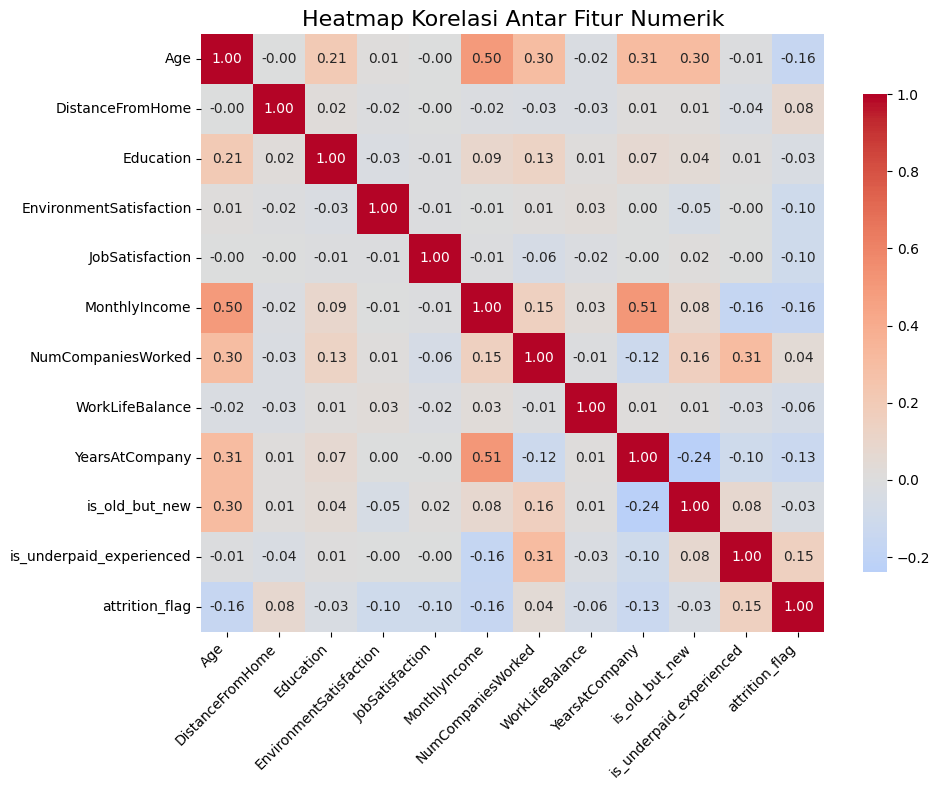

In [ ]:
# BUAT KOLOM BARU: attrition_flag (attrition kita rubah dari yang yes atau no jadi 1 atau 0)
df['attrition_flag'] = (df['Attrition'] == 'Yes').astype(int)

# Maukan kolom baru ke dalam list numeric_cols
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# 2. Hitung korelasi
corr_matrix = df[numeric_cols].corr()

# 3. Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix,
            annot=True,        # tampilin angka korelasinya
            cmap='coolwarm',   # warna: merah = positif, biru = negatif
            center=0,          # tengahnya di 0
            fmt='.2f',         # 2 angka di belakang koma
            cbar_kws={"shrink": 0.8})
plt.title('Heatmap Korelasi Antar Fitur Numerik', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Analisa Berdasarkan Usia

Kita lihat bagaimana persebaran data berdasarkan usia baik secara jumlah statistik, persentase, dan juga visualisasi

In [ ]:
# ============================================
# EDA - DEMOGRAFI: AGE
# ============================================

# 1. Setting style biar rapi
sns.set_style("whitegrid")

# 2. PERSENTASE AGE GROUP
print("="*50)
print("DISTRIBUSI USIA KARYAWAN (age_group)")
print("="*50)
age_counts = df['age_group'].value_counts()
print(age_counts)
print("\nPersentase:")
print((age_counts / len(df) * 100).round(2))

# 3. ATTRITION PER AGE GROUP
print("\n" + "="*50)
print("ATTRITION RATE PER AGE GROUP")
print("="*50)
age_attrition = df.groupby('age_group')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print(age_attrition.round(2))

# 4. Crosstab: Jumlah & Persentase
print("\n" + "="*50)
print("CROSSTAB: AGE GROUP vs ATTRITION")
print("="*50)
crosstab_age = pd.crosstab(df['age_group'], df['Attrition'], margins=True)
print(crosstab_age)

# 5. Crosstab dalam persentase (per baris)
crosstab_age_pct = pd.crosstab(df['age_group'], df['Attrition'], normalize='index') * 100
print("\nPersentase per Baris:")
print(crosstab_age_pct.round(2))

DISTRIBUSI USIA KARYAWAN (age_group)
age_group
26-35    606
36-45    468
46-60    273
18-25    123
Name: count, dtype: int64

Persentase:
age_group
26-35    41.22
36-45    31.84
46-60    18.57
18-25     8.37
Name: count, dtype: float64

ATTRITION RATE PER AGE GROUP
age_group
18-25    35.77
26-35    19.14
36-45     9.19
46-60    12.45
Name: Attrition, dtype: float64

CROSSTAB: AGE GROUP vs ATTRITION
Attrition    No  Yes   All
age_group                 
18-25        79   44   123
26-35       490  116   606
36-45       425   43   468
46-60       239   34   273
All        1233  237  1470

Persentase per Baris:
Attrition     No    Yes
age_group              
18-25      64.23  35.77
26-35      80.86  19.14
36-45      90.81   9.19
46-60      87.55  12.45


/tmp/ipykernel_3120/1499203928.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_attrition = df.groupby('age_group')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)


/tmp/ipykernel_3120/1238860657.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='age_group', order=['18-25', '26-35', '36-45', '46-60'],


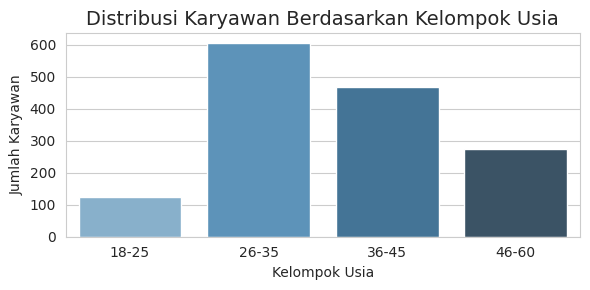

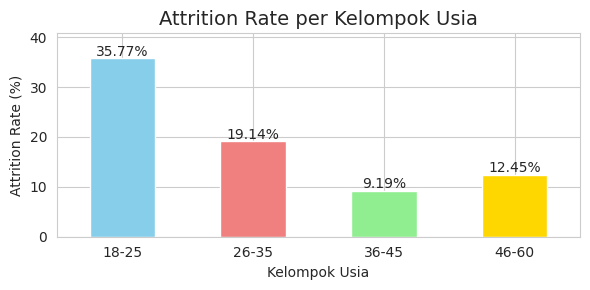

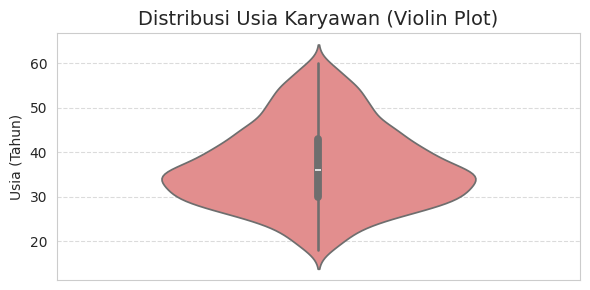

In [ ]:
# 1. PLOT: Distribusi Age Group
plt.figure(figsize=(6,3))
sns.countplot(data=df, x='age_group', order=['18-25', '26-35', '36-45', '46-60'],
              palette='Blues_d')
plt.title('Distribusi Karyawan Berdasarkan Kelompok Usia', fontsize=14)
plt.xlabel('Kelompok Usia')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 2. PLOT: Attrition Rate per Age Group
plt.figure(figsize=(6,3))
age_attrition.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold'])
plt.title('Attrition Rate per Kelompok Usia', fontsize=14)
plt.xlabel('Kelompok Usia')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(age_attrition) + 5)  # Kasih ruang di atas
for i, v in enumerate(age_attrition):
    plt.text(i, v + 0.5, f'{v:.2f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# 3. VIOLIN PLOT: DISTRIBUSI USIA KARYAWAN
plt.figure(figsize=(6, 3))
sns.violinplot(data=df, y='Age', color='lightcoral', width=0.6)
plt.title('Distribusi Usia Karyawan (Violin Plot)', fontsize=14)
plt.ylabel('Usia (Tahun)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Analisa Berdasarkan Marital Status

Kita lihat bagaimana persebaran data berdasarkan status pernikahan baik secara jumlah statistik, persentase, dan juga visualisasi

MARITAL STATUS - DISTRIBUSI & ATTRITION

📌 Distribusi Karyawan:
MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64

Persentase:
MaritalStatus
Married     45.8
Single      32.0
Divorced    22.2
Name: count, dtype: float64

📌 Attrition Rate per Status Pernikahan:
MaritalStatus
Divorced    10.09
Married     12.48
Single      25.53
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/1244657086.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='MaritalStatus', palette='Set2', order=df['MaritalStatus'].value_counts().index)


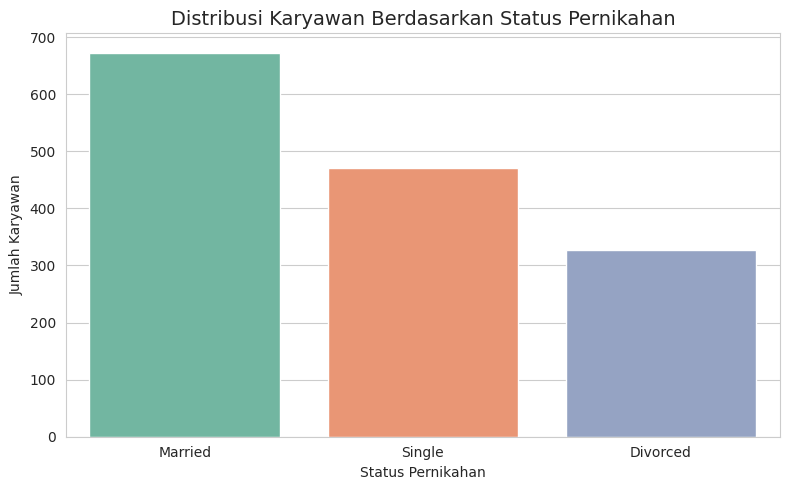

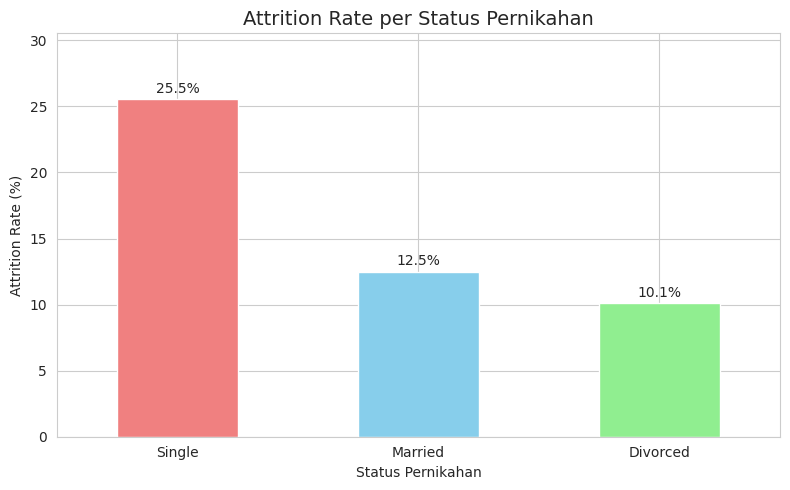


📌 Crosstab: Marital Status vs Attrition
Attrition        No  Yes   All
MaritalStatus                 
Divorced        294   33   327
Married         589   84   673
Single          350  120   470
All            1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition        No   Yes
MaritalStatus            
Divorced       89.9  10.1
Married        87.5  12.5
Single         74.5  25.5


In [ ]:
# ============================================
# EDA - DEMOGRAFI: MARITAL STATUS
# ============================================

print("="*50)
print("MARITAL STATUS - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Marital Status
marital_counts = df['MaritalStatus'].value_counts()
print("\n📌 Distribusi Karyawan:")
print(marital_counts)
print(f"\nPersentase:")
print((marital_counts / len(df) * 100).round(1))

# 2. Attrition Rate per Marital Status
marital_attrition = df.groupby('MaritalStatus')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Status Pernikahan:")
print(marital_attrition.round(2))

# 3. Plot distribusi
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='MaritalStatus', palette='Set2', order=df['MaritalStatus'].value_counts().index)
plt.title('Distribusi Karyawan Berdasarkan Status Pernikahan', fontsize=14)
plt.xlabel('Status Pernikahan')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot attrition rate
plt.figure(figsize=(8,5))
marital_attrition.sort_values(ascending=False).plot(kind='bar', color=['lightcoral', 'skyblue', 'lightgreen'])
plt.title('Attrition Rate per Status Pernikahan', fontsize=14)
plt.xlabel('Status Pernikahan')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(marital_attrition) + 5)
for i, v in enumerate(marital_attrition.sort_values(ascending=False)):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# 5. Crosstab (opsional, buat lihat detail)
print("\n📌 Crosstab: Marital Status vs Attrition")
crosstab_marital = pd.crosstab(df['MaritalStatus'], df['Attrition'], margins=True)
print(crosstab_marital)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_marital_pct = pd.crosstab(df['MaritalStatus'], df['Attrition'], normalize='index') * 100
print(crosstab_marital_pct.round(1))

## Analisa Berdasarkan Departemen

Kita lihat bagaimana persebaran data berdasarkan departemen secara jumlah statistik, persentase, dan juga visualisasi

DEPARTEMEN - DISTRIBUSI & ATTRITION

📌 Distribusi Karyawan:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

Persentase:
Department
Research & Development    65.4
Sales                     30.3
Human Resources            4.3
Name: count, dtype: float64

📌 Attrition Rate per Departemen:
Department
Human Resources           19.05
Research & Development    13.84
Sales                     20.63
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/1795011637.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Department', palette='Set2', order=df['Department'].value_counts().index)


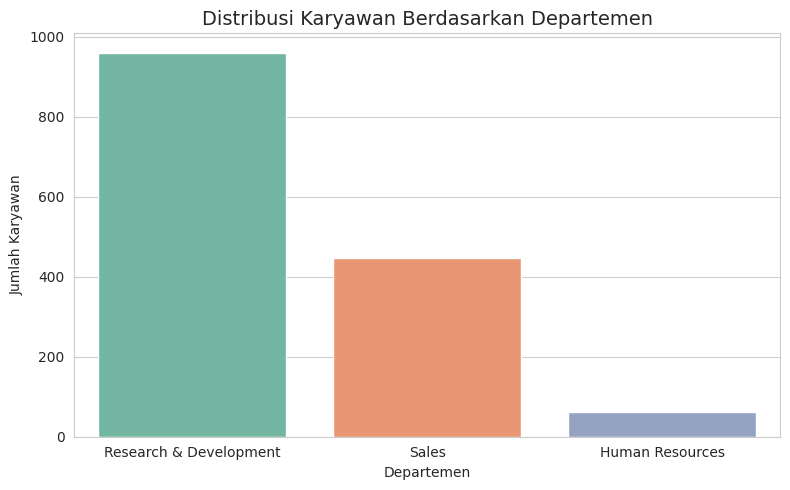

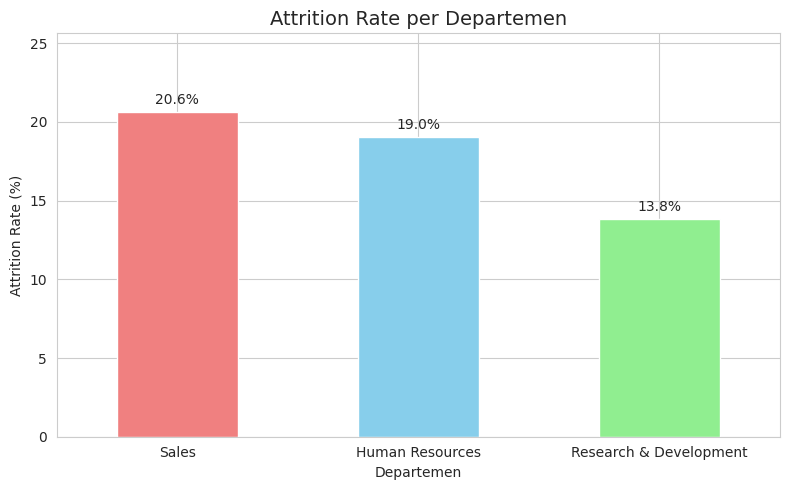


📌 Crosstab: Departemen vs Attrition
Attrition                 No  Yes   All
Department                             
Human Resources           51   12    63
Research & Development   828  133   961
Sales                    354   92   446
All                     1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition                 No   Yes
Department                        
Human Resources         81.0  19.0
Research & Development  86.2  13.8
Sales                   79.4  20.6


In [ ]:
# ============================================
# EDA - DEMOGRAFI: DEPARTEMEN
# ============================================

print("="*50)
print("DEPARTEMEN - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Departemen
department_counts = df['Department'].value_counts()
print("\n📌 Distribusi Karyawan:")
print(department_counts)
print(f"\nPersentase:")
print((department_counts / len(df) * 100).round(1))

# 2. Attrition Rate per Departemen
department_attrition = df.groupby('Department')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Departemen:")
print(department_attrition.round(2))

# 3. Plot distribusi
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Department', palette='Set2', order=df['Department'].value_counts().index)
plt.title('Distribusi Karyawan Berdasarkan Departemen', fontsize=14)
plt.xlabel('Departemen')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot attrition rate
plt.figure(figsize=(8,5))
department_attrition.sort_values(ascending=False).plot(kind='bar', color=['lightcoral', 'skyblue', 'lightgreen'])
plt.title('Attrition Rate per Departemen', fontsize=14)
plt.xlabel('Departemen')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(department_attrition) + 5)
for i, v in enumerate(department_attrition.sort_values(ascending=False)):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# 5. Crosstab (opsional, buat lihat detail)
print("\n📌 Crosstab: Departemen vs Attrition")
crosstab_department = pd.crosstab(df['Department'], df['Attrition'], margins=True)
print(crosstab_department)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_department_pct = pd.crosstab(df['Department'], df['Attrition'], normalize='index') * 100
print(crosstab_department_pct.round(1))

## Analisa Berdasarkan Level Pendidikan

Kita lihat bagaimana persebaran data berdasarkan level pendidika secara jumlah statistik, persentase, dan juga visualisasi

EDUKASI - DISTRIBUSI & ATTRITION

📌 Distribusi Karyawan:
Education
3    572
4    398
2    282
1    170
5     48
Name: count, dtype: int64

Persentase:
Education
1    11.6
2    19.2
3    38.9
4    27.1
5     3.3
Name: count, dtype: float64

📌 Attrition Rate per Education:
Education
1    18.24
2    15.60
3    17.31
4    14.57
5    10.42
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/2583455695.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Education', palette='Set2', order=sorted(df['Education'].unique()))


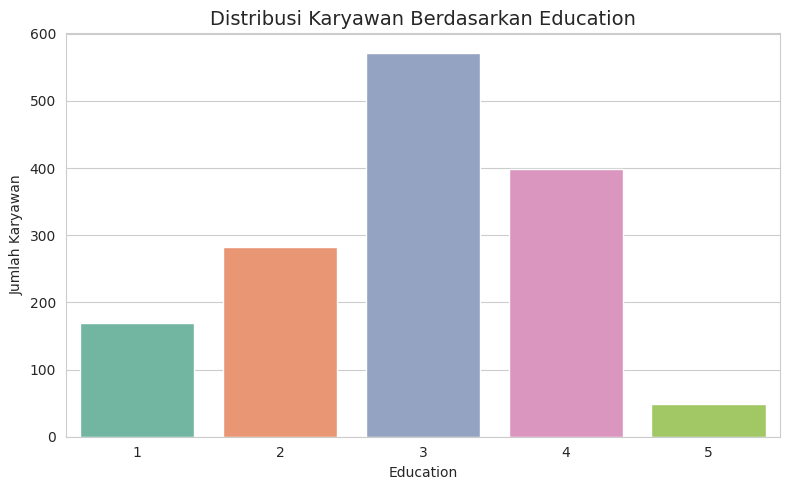

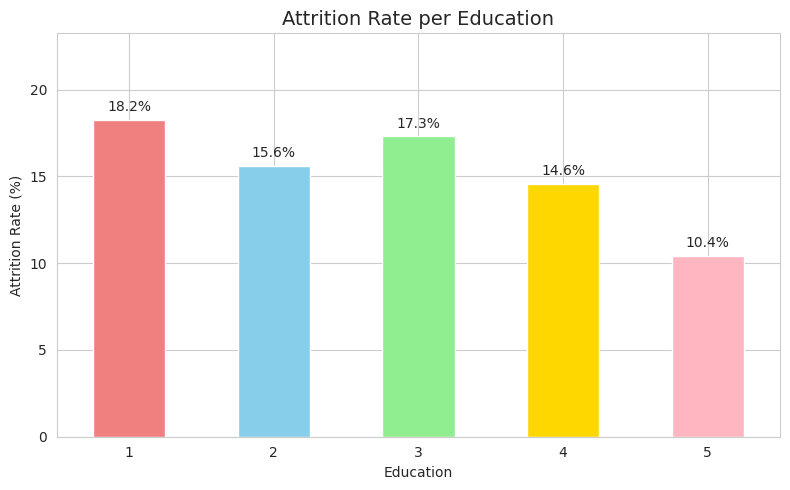


📌 Crosstab: Education vs Attrition
Attrition    No  Yes   All
Education                 
1           139   31   170
2           238   44   282
3           473   99   572
4           340   58   398
5            43    5    48
All        1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition    No   Yes
Education            
1          81.8  18.2
2          84.4  15.6
3          82.7  17.3
4          85.4  14.6
5          89.6  10.4


In [ ]:
9# ============================================
# EDA - DEMOGRAFI: EDUCATION
# ============================================

print("="*50)
print("EDUKASI - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Edukasi
education_counts = df['Education'].value_counts()
print("\n📌 Distribusi Karyawan:")
print(education_counts)
print(f"\nPersentase:")
print((education_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Education
education_attrition = df.groupby('Education')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Education:")
print(education_attrition.round(2))

# 3. Plot distribusi (urut Education 1-5)
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Education', palette='Set2', order=sorted(df['Education'].unique()))
plt.title('Distribusi Karyawan Berdasarkan Education', fontsize=14)
plt.xlabel('Education')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot attrition rate (urut Education 1-5)
plt.figure(figsize=(8,5))
education_attrition.sort_index().plot(kind='bar', color=['lightcoral', 'skyblue', 'lightgreen', 'gold', 'lightpink'])
plt.title('Attrition Rate per Education', fontsize=14)
plt.xlabel('Education')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(education_attrition) + 5)
for i, v in enumerate(education_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# 5. Crosstab (opsional, buat lihat detail)
print("\n📌 Crosstab: Education vs Attrition")
crosstab_education = pd.crosstab(df['Education'], df['Attrition'], margins=True)
print(crosstab_education)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_education_pct = pd.crosstab(df['Education'], df['Attrition'], normalize='index') * 100
print(crosstab_education_pct.round(1))

## Analisa Berdasarkan Latar Pendidikan

Kita lihat bagaimana persebaran data berdasarkan latar pendidika secara jumlah statistik, persentase, dan juga visualisasi

LATAR EDUKASI - DISTRIBUSI & ATTRITION

📌 Distribusi Karyawan:
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Persentase:
EducationField
Human Resources      1.8
Life Sciences       41.2
Marketing           10.8
Medical             31.6
Other                5.6
Technical Degree     9.0
Name: count, dtype: float64

📌 Attrition Rate per Education Field:
Education
1    18.24
2    15.60
3    17.31
4    14.57
5    10.42
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/3051254969.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='EducationField', palette='Set2', order=sorted(df['EducationField'].unique()))


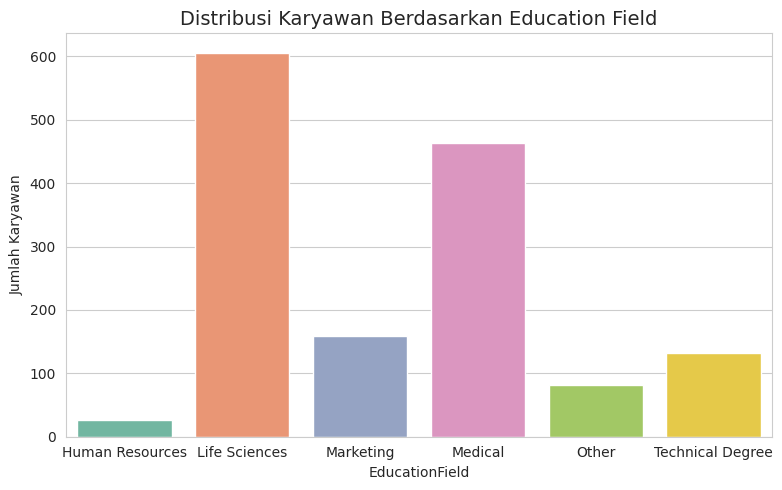

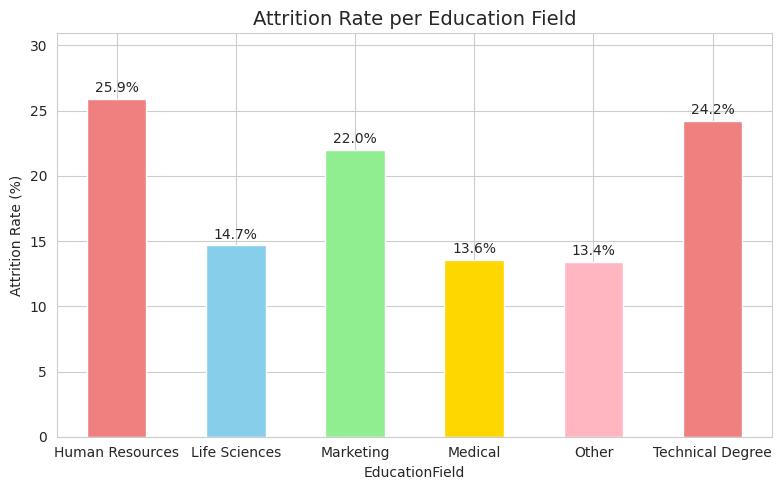


📌 Crosstab: Education Field vs Attrition
Attrition           No  Yes   All
EducationField                   
Human Resources     20    7    27
Life Sciences      517   89   606
Marketing          124   35   159
Medical            401   63   464
Other               71   11    82
Technical Degree   100   32   132
All               1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition           No   Yes
EducationField              
Human Resources   74.1  25.9
Life Sciences     85.3  14.7
Marketing         78.0  22.0
Medical           86.4  13.6
Other             86.6  13.4
Technical Degree  75.8  24.2


In [ ]:
9# ============================================
# EDA - DEMOGRAFI: EDUCATION FIELD
# ============================================

print("="*50)
print("LATAR EDUKASI - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Latar Edukasi
educationfield_counts = df['EducationField'].value_counts()
print("\n📌 Distribusi Karyawan:")
print(educationfield_counts)
print(f"\nPersentase:")
print((educationfield_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Education
educationfield_attrition = df.groupby('EducationField')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Education Field:")
print(education_attrition.round(2))

# 3. Plot distribusi
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='EducationField', palette='Set2', order=sorted(df['EducationField'].unique()))
plt.title('Distribusi Karyawan Berdasarkan Education Field', fontsize=14)
plt.xlabel('EducationField')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot attrition rate
plt.figure(figsize=(8,5))
educationfield_attrition.sort_index().plot(kind='bar', color=['lightcoral', 'skyblue', 'lightgreen', 'gold', 'lightpink'])
plt.title('Attrition Rate per Education Field', fontsize=14)
plt.xlabel('EducationField')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(educationfield_attrition) + 5)
for i, v in enumerate(educationfield_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# 5. Crosstab (opsional, buat lihat detail)
print("\n📌 Crosstab: Education Field vs Attrition")
crosstab_educationfield = pd.crosstab(df['EducationField'], df['Attrition'], margins=True)
print(crosstab_educationfield)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_educationfield_pct = pd.crosstab(df['EducationField'], df['Attrition'], normalize='index') * 100
print(crosstab_educationfield_pct.round(1))

## Analisa Berdasarkan Jarak Dari Rumah ke Kantor

Kita lihat bagaimana persebaran data berdasarkan jarak tempuh secara jumlah statistik, persentase, dan juga visualisasi

DISTANCE FROM HOME - DISTRIBUSI & ATTRITION

📌 Distribusi Karyawan:
distance_group
Near (<5)        632
Medium (5-15)    509
Far (>15)        329
Name: count, dtype: int64

Persentase:
distance_group
Near (<5)        43.0
Medium (5-15)    34.6
Far (>15)        22.4
Name: count, dtype: float64

📌 Attrition Rate per Distance Group:
distance_group
Near (<5)        13.77
Medium (5-15)    16.11
Far (>15)        20.67
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/2339563823.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  distance_attrition = df.groupby('distance_group')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
/tmp/ipykernel_3120/2339563823.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='distance_group', palette='Set2',


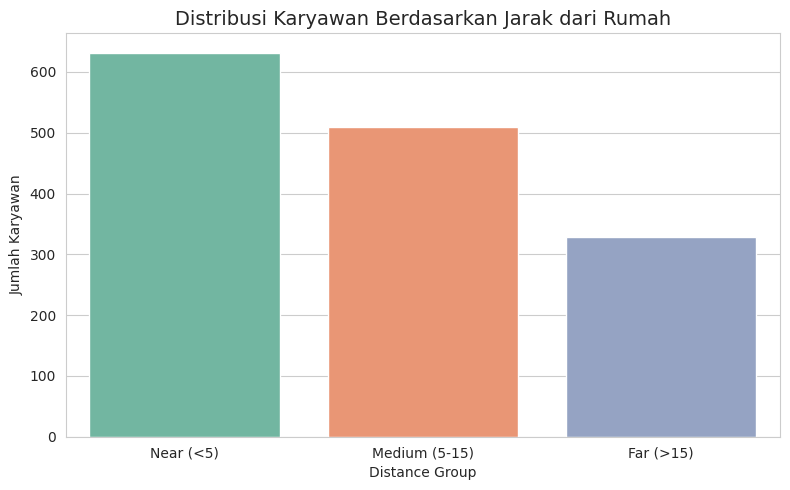

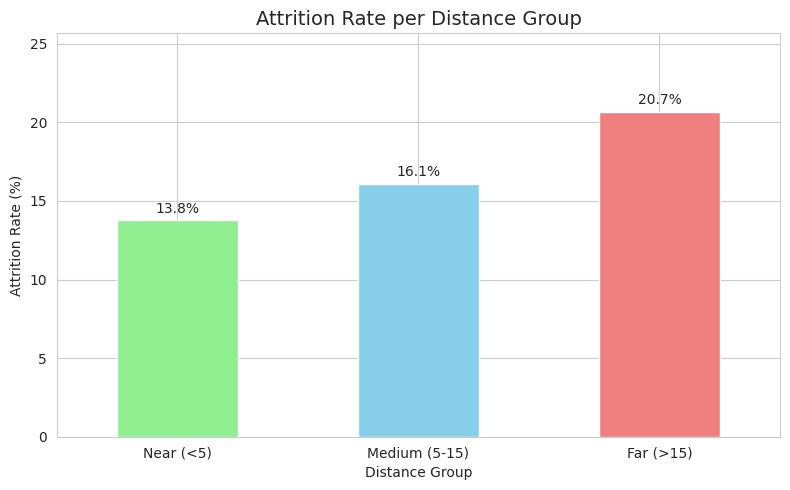


📌 Crosstab: Distance Group vs Attrition
Attrition         No  Yes   All
distance_group                 
Near (<5)        545   87   632
Medium (5-15)    427   82   509
Far (>15)        261   68   329
All             1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition         No   Yes
distance_group            
Near (<5)       86.2  13.8
Medium (5-15)   83.9  16.1
Far (>15)       79.3  20.7


In [ ]:
# ============================================
# EDA - DEMOGRAFI: DISTANCE FROM HOME
# ============================================

print("="*50)
print("DISTANCE FROM HOME - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Distance Group
distance_counts = df['distance_group'].value_counts().sort_index()
print("\n📌 Distribusi Karyawan:")
print(distance_counts)
print(f"\nPersentase:")
print((distance_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Distance Group
distance_attrition = df.groupby('distance_group')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Distance Group:")
print(distance_attrition.round(2))

# 3. Plot distribusi
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='distance_group', palette='Set2',
              order=['Near (<5)', 'Medium (5-15)', 'Far (>15)'])
plt.title('Distribusi Karyawan Berdasarkan Jarak dari Rumah', fontsize=14)
plt.xlabel('Distance Group')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot attrition rate
plt.figure(figsize=(8,5))
distance_attrition.sort_index().plot(kind='bar', color=['lightgreen', 'skyblue', 'lightcoral'])
plt.title('Attrition Rate per Distance Group', fontsize=14)
plt.xlabel('Distance Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(distance_attrition) + 5)
for i, v in enumerate(distance_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# 5. Crosstab
print("\n📌 Crosstab: Distance Group vs Attrition")
crosstab_distance = pd.crosstab(df['distance_group'], df['Attrition'], margins=True)
print(crosstab_distance)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_distance_pct = pd.crosstab(df['distance_group'], df['Attrition'], normalize='index') * 100
print(crosstab_distance_pct.round(1))

PERSEBARAN JARAK DARI RUMAH

📌 Statistik DistanceFromHome:
count    1470.000000
mean        9.192517
std         8.106864
min         1.000000
25%         2.000000
50%         7.000000
75%        14.000000
max        29.000000
Name: DistanceFromHome, dtype: float64

📌 Cek Outlier (Metode IQR):
   Q1: 2.0
   Q3: 14.0
   IQR: 12.0
   Batas bawah: -16.0
   Batas atas: 32.0
   Jumlah outlier: 0


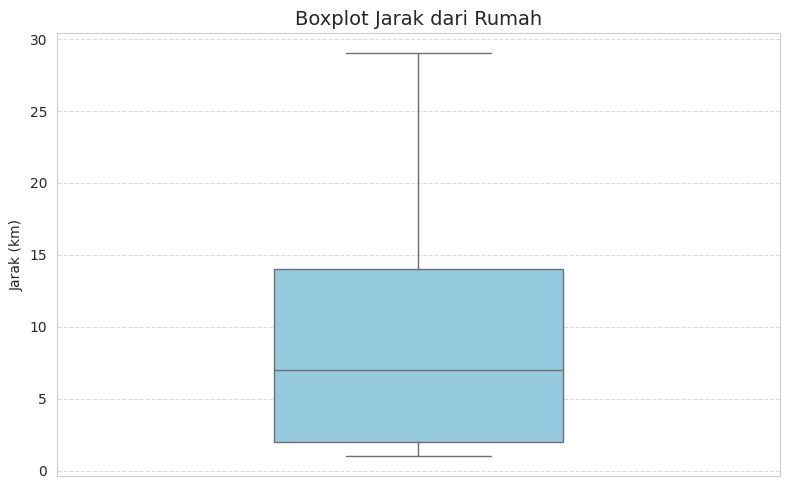

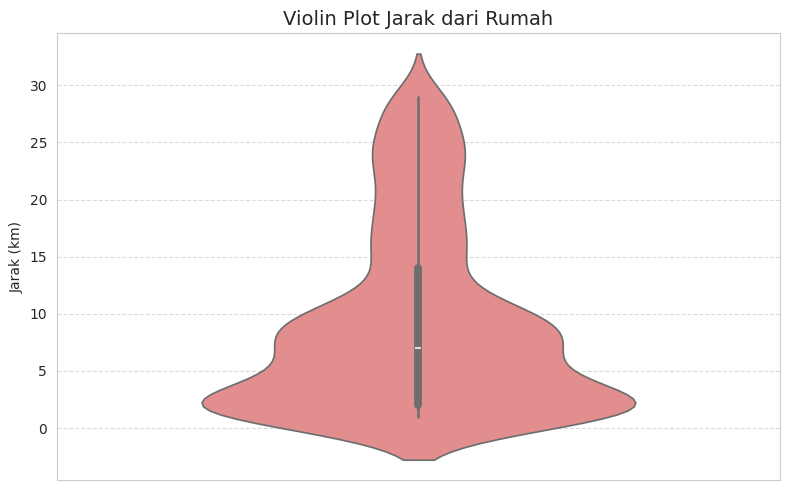

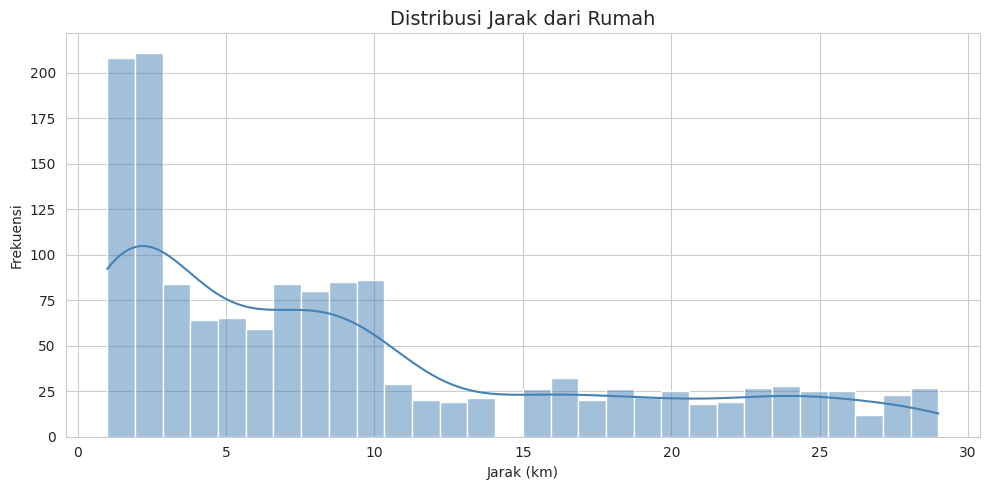

In [ ]:
# ============================================
# PERSEBARAN JARAK DARI RUMAH (NUMERIK)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("PERSEBARAN JARAK DARI RUMAH")
print("="*50)

# 1. Statistik deskriptif
print("\n📌 Statistik DistanceFromHome:")
print(df['DistanceFromHome'].describe())

# 2. Cek Outlier pake IQR
Q1 = df['DistanceFromHome'].quantile(0.25)
Q3 = df['DistanceFromHome'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['DistanceFromHome'] < lower_bound) | (df['DistanceFromHome'] > upper_bound)]
print(f"\n📌 Cek Outlier (Metode IQR):")
print(f"   Q1: {Q1}")
print(f"   Q3: {Q3}")
print(f"   IQR: {IQR}")
print(f"   Batas bawah: {lower_bound}")
print(f"   Batas atas: {upper_bound}")
print(f"   Jumlah outlier: {len(outliers)}")
if len(outliers) > 0:
    print(f"   Nilai outlier: {sorted(outliers['DistanceFromHome'].unique())}")

# 3. Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(data=df, y='DistanceFromHome', color='skyblue', width=0.4)
plt.title('Boxplot Jarak dari Rumah', fontsize=14)
plt.ylabel('Jarak (km)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 4. Violin Plot
plt.figure(figsize=(8,5))
sns.violinplot(data=df, y='DistanceFromHome', color='lightcoral', width=0.6)
plt.title('Violin Plot Jarak dari Rumah', fontsize=14)
plt.ylabel('Jarak (km)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 5. Histogram (lihat distribusi)
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='DistanceFromHome', bins=30, kde=True, color='steelblue')
plt.title('Distribusi Jarak dari Rumah', fontsize=14)
plt.xlabel('Jarak (km)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

## Analisa Berdasarkan Job Satisfaction/Kepuasan berdasarkan pekerjaan

Kita lihat bagaimana persebaran data berdasarkan jarak tempuh secara jumlah statistik, persentase, dan juga visualisasi. Selain melihat attrition berdasarkan job satis faction kita juga akan melihat kombinasi antara job satisfaction ini dengan usia dan departemen karyawan

JOB SATISFACTION - DISTRIBUSI & ATTRITION

📌 Distribusi Job Satisfaction:
JobSatisfaction
1    289
2    280
3    442
4    459
Name: count, dtype: int64

Persentase:
JobSatisfaction
1    19.7
2    19.0
3    30.1
4    31.2
Name: count, dtype: float64

📌 Attrition Rate per Job Satisfaction:
JobSatisfaction
1    22.84
2    16.43
3    16.52
4    11.33
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/1365188810.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='JobSatisfaction', palette='Set2', order=sorted(df['JobSatisfaction'].unique()))


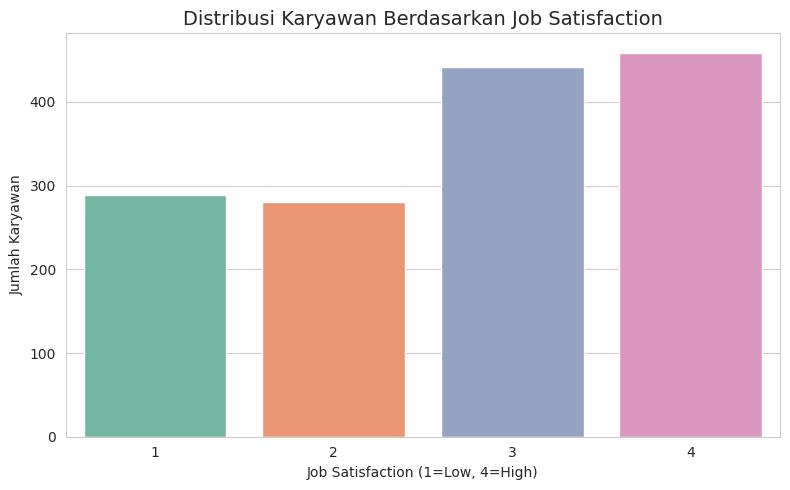

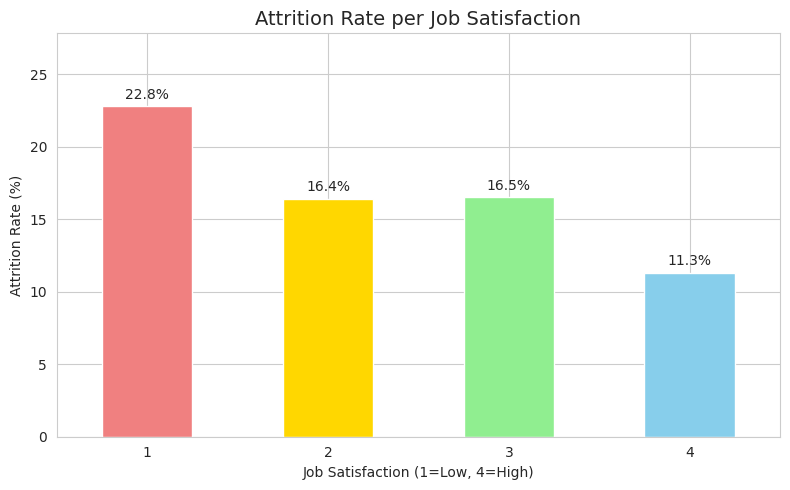


JOB SATISFACTION PER DEPARTMENT

📌 Rata-rata Job Satisfaction per Department:
Department
Sales                     2.75
Research & Development    2.73
Human Resources           2.60
Name: JobSatisfaction, dtype: float64


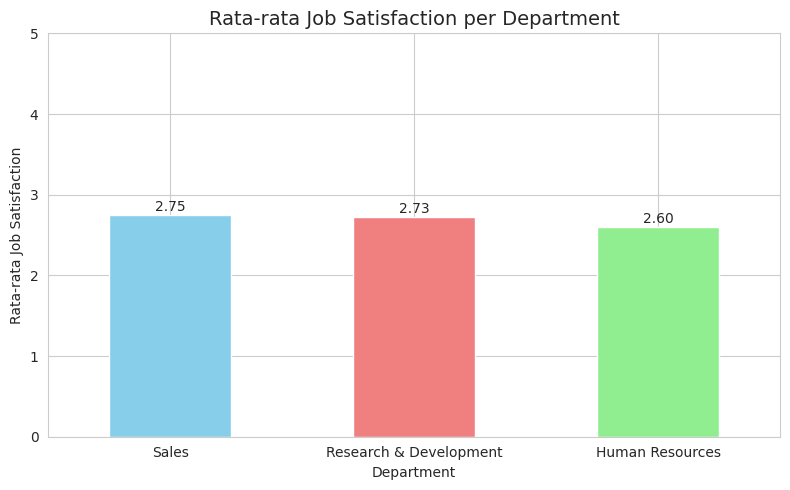


JOB SATISFACTION PER AGE GROUP

📌 Rata-rata Job Satisfaction per Age Group:
age_group
18-25    2.73
26-35    2.74
36-45    2.73
46-60    2.70
Name: JobSatisfaction, dtype: float64


/tmp/ipykernel_3120/1365188810.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  jobsat_age = df.groupby('age_group')['JobSatisfaction'].mean().sort_index()


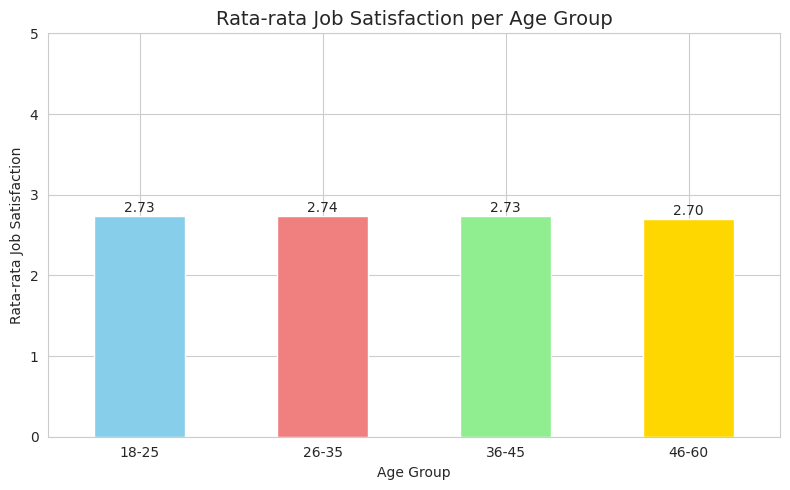


ATTRITION RATE: JOB SATISFACTION x DEPARTMENT

📌 Attrition Rate (%) per Department x Job Satisfaction:
JobSatisfaction            1     2     3     4
Department                                    
Human Resources         45.5  10.0  20.0  11.8
Research & Development  19.8  13.8  14.3   9.5
Sales                   26.7  23.3  21.3  15.0


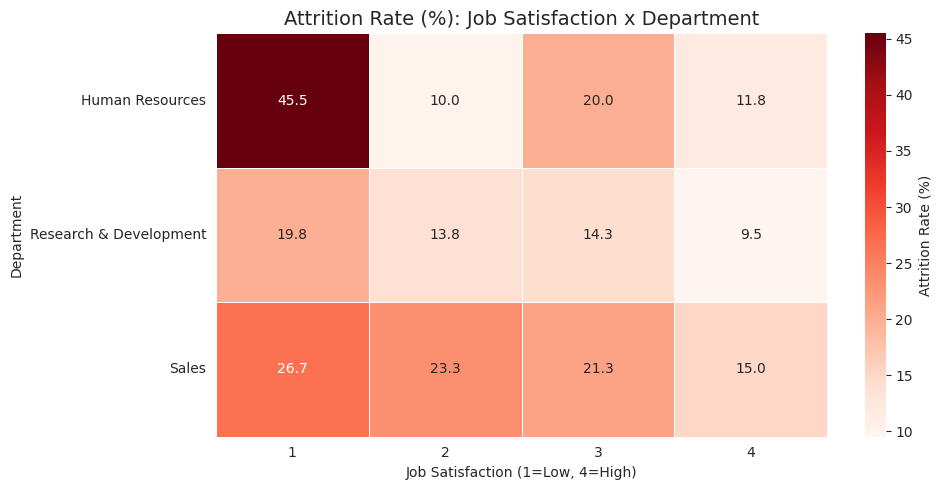


ATTRITION RATE: JOB SATISFACTION x AGE GROUP

📌 Attrition Rate (%) per Age Group x Job Satisfaction:
JobSatisfaction     1     2     3     4
age_group                              
18-25            43.5  43.5  31.7  30.6
26-35            28.9  18.9  19.6  12.8
36-45            17.2   8.9   9.6   4.0
46-60             9.6  12.5  13.8  12.8


/tmp/ipykernel_3120/1365188810.py:129: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_age_jobsat = df.pivot_table(


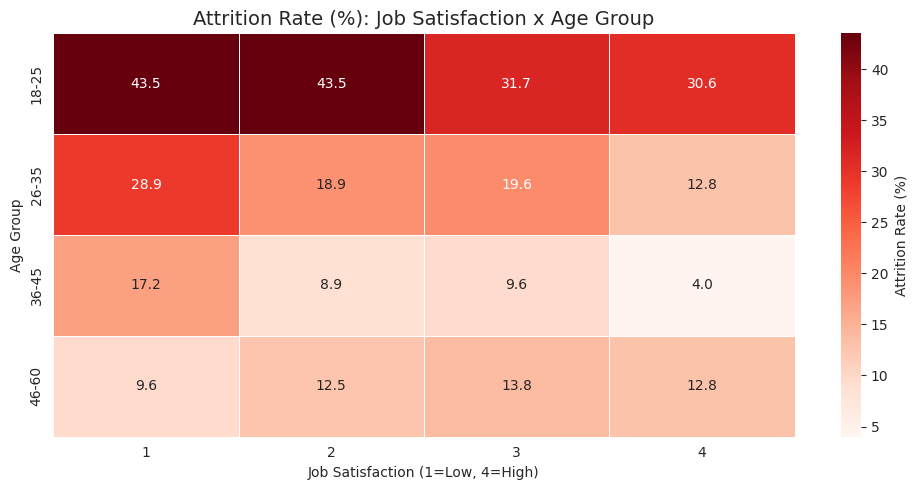


📌 Crosstab: Job Satisfaction vs Attrition
Attrition          No  Yes   All
JobSatisfaction                 
1                 223   66   289
2                 234   46   280
3                 369   73   442
4                 407   52   459
All              1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition          No   Yes
JobSatisfaction            
1                77.2  22.8
2                83.6  16.4
3                83.5  16.5
4                88.7  11.3


In [ ]:
# ============================================
# EDA - KESEIMBANGAN PEKERJAAN: JOB SATISFACTION
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("JOB SATISFACTION - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Job Satisfaction
jobsat_counts = df['JobSatisfaction'].value_counts().sort_index()
print("\n📌 Distribusi Job Satisfaction:")
print(jobsat_counts)
print(f"\nPersentase:")
print((jobsat_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Job Satisfaction
jobsat_attrition = df.groupby('JobSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Job Satisfaction:")
print(jobsat_attrition.round(2))

# 3. Plot Distribusi Job Satisfaction
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='JobSatisfaction', palette='Set2', order=sorted(df['JobSatisfaction'].unique()))
plt.title('Distribusi Karyawan Berdasarkan Job Satisfaction', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot Attrition Rate per Job Satisfaction
plt.figure(figsize=(8,5))
jobsat_attrition.sort_index().plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue'])
plt.title('Attrition Rate per Job Satisfaction', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(jobsat_attrition) + 5)
for i, v in enumerate(jobsat_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 5. JOB SATISFACTION PER DEPARTMENT
# ============================================

print("\n" + "="*50)
print("JOB SATISFACTION PER DEPARTMENT")
print("="*50)

jobsat_dept = df.groupby('Department')['JobSatisfaction'].mean().sort_values(ascending=False)
print("\n📌 Rata-rata Job Satisfaction per Department:")
print(jobsat_dept.round(2))

plt.figure(figsize=(8,5))
jobsat_dept.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Rata-rata Job Satisfaction per Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Rata-rata Job Satisfaction')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, v in enumerate(jobsat_dept):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 6. JOB SATISFACTION PER AGE GROUP
# ============================================

print("\n" + "="*50)
print("JOB SATISFACTION PER AGE GROUP")
print("="*50)

jobsat_age = df.groupby('age_group')['JobSatisfaction'].mean().sort_index()
print("\n📌 Rata-rata Job Satisfaction per Age Group:")
print(jobsat_age.round(2))

plt.figure(figsize=(8,5))
jobsat_age.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold'])
plt.title('Rata-rata Job Satisfaction per Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Rata-rata Job Satisfaction')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, v in enumerate(jobsat_age):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 7. ATTRITION PER JOB SATISFACTION PER DEPARTMENT
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: JOB SATISFACTION x DEPARTMENT")
print("="*50)

pivot_dept_jobsat = df.pivot_table(
    values='Attrition',
    index='Department',
    columns='JobSatisfaction',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per Department x Job Satisfaction:")
print(pivot_dept_jobsat)

plt.figure(figsize=(10,5))
sns.heatmap(pivot_dept_jobsat, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Job Satisfaction x Department', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

# ============================================
# 8. ATTRITION PER JOB SATISFACTION PER AGE GROUP
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: JOB SATISFACTION x AGE GROUP")
print("="*50)

pivot_age_jobsat = df.pivot_table(
    values='Attrition',
    index='age_group',
    columns='JobSatisfaction',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per Age Group x Job Satisfaction:")
print(pivot_age_jobsat)

plt.figure(figsize=(10,5))
sns.heatmap(pivot_age_jobsat, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Job Satisfaction x Age Group', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

# ============================================
# 9. CROSSTAB (OPSIONAL)
# ============================================

print("\n📌 Crosstab: Job Satisfaction vs Attrition")
crosstab_jobsat = pd.crosstab(df['JobSatisfaction'], df['Attrition'], margins=True)
print(crosstab_jobsat)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_jobsat_pct = pd.crosstab(df['JobSatisfaction'], df['Attrition'], normalize='index') * 100
print(crosstab_jobsat_pct.round(1))

## Analisa Berdasarkan Environment Satisfaction/Kepuasan lingkungan pekerjaan

Kita lihat bagaimana persebaran data berdasarkan kepuasan lingkungan kerja secara jumlah statistik, persentase, dan juga visualisasi. Selain melihat attrition berdasarkan job satis faction kita juga akan melihat kombinasi antara kepuasan lingkungan kerja ini dengan usia dan departemen karyawan

ENVIRONMENT SATISFACTION - DISTRIBUSI & ATTRITION

📌 Distribusi Environment Satisfaction:
EnvironmentSatisfaction
1    284
2    287
3    453
4    446
Name: count, dtype: int64

Persentase:
EnvironmentSatisfaction
1    19.3
2    19.5
3    30.8
4    30.3
Name: count, dtype: float64

📌 Attrition Rate per Environment Satisfaction:
EnvironmentSatisfaction
1    25.35
2    14.98
3    13.69
4    13.45
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/3777426885.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='EnvironmentSatisfaction', palette='Set2', order=sorted(df['EnvironmentSatisfaction'].unique()))


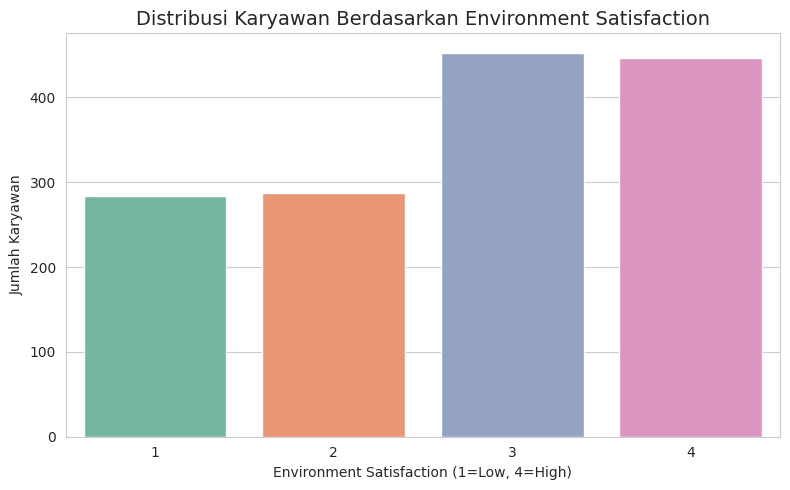

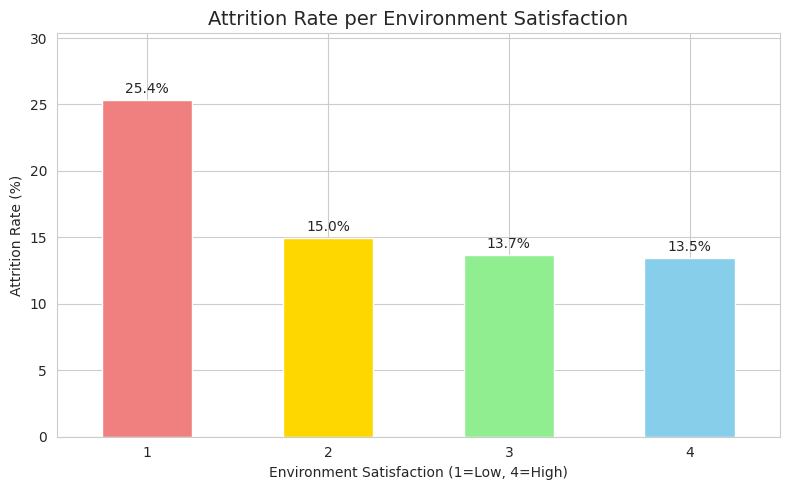


ENVIRONMENT SATISFACTION PER DEPARTMENT

📌 Rata-rata Environment Satisfaction per Department:
Department
Research & Development    2.74
Human Resources           2.68
Sales                     2.68
Name: EnvironmentSatisfaction, dtype: float64


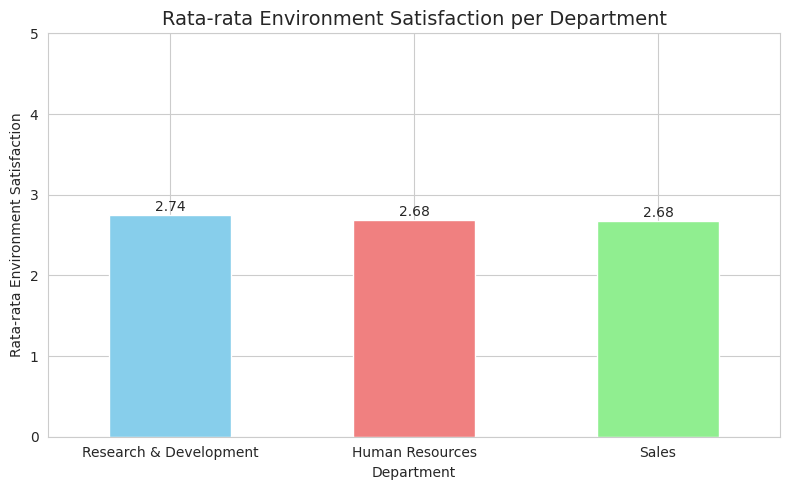


ENVIRONMENT SATISFACTION PER AGE GROUP

📌 Rata-rata Environment Satisfaction per Age Group:
age_group
18-25    2.68
26-35    2.75
36-45    2.66
46-60    2.78
Name: EnvironmentSatisfaction, dtype: float64


/tmp/ipykernel_3120/3777426885.py:76: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  envsat_age = df.groupby('age_group')['EnvironmentSatisfaction'].mean().sort_index()


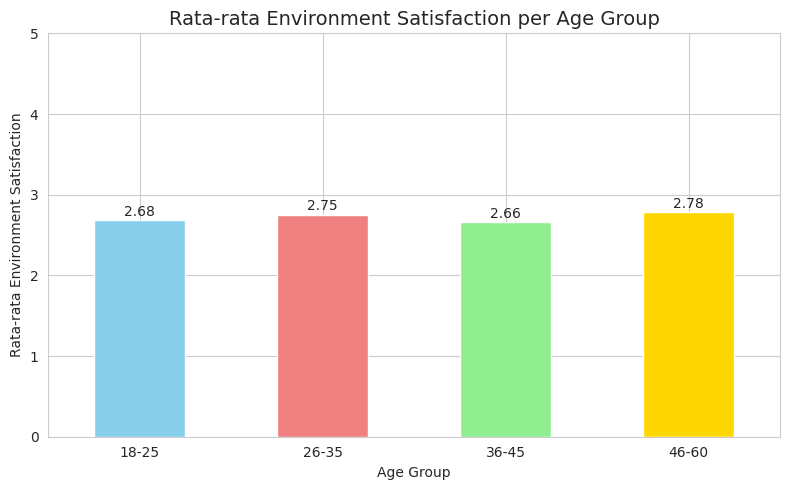


ATTRITION RATE: ENVIRONMENT SATISFACTION x DEPARTMENT

📌 Attrition Rate (%) per Department x Environment Satisfaction:
EnvironmentSatisfaction     1     2     3     4
Department                                     
Human Resources          36.4  25.0   7.7  21.4
Research & Development   23.0  10.2  13.0  11.1
Sales                    29.1  22.4  16.3  18.1


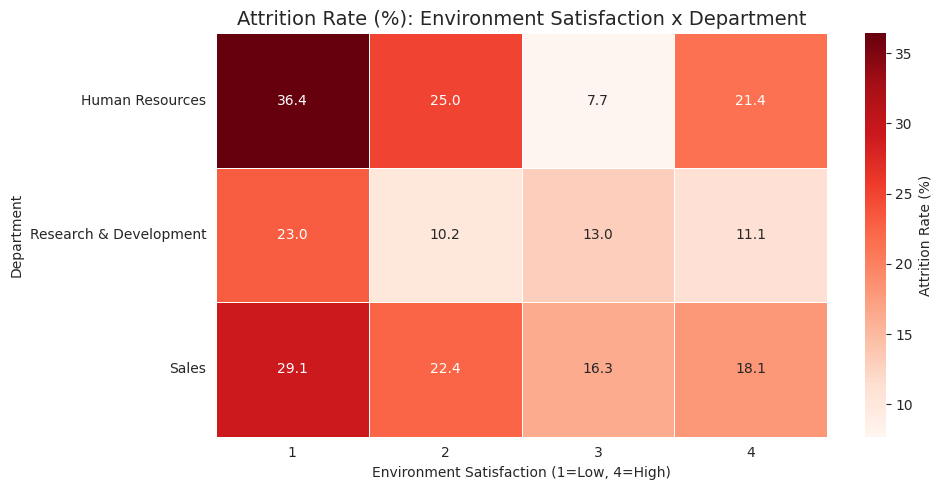


ATTRITION RATE: ENVIRONMENT SATISFACTION x AGE GROUP

📌 Attrition Rate (%) per Age Group x Environment Satisfaction:
EnvironmentSatisfaction     1     2     3     4
age_group                                      
18-25                    35.7  31.8  41.2  33.3
26-35                    35.2  18.9  14.3  15.3
36-45                    14.9   7.6   8.8   6.8
46-60                    19.3  13.2   9.3  10.9


/tmp/ipykernel_3120/3777426885.py:127: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_age_envsat = df.pivot_table(


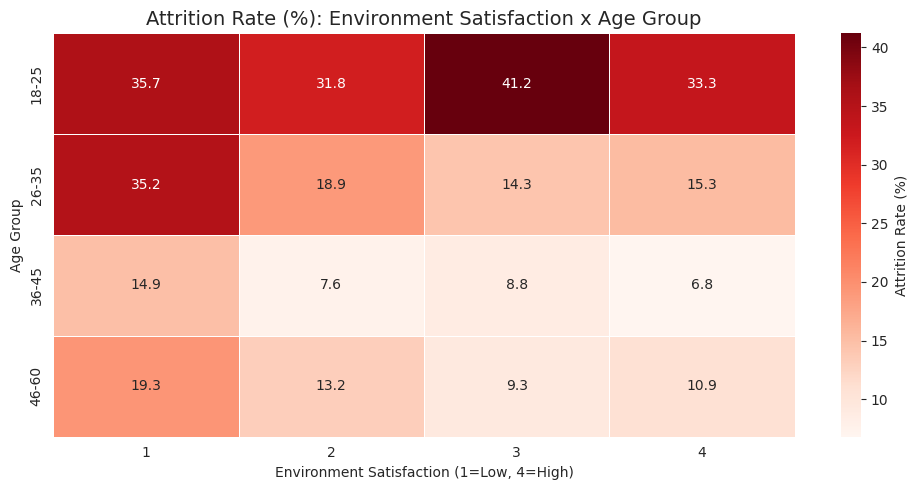


📌 Crosstab: Environment Satisfaction vs Attrition
Attrition                  No  Yes   All
EnvironmentSatisfaction                 
1                         212   72   284
2                         244   43   287
3                         391   62   453
4                         386   60   446
All                      1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition                  No   Yes
EnvironmentSatisfaction            
1                        74.6  25.4
2                        85.0  15.0
3                        86.3  13.7
4                        86.5  13.5


In [ ]:
# ============================================
# EDA - KESEIMBANGAN PEKERJAAN: ENVIRONMENT SATISFACTION
# ============================================


print("="*50)
print("ENVIRONMENT SATISFACTION - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Environment Satisfaction
envsat_counts = df['EnvironmentSatisfaction'].value_counts().sort_index()
print("\n📌 Distribusi Environment Satisfaction:")
print(envsat_counts)
print(f"\nPersentase:")
print((envsat_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Environment Satisfaction
envsat_attrition = df.groupby('EnvironmentSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Environment Satisfaction:")
print(envsat_attrition.round(2))

# 3. Plot Distribusi Environment Satisfaction
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='EnvironmentSatisfaction', palette='Set2', order=sorted(df['EnvironmentSatisfaction'].unique()))
plt.title('Distribusi Karyawan Berdasarkan Environment Satisfaction', fontsize=14)
plt.xlabel('Environment Satisfaction (1=Low, 4=High)')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot Attrition Rate per Environment Satisfaction
plt.figure(figsize=(8,5))
envsat_attrition.sort_index().plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue'])
plt.title('Attrition Rate per Environment Satisfaction', fontsize=14)
plt.xlabel('Environment Satisfaction (1=Low, 4=High)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(envsat_attrition) + 5)
for i, v in enumerate(envsat_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 5. ENVIRONMENT SATISFACTION PER DEPARTMENT
# ============================================

print("\n" + "="*50)
print("ENVIRONMENT SATISFACTION PER DEPARTMENT")
print("="*50)

envsat_dept = df.groupby('Department')['EnvironmentSatisfaction'].mean().sort_values(ascending=False)
print("\n📌 Rata-rata Environment Satisfaction per Department:")
print(envsat_dept.round(2))

plt.figure(figsize=(8,5))
envsat_dept.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Rata-rata Environment Satisfaction per Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Rata-rata Environment Satisfaction')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, v in enumerate(envsat_dept):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 6. ENVIRONMENT SATISFACTION PER AGE GROUP
# ============================================

print("\n" + "="*50)
print("ENVIRONMENT SATISFACTION PER AGE GROUP")
print("="*50)

envsat_age = df.groupby('age_group')['EnvironmentSatisfaction'].mean().sort_index()
print("\n📌 Rata-rata Environment Satisfaction per Age Group:")
print(envsat_age.round(2))

plt.figure(figsize=(8,5))
envsat_age.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold'])
plt.title('Rata-rata Environment Satisfaction per Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Rata-rata Environment Satisfaction')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, v in enumerate(envsat_age):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 7. ATTRITION PER ENVIRONMENT SATISFACTION PER DEPARTMENT
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: ENVIRONMENT SATISFACTION x DEPARTMENT")
print("="*50)

pivot_dept_envsat = df.pivot_table(
    values='Attrition',
    index='Department',
    columns='EnvironmentSatisfaction',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per Department x Environment Satisfaction:")
print(pivot_dept_envsat)

plt.figure(figsize=(10,5))
sns.heatmap(pivot_dept_envsat, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Environment Satisfaction x Department', fontsize=14)
plt.xlabel('Environment Satisfaction (1=Low, 4=High)')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

# ============================================
# 8. ATTRITION PER ENVIRONMENT SATISFACTION PER AGE GROUP
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: ENVIRONMENT SATISFACTION x AGE GROUP")
print("="*50)

pivot_age_envsat = df.pivot_table(
    values='Attrition',
    index='age_group',
    columns='EnvironmentSatisfaction',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per Age Group x Environment Satisfaction:")
print(pivot_age_envsat)

plt.figure(figsize=(10,5))
sns.heatmap(pivot_age_envsat, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Environment Satisfaction x Age Group', fontsize=14)
plt.xlabel('Environment Satisfaction (1=Low, 4=High)')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

# ============================================
# 9. CROSSTAB (OPSIONAL)
# ============================================

print("\n📌 Crosstab: Environment Satisfaction vs Attrition")
crosstab_envsat = pd.crosstab(df['EnvironmentSatisfaction'], df['Attrition'], margins=True)
print(crosstab_envsat)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_envsat_pct = pd.crosstab(df['EnvironmentSatisfaction'], df['Attrition'], normalize='index') * 100
print(crosstab_envsat_pct.round(1))

## Analisa Berdasarkan work life balance

Kita lihat bagaimana persebaran data berdasarkan work life balance jumlah statistik, persentase, dan juga visualisasi. Selain melihat attrition berdasarkan work life balance kita juga akan melihat kombinasi antara work life balance ini dengan usia dan departemen karyawan

WORK LIFE BALANCE - DISTRIBUSI & ATTRITION

📌 Distribusi Work Life Balance:
WorkLifeBalance
1     80
2    344
3    893
4    153
Name: count, dtype: int64

Persentase:
WorkLifeBalance
1     5.4
2    23.4
3    60.7
4    10.4
Name: count, dtype: float64

📌 Attrition Rate per Work Life Balance:
WorkLifeBalance
1    31.25
2    16.86
3    14.22
4    17.65
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/4057634184.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='WorkLifeBalance', palette='Set2', order=sorted(df['WorkLifeBalance'].unique()))


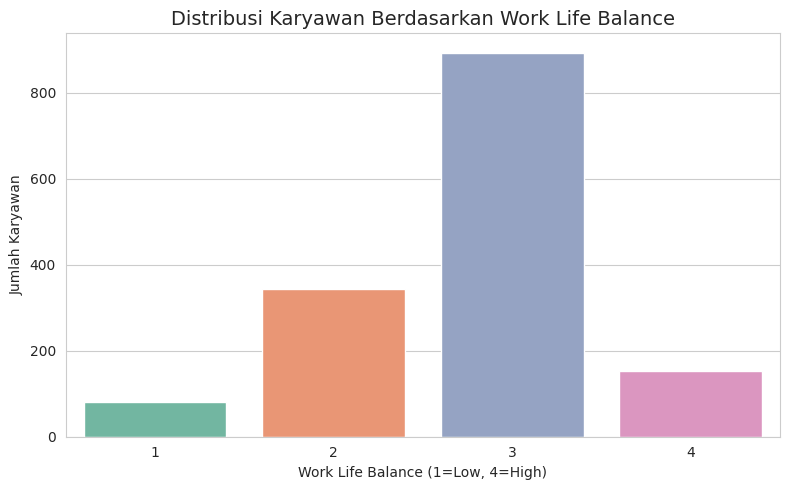

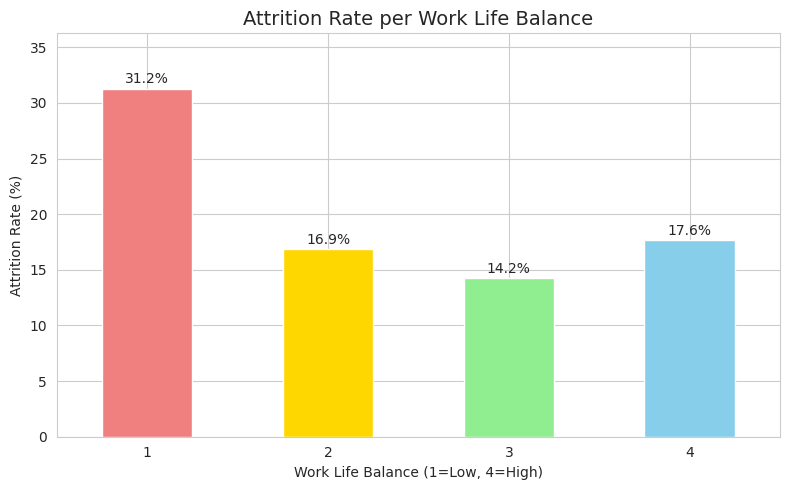


WORK LIFE BALANCE PER DEPARTMENT

📌 Rata-rata Work Life Balance per Department:
Department
Human Resources           2.92
Sales                     2.82
Research & Development    2.73
Name: WorkLifeBalance, dtype: float64


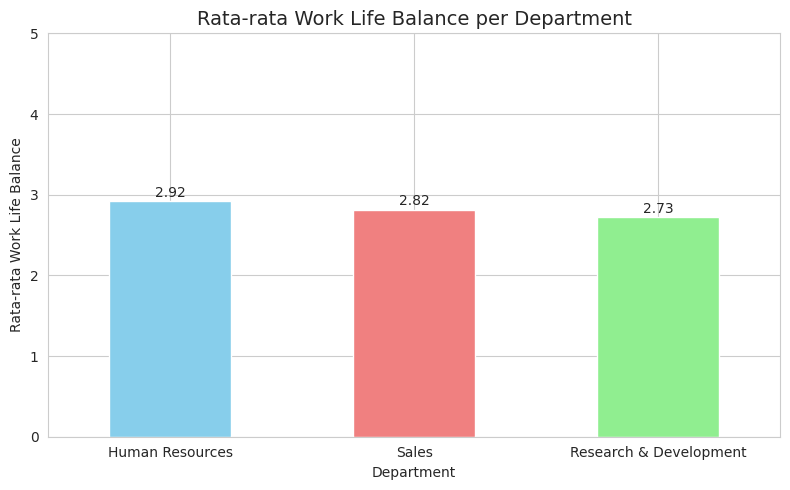


WORK LIFE BALANCE PER AGE GROUP

📌 Rata-rata Work Life Balance per Age Group:
age_group
18-25    2.85
26-35    2.74
36-45    2.81
46-60    2.68
Name: WorkLifeBalance, dtype: float64


/tmp/ipykernel_3120/4057634184.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  wlb_age = df.groupby('age_group')['WorkLifeBalance'].mean().sort_index()


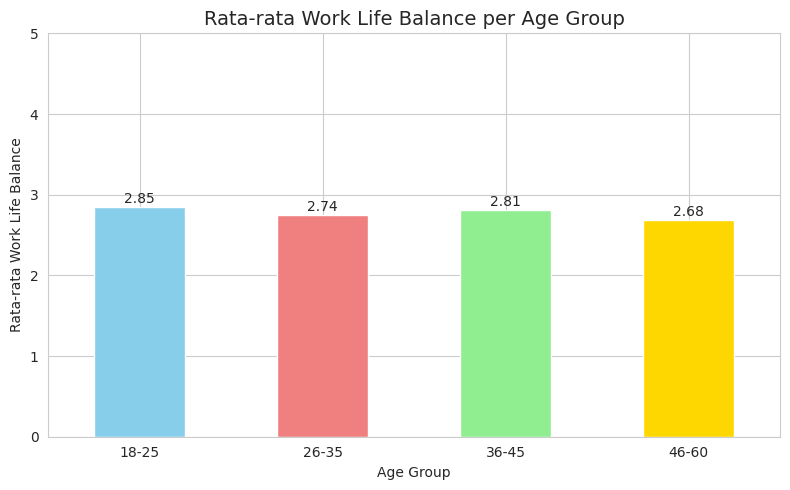


ATTRITION RATE: WORK LIFE BALANCE x DEPARTMENT

📌 Attrition Rate (%) per Department x Work Life Balance:
WorkLifeBalance            1     2     3     4
Department                                    
Human Resources          0.0  28.6  21.4  10.0
Research & Development  31.7  13.6  11.8  15.4
Sales                   37.5  23.5  18.1  23.1


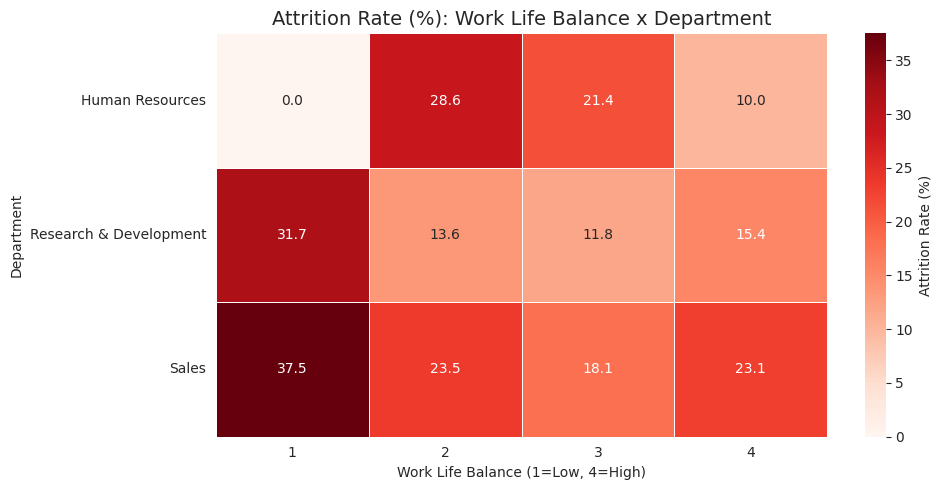


ATTRITION RATE: WORK LIFE BALANCE x AGE GROUP

📌 Attrition Rate (%) per Age Group x Work Life Balance:
WorkLifeBalance     1     2     3     4
age_group                              
18-25            40.0  29.6  37.0  38.9
26-35            34.3  22.1  16.1  21.7
36-45            40.9   9.2   7.4   5.9
46-60            11.1  12.2  12.1  16.7


/tmp/ipykernel_3120/4057634184.py:129: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_age_wlb = df.pivot_table(


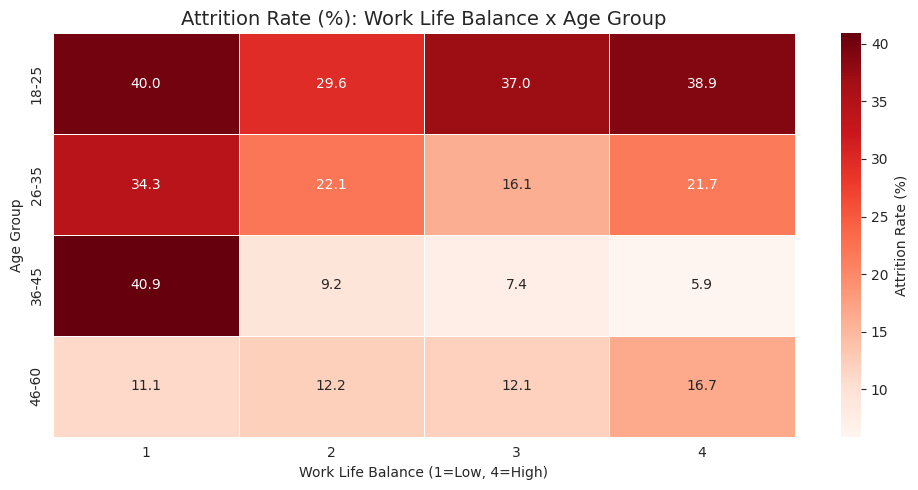


📌 Crosstab: Work Life Balance vs Attrition
Attrition          No  Yes   All
WorkLifeBalance                 
1                  55   25    80
2                 286   58   344
3                 766  127   893
4                 126   27   153
All              1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition          No   Yes
WorkLifeBalance            
1                68.8  31.2
2                83.1  16.9
3                85.8  14.2
4                82.4  17.6


In [ ]:
# ============================================
# EDA - KESEIMBANGAN PEKERJAAN: WORK LIFE BALANCE
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("WORK LIFE BALANCE - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Work Life Balance
wlb_counts = df['WorkLifeBalance'].value_counts().sort_index()
print("\n📌 Distribusi Work Life Balance:")
print(wlb_counts)
print(f"\nPersentase:")
print((wlb_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Work Life Balance
wlb_attrition = df.groupby('WorkLifeBalance')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Work Life Balance:")
print(wlb_attrition.round(2))

# 3. Plot Distribusi Work Life Balance
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='WorkLifeBalance', palette='Set2', order=sorted(df['WorkLifeBalance'].unique()))
plt.title('Distribusi Karyawan Berdasarkan Work Life Balance', fontsize=14)
plt.xlabel('Work Life Balance (1=Low, 4=High)')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot Attrition Rate per Work Life Balance
plt.figure(figsize=(8,5))
wlb_attrition.sort_index().plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue'])
plt.title('Attrition Rate per Work Life Balance', fontsize=14)
plt.xlabel('Work Life Balance (1=Low, 4=High)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(wlb_attrition) + 5)
for i, v in enumerate(wlb_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 5. WORK LIFE BALANCE PER DEPARTMENT
# ============================================

print("\n" + "="*50)
print("WORK LIFE BALANCE PER DEPARTMENT")
print("="*50)

wlb_dept = df.groupby('Department')['WorkLifeBalance'].mean().sort_values(ascending=False)
print("\n📌 Rata-rata Work Life Balance per Department:")
print(wlb_dept.round(2))

plt.figure(figsize=(8,5))
wlb_dept.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Rata-rata Work Life Balance per Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Rata-rata Work Life Balance')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, v in enumerate(wlb_dept):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 6. WORK LIFE BALANCE PER AGE GROUP
# ============================================

print("\n" + "="*50)
print("WORK LIFE BALANCE PER AGE GROUP")
print("="*50)

wlb_age = df.groupby('age_group')['WorkLifeBalance'].mean().sort_index()
print("\n📌 Rata-rata Work Life Balance per Age Group:")
print(wlb_age.round(2))

plt.figure(figsize=(8,5))
wlb_age.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold'])
plt.title('Rata-rata Work Life Balance per Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Rata-rata Work Life Balance')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, v in enumerate(wlb_age):
    plt.text(i, v + 0.05, f'{v:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 7. ATTRITION PER WORK LIFE BALANCE PER DEPARTMENT
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: WORK LIFE BALANCE x DEPARTMENT")
print("="*50)

pivot_dept_wlb = df.pivot_table(
    values='Attrition',
    index='Department',
    columns='WorkLifeBalance',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per Department x Work Life Balance:")
print(pivot_dept_wlb)

plt.figure(figsize=(10,5))
sns.heatmap(pivot_dept_wlb, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Work Life Balance x Department', fontsize=14)
plt.xlabel('Work Life Balance (1=Low, 4=High)')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

# ============================================
# 8. ATTRITION PER WORK LIFE BALANCE PER AGE GROUP
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: WORK LIFE BALANCE x AGE GROUP")
print("="*50)

pivot_age_wlb = df.pivot_table(
    values='Attrition',
    index='age_group',
    columns='WorkLifeBalance',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per Age Group x Work Life Balance:")
print(pivot_age_wlb)

plt.figure(figsize=(10,5))
sns.heatmap(pivot_age_wlb, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Work Life Balance x Age Group', fontsize=14)
plt.xlabel('Work Life Balance (1=Low, 4=High)')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

# ============================================
# 9. CROSSTAB (OPSIONAL)
# ============================================

print("\n📌 Crosstab: Work Life Balance vs Attrition")
crosstab_wlb = pd.crosstab(df['WorkLifeBalance'], df['Attrition'], margins=True)
print(crosstab_wlb)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_wlb_pct = pd.crosstab(df['WorkLifeBalance'], df['Attrition'], normalize='index') * 100
print(crosstab_wlb_pct.round(1))

## Analisa Berdasarkan Income

Kita lihat bagaimana persebaran data berdasarkan income secara statistik, persentase, dan juga visualisasi. Disini kita juga akan mengkombinasikan income dengan beberapa fitur lainnya

MONTHLY INCOME - DISTRIBUSI & ATTRITION

📌 Statistik Monthly Income:
count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

📌 Distribusi Income Group:
income_group
Q1 (Terendah)     369
Q2                366
Q3                367
Q4 (Tertinggi)    368
Name: count, dtype: int64

Persentase:
income_group
Q1 (Terendah)     25.1
Q2                24.9
Q3                25.0
Q4 (Tertinggi)    25.0
Name: count, dtype: float64

📌 Attrition Rate per Income Group:
income_group
Q1 (Terendah)     29.27
Q2                14.21
Q3                10.63
Q4 (Tertinggi)    10.33
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/1235861573.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_attrition = df.groupby('income_group')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
/tmp/ipykernel_3120/1235861573.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='income_group', palette='Set2',


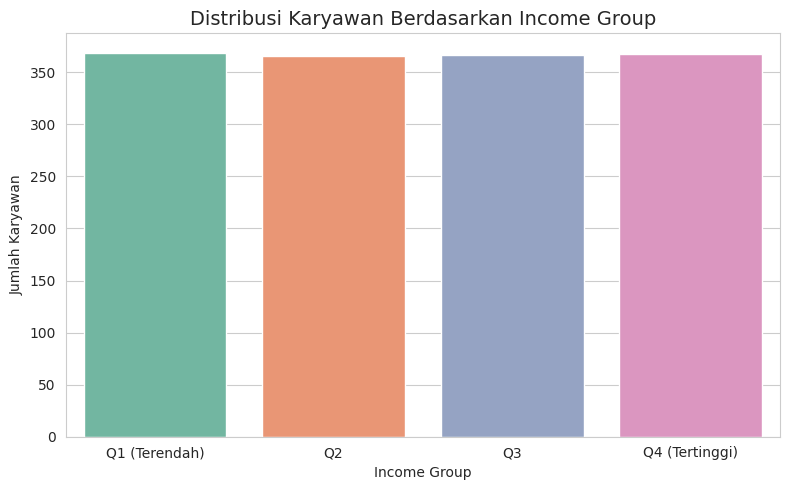

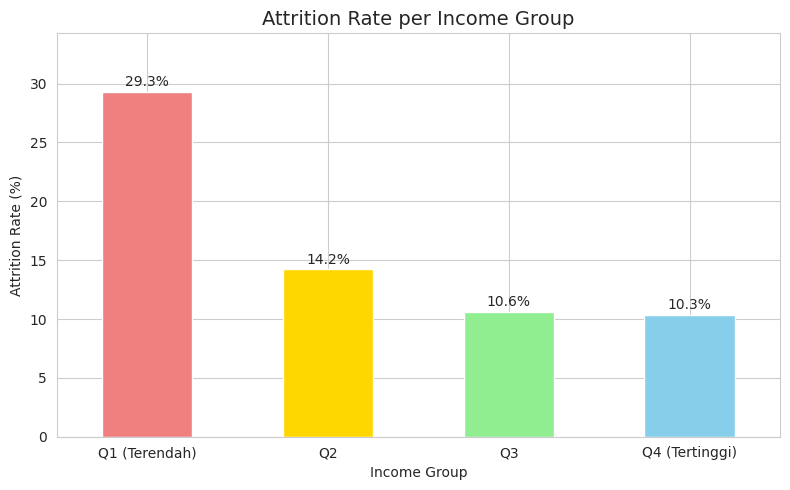

RENTANG GAJI PER INCOME GROUP

📌 Rentang Gaji per Income Group:
                 min    max     mean
income_group                        
Q1 (Terendah)   1009   2911   2354.0
Q2              2926   4908   3964.0
Q3              4930   8376   6182.0
Q4 (Tertinggi)  8380  19999  13508.0

RATA-RATA INCOME PER DEPARTMENT

📌 Rata-rata Monthly Income per Department:
Department
Sales                     6959.0
Human Resources           6655.0
Research & Development    6281.0
Name: MonthlyIncome, dtype: float64


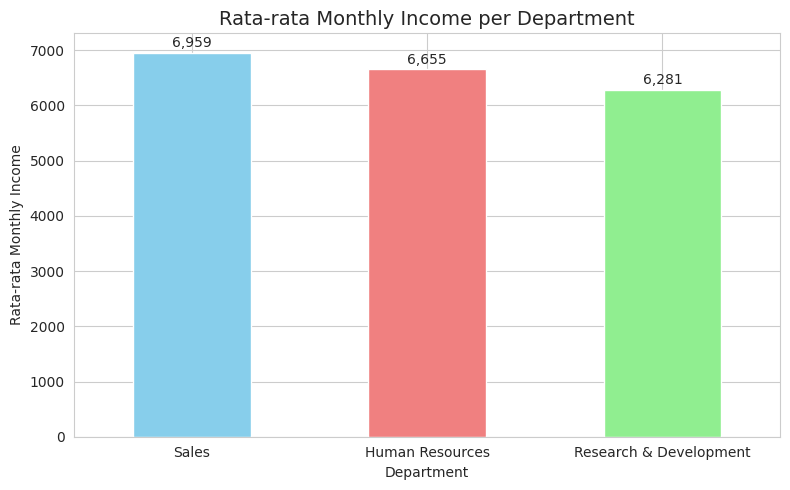


RATA-RATA INCOME PER JOB SATISFACTION

📌 Rata-rata Monthly Income per Job Satisfaction:
JobSatisfaction
1    6562.0
2    6527.0
3    6480.0
4    6473.0
Name: MonthlyIncome, dtype: float64


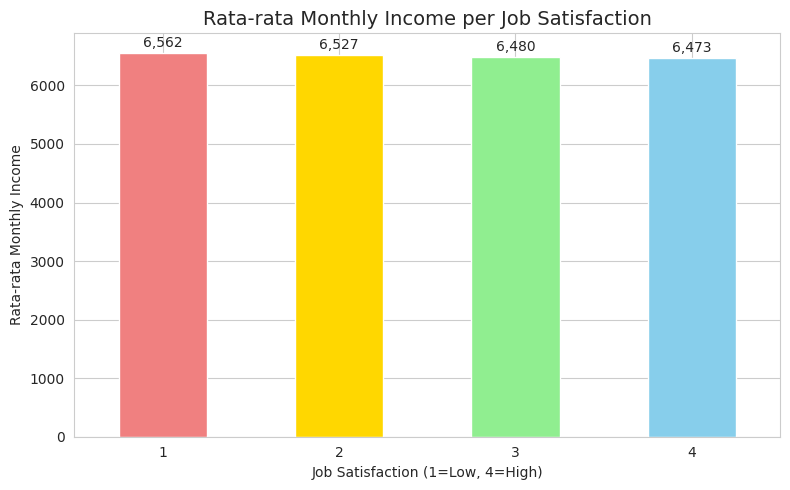


RATA-RATA INCOME PER WORK LIFE BALANCE

📌 Rata-rata Monthly Income per Work Life Balance:
WorkLifeBalance
1    5887.0
2    6462.0
3    6532.0
4    6746.0
Name: MonthlyIncome, dtype: float64


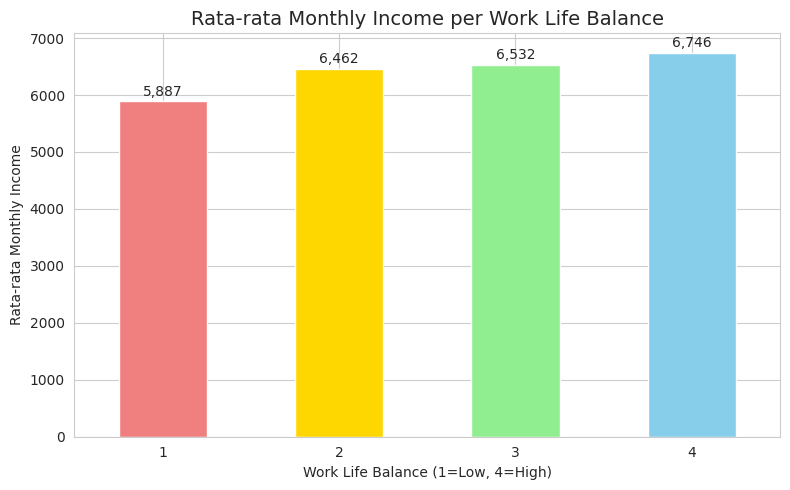


RATA-RATA INCOME PER EDUCATION

📌 Rata-rata Monthly Income per Education Level:
Education
1    5641.0
2    6227.0
3    6517.0
4    6832.0
5    8278.0
Name: MonthlyIncome, dtype: float64


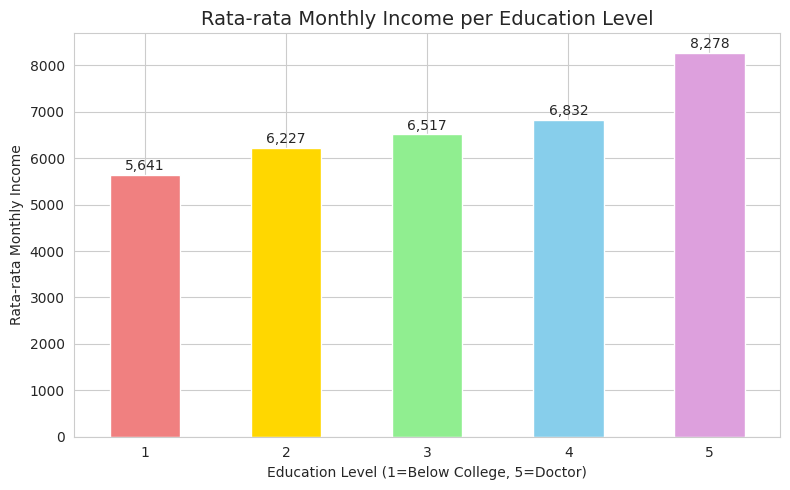


RATA-RATA INCOME PER EDUCATION FIELD

📌 Rata-rata Monthly Income per Education Field:
EducationField
Marketing           7349.0
Human Resources     7241.0
Medical             6510.0
Life Sciences       6463.0
Other               6072.0
Technical Degree    5758.0
Name: MonthlyIncome, dtype: float64


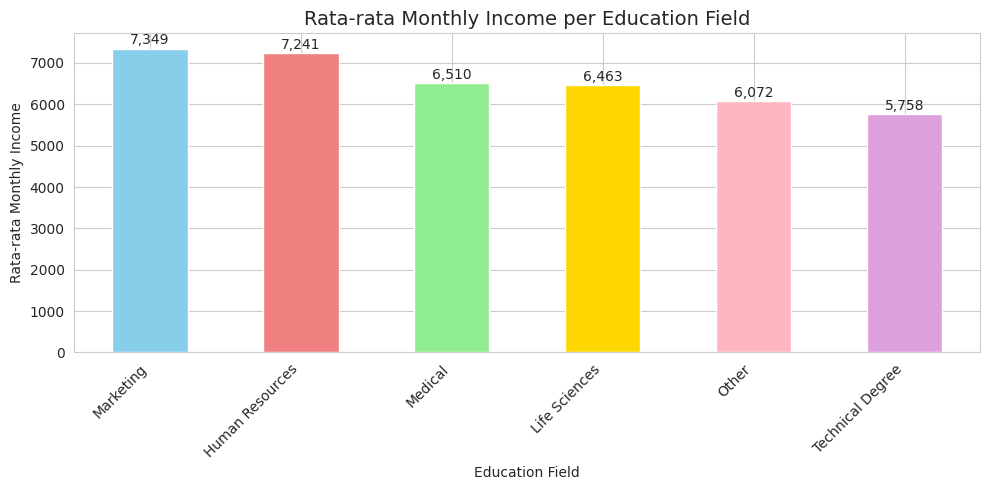


RATA-RATA INCOME PER AGE GROUP

📌 Rata-rata Monthly Income per Age Group:
age_group
18-25     2973.0
26-35     4896.0
36-45     7104.0
46-60    10630.0
Name: MonthlyIncome, dtype: float64


/tmp/ipykernel_3120/1235861573.py:185: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_age = df.groupby('age_group')['MonthlyIncome'].mean().sort_index()


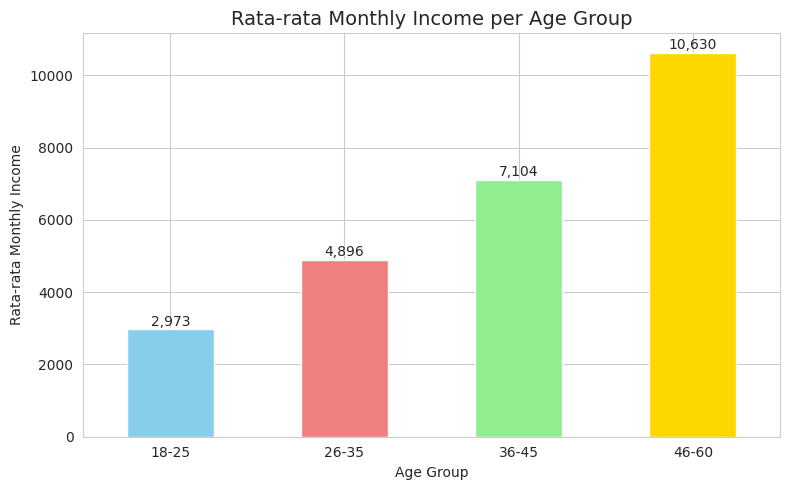


RATA-RATA INCOME PER TENURE GROUP

📌 Rata-rata Monthly Income per Tenure Group:
tenure_group
<1 year        4565.0
1-3 years      5017.0
3-5 years      5484.0
5-10 years     6567.0
10+ years     10887.0
Name: MonthlyIncome, dtype: float64


/tmp/ipykernel_3120/1235861573.py:208: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_tenure = df.groupby('tenure_group')['MonthlyIncome'].mean().sort_index()


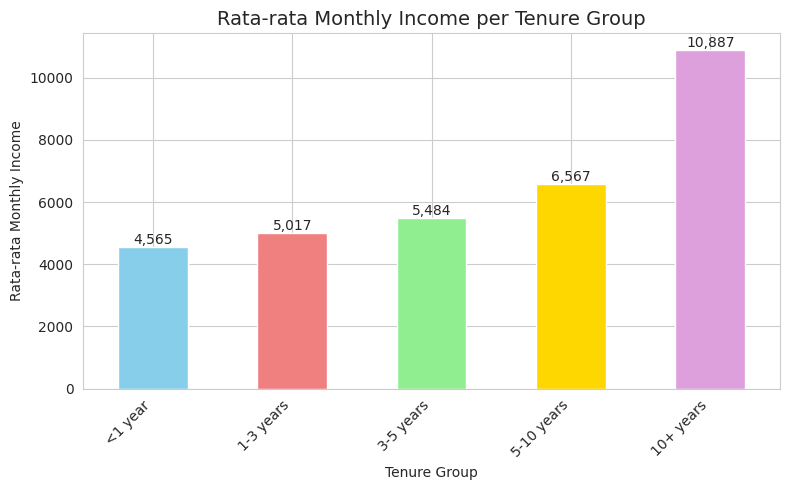


📌 Crosstab: Income Group vs Attrition
Attrition         No  Yes   All
income_group                   
Q1 (Terendah)    261  108   369
Q2               314   52   366
Q3               328   39   367
Q4 (Tertinggi)   330   38   368
All             1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition         No   Yes
income_group              
Q1 (Terendah)   70.7  29.3
Q2              85.8  14.2
Q3              89.4  10.6
Q4 (Tertinggi)  89.7  10.3


In [ ]:
# ============================================
# EDA - KOMPENSASI: MONTHLY INCOME
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("MONTHLY INCOME - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Monthly Income (numerik)
print("\n📌 Statistik Monthly Income:")
print(df['MonthlyIncome'].describe())

# 2. Distribusi Income Group
income_counts = df['income_group'].value_counts().sort_index()
print("\n📌 Distribusi Income Group:")
print(income_counts)
print(f"\nPersentase:")
print((income_counts / len(df) * 100).round(1).sort_index())

# 3. Attrition Rate per Income Group
income_attrition = df.groupby('income_group')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Income Group:")
print(income_attrition.round(2))

# 4. Plot Distribusi Income Group
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='income_group', palette='Set2',
              order=['Q1 (Terendah)', 'Q2', 'Q3', 'Q4 (Tertinggi)'])
plt.title('Distribusi Karyawan Berdasarkan Income Group', fontsize=14)
plt.xlabel('Income Group')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 5. Plot Attrition Rate per Income Group
plt.figure(figsize=(8,5))
income_attrition.sort_index().plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue'])
plt.title('Attrition Rate per Income Group', fontsize=14)
plt.xlabel('Income Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(income_attrition) + 5)
for i, v in enumerate(income_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 5.b RENTANG GAJI PER INCOME GROUP
# ============================================

print("="*50)
print("RENTANG GAJI PER INCOME GROUP")
print("="*50)

print("\n📌 Rentang Gaji per Income Group:")
print(df.groupby('income_group', observed=True)['MonthlyIncome'].agg(['min', 'max', 'mean']).round(0))

# ============================================
# 6. INCOME x DEPARTMENT
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER DEPARTMENT")
print("="*50)

income_dept = df.groupby('Department')['MonthlyIncome'].mean().sort_values(ascending=False)
print("\n📌 Rata-rata Monthly Income per Department:")
print(income_dept.round(0))

plt.figure(figsize=(8,5))
income_dept.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Rata-rata Monthly Income per Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=0)
for i, v in enumerate(income_dept):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 7. INCOME x JOB SATISFACTION
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER JOB SATISFACTION")
print("="*50)

income_jobsat = df.groupby('JobSatisfaction')['MonthlyIncome'].mean().sort_index()
print("\n📌 Rata-rata Monthly Income per Job Satisfaction:")
print(income_jobsat.round(0))

plt.figure(figsize=(8,5))
income_jobsat.plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue'])
plt.title('Rata-rata Monthly Income per Job Satisfaction', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=0)
for i, v in enumerate(income_jobsat):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 8. INCOME x WORK LIFE BALANCE
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER WORK LIFE BALANCE")
print("="*50)

income_wlb = df.groupby('WorkLifeBalance')['MonthlyIncome'].mean().sort_index()
print("\n📌 Rata-rata Monthly Income per Work Life Balance:")
print(income_wlb.round(0))

plt.figure(figsize=(8,5))
income_wlb.plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue'])
plt.title('Rata-rata Monthly Income per Work Life Balance', fontsize=14)
plt.xlabel('Work Life Balance (1=Low, 4=High)')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=0)
for i, v in enumerate(income_wlb):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 9. INCOME x EDUCATION
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER EDUCATION")
print("="*50)

income_edu = df.groupby('Education')['MonthlyIncome'].mean().sort_index()
print("\n📌 Rata-rata Monthly Income per Education Level:")
print(income_edu.round(0))

plt.figure(figsize=(8,5))
income_edu.plot(kind='bar', color=['lightcoral', 'gold', 'lightgreen', 'skyblue', 'plum'])
plt.title('Rata-rata Monthly Income per Education Level', fontsize=14)
plt.xlabel('Education Level (1=Below College, 5=Doctor)')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=0)
for i, v in enumerate(income_edu):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 10. INCOME x EDUCATION FIELD
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER EDUCATION FIELD")
print("="*50)

income_eduField = df.groupby('EducationField')['MonthlyIncome'].mean().sort_values(ascending=False)
print("\n📌 Rata-rata Monthly Income per Education Field:")
print(income_eduField.round(0))

plt.figure(figsize=(10,5))
income_eduField.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold', 'lightpink', 'plum'])
plt.title('Rata-rata Monthly Income per Education Field', fontsize=14)
plt.xlabel('Education Field')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=45, ha='right')
for i, v in enumerate(income_eduField):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 11. INCOME x AGE GROUP
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER AGE GROUP")
print("="*50)

income_age = df.groupby('age_group')['MonthlyIncome'].mean().sort_index()
print("\n📌 Rata-rata Monthly Income per Age Group:")
print(income_age.round(0))

plt.figure(figsize=(8,5))
income_age.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold'])
plt.title('Rata-rata Monthly Income per Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=0)
for i, v in enumerate(income_age):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 12. INCOME x TENURE GROUP
# ============================================

print("\n" + "="*50)
print("RATA-RATA INCOME PER TENURE GROUP")
print("="*50)

income_tenure = df.groupby('tenure_group')['MonthlyIncome'].mean().sort_index()
print("\n📌 Rata-rata Monthly Income per Tenure Group:")
print(income_tenure.round(0))

plt.figure(figsize=(8,5))
income_tenure.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen', 'gold', 'plum'])
plt.title('Rata-rata Monthly Income per Tenure Group', fontsize=14)
plt.xlabel('Tenure Group')
plt.ylabel('Rata-rata Monthly Income')
plt.xticks(rotation=45, ha='right')
for i, v in enumerate(income_tenure):
    plt.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 13. CROSSTAB
# ============================================

print("\n📌 Crosstab: Income Group vs Attrition")
crosstab_income = pd.crosstab(df['income_group'], df['Attrition'], margins=True)
print(crosstab_income)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_income_pct = pd.crosstab(df['income_group'], df['Attrition'], normalize='index') * 100
print(crosstab_income_pct.round(1))

## Analisa Jumlah perusahaan sebelumnya

Kita lihat bagaimana persebaran data berdasarkan income secara statistik, persentase, dan juga visualisasi. Disini kita juga akan mengkombinasikan fitur ini dengan beberapa fitur lainnya

NUM COMPANIES WORKED - DISTRIBUSI & ATTRITION

📌 Distribusi NumCompaniesWorked:
NumCompaniesWorked
0    197
1    521
2    146
3    159
4    139
5     63
6     70
7     74
8     49
9     52
Name: count, dtype: int64

Persentase:
NumCompaniesWorked
0    13.4
1    35.4
2     9.9
3    10.8
4     9.5
5     4.3
6     4.8
7     5.0
8     3.3
9     3.5
Name: count, dtype: float64

📌 Attrition Rate per NumCompaniesWorked:
NumCompaniesWorked
0    11.68
1    18.81
2    10.96
3    10.06
4    12.23
5    25.40
6    22.86
7    22.97
8    12.24
9    23.08
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/2760668798.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='NumCompaniesWorked', palette='Set2',


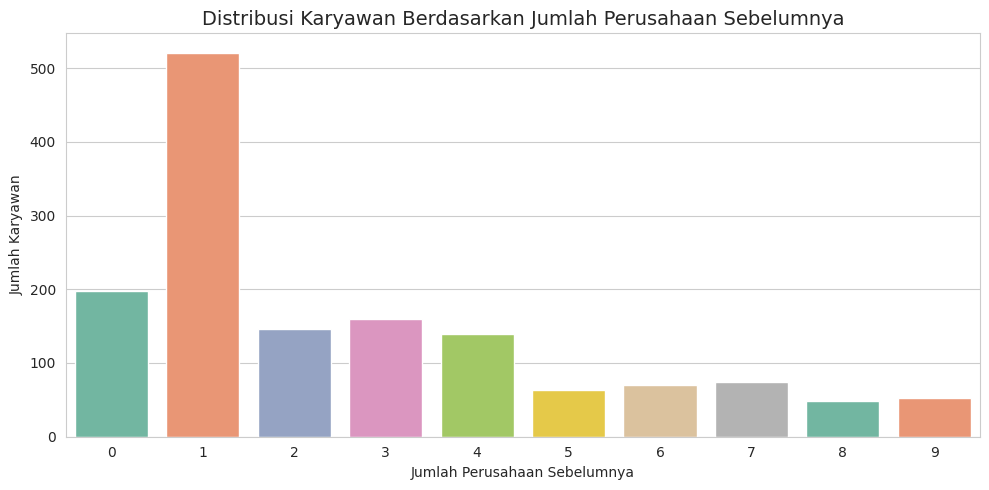

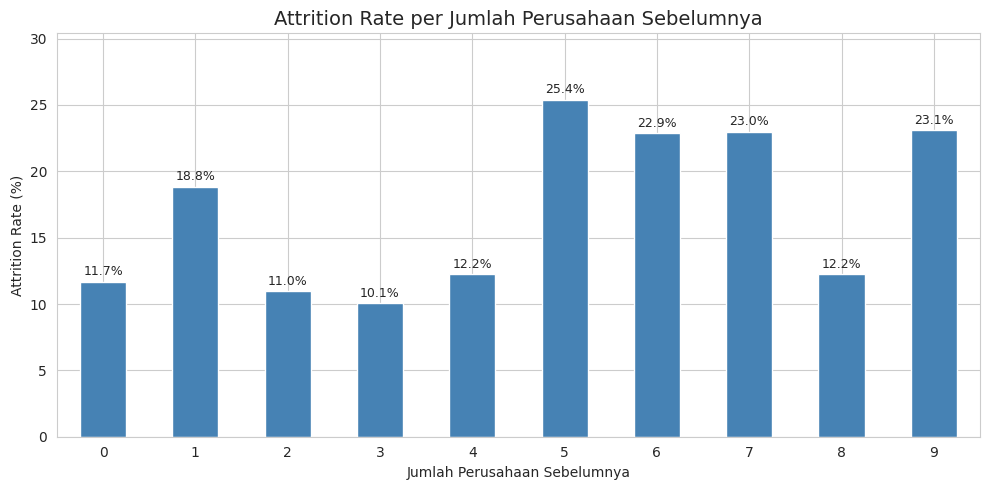


NUM COMPANIES WORKED x JOB SATISFACTION

📌 Attrition Rate (%) per NumCompaniesWorked x JobSatisfaction:
JobSatisfaction        1     2     3     4
NumCompaniesWorked                        
0                   23.7  11.4  11.9   4.6
1                   20.9  23.8  17.0  16.5
2                   16.7  16.7   9.1   4.8
3                   16.0   0.0  19.2   3.4
4                   17.9  14.8  12.8   6.7
5                   37.5  23.5  23.1  17.6
6                   40.0   6.2  25.0  20.0
7                   35.0  23.1  18.2  15.8
8                   10.0   0.0  23.1  15.4
9                   30.0  20.0  23.5  20.0


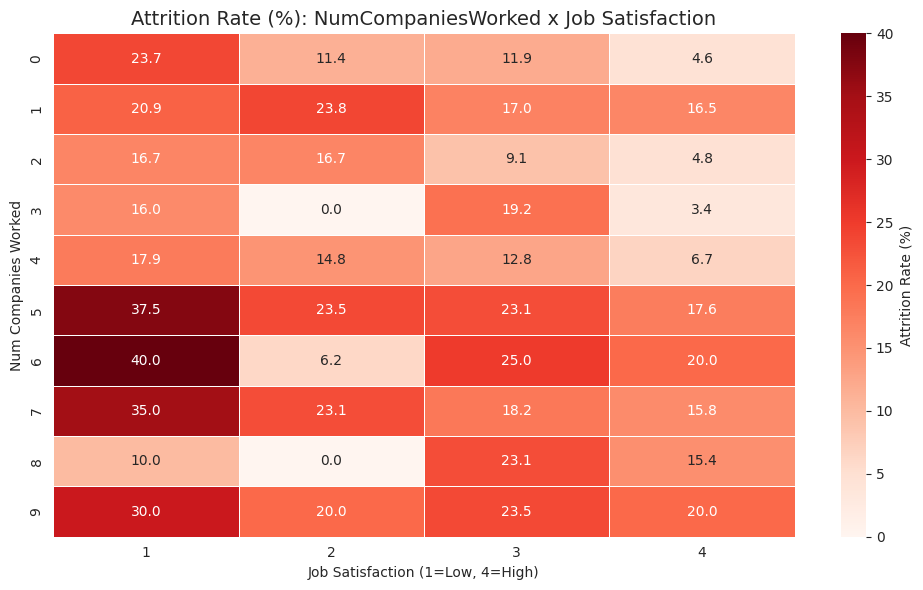


NUM COMPANIES WORKED x AGE GROUP

📌 Attrition Rate (%) per NumCompaniesWorked x Age Group:
age_group           18-25  26-35  36-45  46-60
NumCompaniesWorked                            
0                    16.7   14.5    5.5    7.1
1                    40.2   16.3    7.9   21.9
2                    33.3   17.1    9.1    6.0
3                    33.3   18.2    6.5    6.0
4                     0.0   17.2    8.8   15.0
5                   100.0   39.1   13.0   13.3
6                     0.0   41.7   14.8   11.8
7                     0.0   42.1   16.1   17.4
8                     0.0   20.0   13.3    5.6
9                   100.0   21.1   11.1   35.7


/tmp/ipykernel_3120/2760668798.py:82: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_ncomp_age = df.pivot_table(


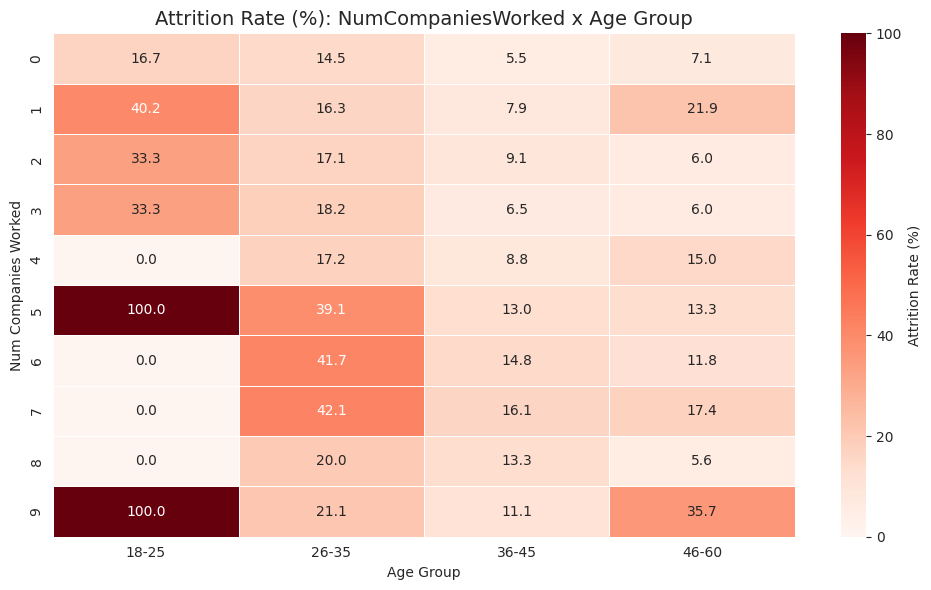


NUM COMPANIES WORKED x INCOME GROUP

📌 Attrition Rate (%) per NumCompaniesWorked x Income Group:
income_group        Q1 (Terendah)    Q2    Q3  Q4 (Tertinggi)
NumCompaniesWorked                                           
0                            16.0  14.7   5.1             7.5
1                            32.5  11.3   9.6            12.2
2                            15.0  19.4   7.0             7.7
3                            20.0  20.6   5.3             3.2
4                            21.9   4.0  11.9            10.0
5                            50.0  21.1  27.8            12.5
6                            47.1  16.7  15.0            14.3
7                            62.5  21.1   9.5            23.1
8                            11.1   8.3  23.5             0.0
9                            57.1  15.4  14.3            22.2


/tmp/ipykernel_3120/2760668798.py:109: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_ncomp_income = df.pivot_table(


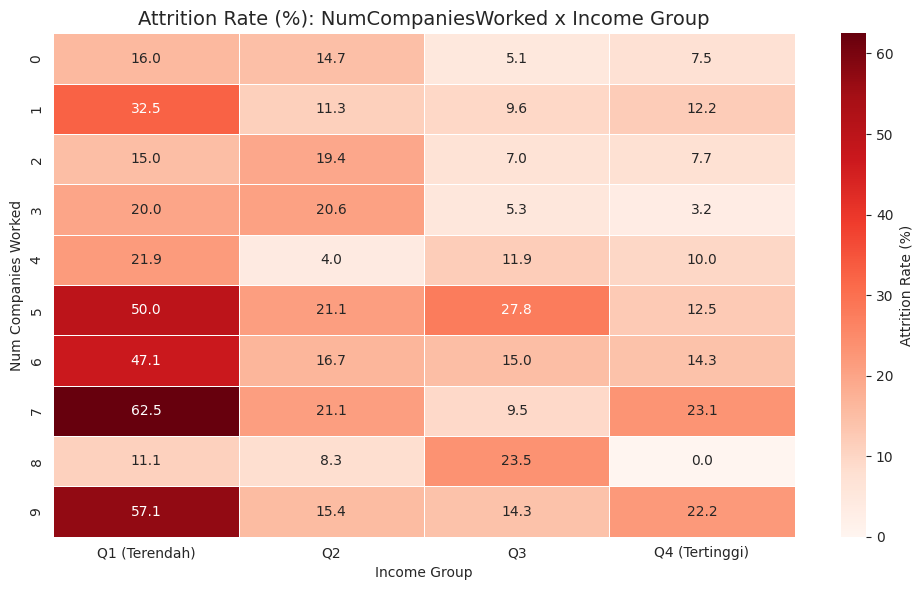


📌 Crosstab: NumCompaniesWorked vs Attrition
Attrition             No  Yes   All
NumCompaniesWorked                 
0                    174   23   197
1                    423   98   521
2                    130   16   146
3                    143   16   159
4                    122   17   139
5                     47   16    63
6                     54   16    70
7                     57   17    74
8                     43    6    49
9                     40   12    52
All                 1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition             No   Yes
NumCompaniesWorked            
0                   88.3  11.7
1                   81.2  18.8
2                   89.0  11.0
3                   89.9  10.1
4                   87.8  12.2
5                   74.6  25.4
6                   77.1  22.9
7                   77.0  23.0
8                   87.8  12.2
9                   76.9  23.1


In [ ]:
# ============================================
# EDA - KOMPENSASI & PENGALAMAN: NUM COMPANIES WORKED
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("NUM COMPANIES WORKED - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi NumCompaniesWorked
ncomp_counts = df['NumCompaniesWorked'].value_counts().sort_index()
print("\n📌 Distribusi NumCompaniesWorked:")
print(ncomp_counts)
print(f"\nPersentase:")
print((ncomp_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per NumCompaniesWorked
ncomp_attrition = df.groupby('NumCompaniesWorked')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per NumCompaniesWorked:")
print(ncomp_attrition.round(2))

# 3. Plot Distribusi NumCompaniesWorked
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='NumCompaniesWorked', palette='Set2',
              order=sorted(df['NumCompaniesWorked'].unique()))
plt.title('Distribusi Karyawan Berdasarkan Jumlah Perusahaan Sebelumnya', fontsize=14)
plt.xlabel('Jumlah Perusahaan Sebelumnya')
plt.ylabel('Jumlah Karyawan')
plt.tight_layout()
plt.show()

# 4. Plot Attrition Rate per NumCompaniesWorked
plt.figure(figsize=(10,5))
ncomp_attrition.sort_index().plot(kind='bar', color='steelblue')
plt.title('Attrition Rate per Jumlah Perusahaan Sebelumnya', fontsize=14)
plt.xlabel('Jumlah Perusahaan Sebelumnya')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(ncomp_attrition) + 5)
for i, v in enumerate(ncomp_attrition.sort_index()):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 5. NUM COMPANIES WORKED x JOB SATISFACTION
# ============================================

print("\n" + "="*50)
print("NUM COMPANIES WORKED x JOB SATISFACTION")
print("="*50)

pivot_ncomp_jobsat = df.pivot_table(
    values='Attrition',
    index='NumCompaniesWorked',
    columns='JobSatisfaction',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per NumCompaniesWorked x JobSatisfaction:")
print(pivot_ncomp_jobsat)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_ncomp_jobsat, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): NumCompaniesWorked x Job Satisfaction', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Num Companies Worked')
plt.tight_layout()
plt.show()

# ============================================
# 6. NUM COMPANIES WORKED x AGE GROUP
# ============================================

print("\n" + "="*50)
print("NUM COMPANIES WORKED x AGE GROUP")
print("="*50)

pivot_ncomp_age = df.pivot_table(
    values='Attrition',
    index='NumCompaniesWorked',
    columns='age_group',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per NumCompaniesWorked x Age Group:")
print(pivot_ncomp_age)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_ncomp_age, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): NumCompaniesWorked x Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Num Companies Worked')
plt.tight_layout()
plt.show()

# ============================================
# 7. NUM COMPANIES WORKED x INCOME GROUP
# ============================================

print("\n" + "="*50)
print("NUM COMPANIES WORKED x INCOME GROUP")
print("="*50)

pivot_ncomp_income = df.pivot_table(
    values='Attrition',
    index='NumCompaniesWorked',
    columns='income_group',
    aggfunc=lambda x: (x == 'Yes').mean() * 100
).round(1)

print("\n📌 Attrition Rate (%) per NumCompaniesWorked x Income Group:")
print(pivot_ncomp_income)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_ncomp_income, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): NumCompaniesWorked x Income Group', fontsize=14)
plt.xlabel('Income Group')
plt.ylabel('Num Companies Worked')
plt.tight_layout()
plt.show()

# ============================================
# 8. CROSSTAB
# ============================================

print("\n📌 Crosstab: NumCompaniesWorked vs Attrition")
crosstab_ncomp = pd.crosstab(df['NumCompaniesWorked'], df['Attrition'], margins=True)
print(crosstab_ncomp)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_ncomp_pct = pd.crosstab(df['NumCompaniesWorked'], df['Attrition'], normalize='index') * 100
print(crosstab_ncomp_pct.round(1))

## Analisa Masa Kerja

Kita lihat bagaimana persebaran data berdasarkan masa kerja secara statistik, persentase, dan juga visualisasi. Disini kita juga akan mengkombinasikan income dengan beberapa fitur lainnya

YEARS AT COMPANY (TENURE) - DISTRIBUSI & ATTRITION

📌 Distribusi Tenure Group:
tenure_group
<1 year       215
1-3 years     255
3-5 years     306
5-10 years    448
10+ years     246
Name: count, dtype: int64

Persentase:
tenure_group
<1 year       14.6
1-3 years     17.3
3-5 years     20.8
5-10 years    30.5
10+ years     16.7
Name: count, dtype: float64

📌 Attrition Rate per Tenure Group:
tenure_group
<1 year       34.88
1-3 years     18.43
3-5 years     13.07
5-10 years    12.28
10+ years      8.13
Name: Attrition, dtype: float64


/tmp/ipykernel_3120/587133644.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='tenure_group', palette='Set2',


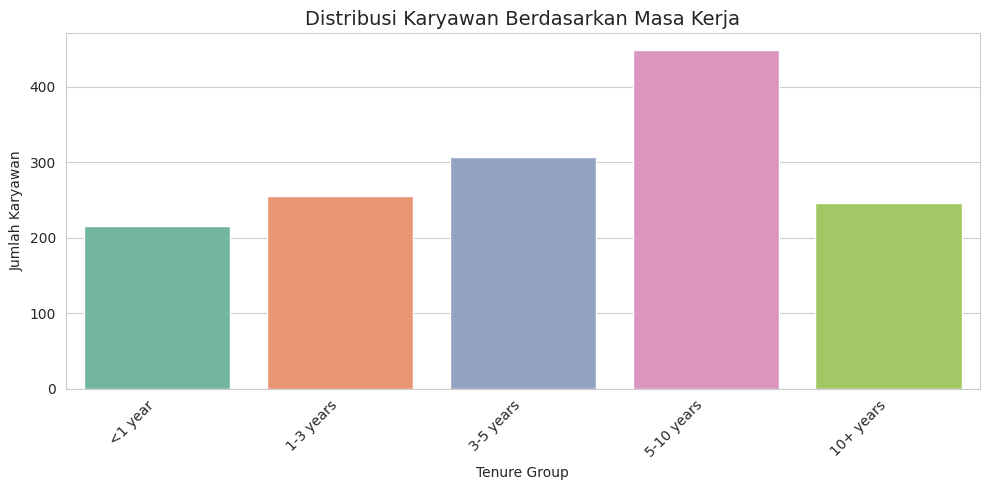

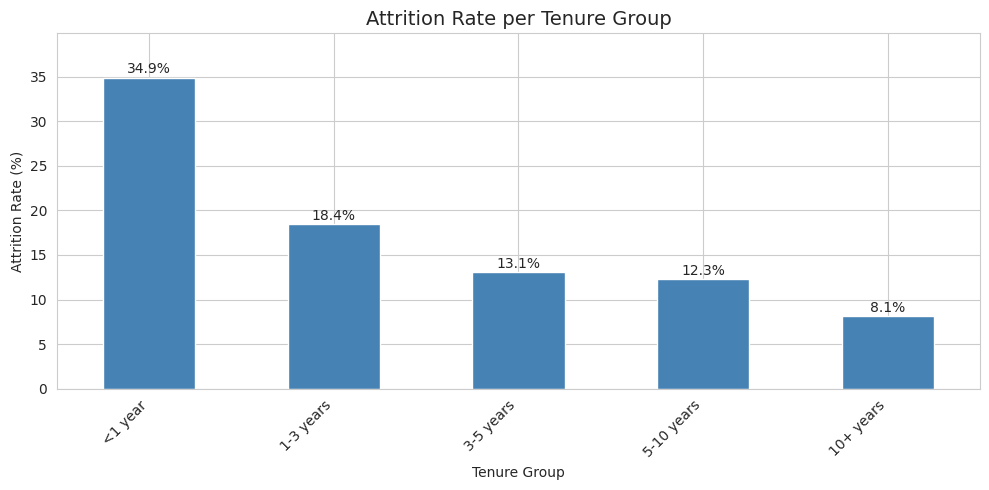


ATTRITION RATE: TENURE GROUP x JOB SATISFACTION

📌 Attrition Rate (%) per Tenure x Job Satisfaction:
JobSatisfaction     1     2     3     4
tenure_group                           
<1 year          46.5  36.4  35.9  25.0
1-3 years        30.0  17.8  20.5   9.1
3-5 years        20.6  16.9   9.6   8.9
5-10 years       15.1  11.0  15.0   9.2
10+ years        10.6   6.0   6.8   9.3


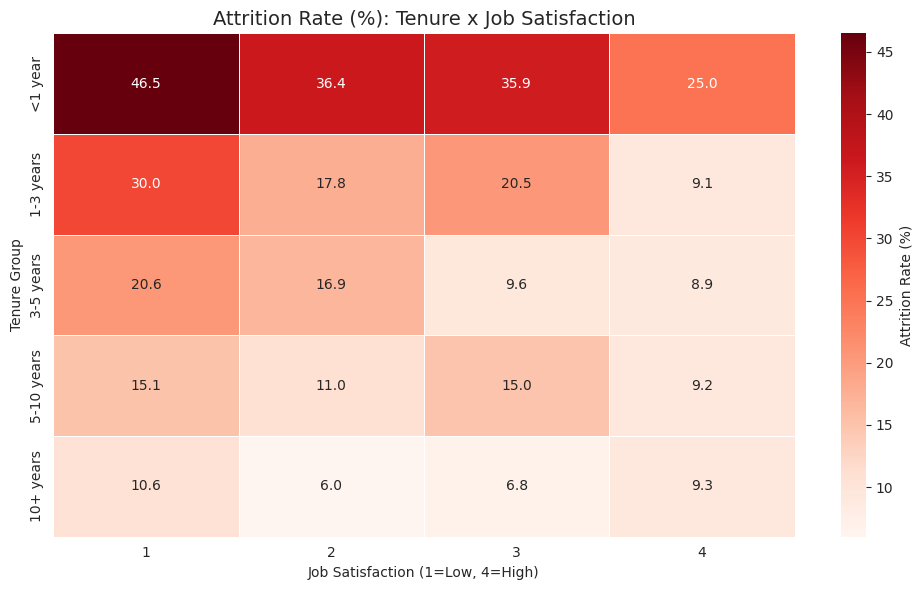


ATTRITION RATE: TENURE GROUP x INCOME GROUP

📌 Attrition Rate (%) per Tenure x Income Group:
income_group  Q1 (Terendah)    Q2    Q3  Q4 (Tertinggi)
tenure_group                                           
<1 year                47.3  27.9  18.8            14.3
1-3 years              24.8  16.2  10.3            14.3
3-5 years              16.9  14.3  11.3             6.4
5-10 years             23.8   8.9  11.4            10.2
10+ years              10.0   8.1   2.0            10.0


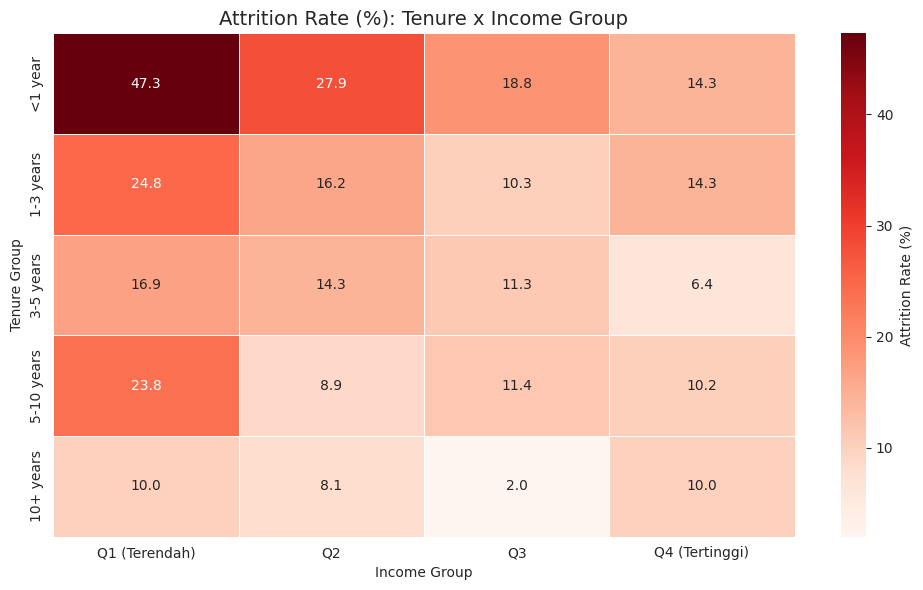


ATTRITION RATE: TENURE GROUP x DEPARTMENT

📌 Attrition Rate (%) per Tenure x Department:
Department    Human Resources  Research & Development  Sales
tenure_group                                                
<1 year                  80.0                    31.5   39.3
1-3 years                25.0                    13.0   28.6
3-5 years                13.3                    11.5   17.1
5-10 years                5.6                    11.9   13.9
10+ years                11.1                     4.5   14.6


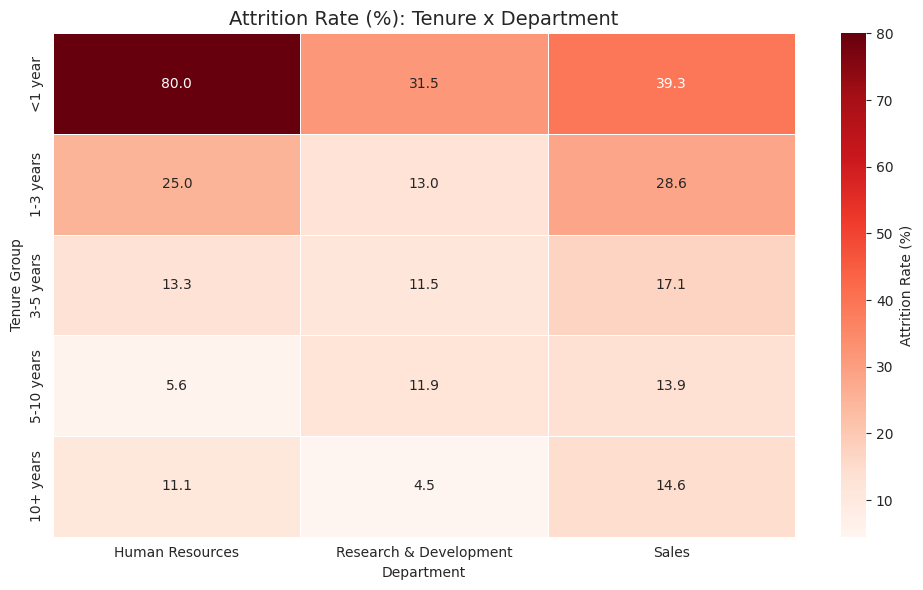


ATTRITION RATE: TENURE GROUP x AGE GROUP

📌 Attrition Rate (%) per Tenure x Age Group:
age_group     18-25  26-35  36-45  46-60
tenure_group                            
<1 year        62.2   39.7   19.7   15.4
1-3 years      25.6   25.2    8.6    7.0
3-5 years       8.0   16.2   10.1   12.5
5-10 years     30.0   14.0    5.1   17.5
10+ years       NaN    9.4    7.0    8.8


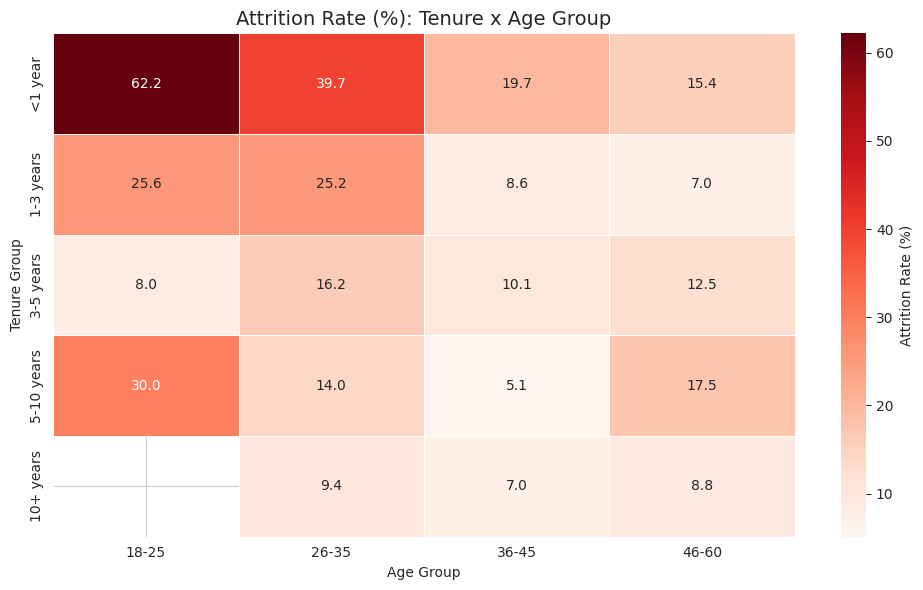


ATTRITION RATE: TENURE GROUP x DISTANCE GROUP

📌 Attrition Rate (%) per Tenure x Distance Group:
distance_group  Near (<5)  Medium (5-15)  Far (>15)
tenure_group                                       
<1 year              30.4           30.1       50.0
1-3 years            17.4           20.0       18.5
3-5 years             5.6           15.9       22.4
5-10 years           12.1           12.7       12.0
10+ years             8.1            7.1       10.0


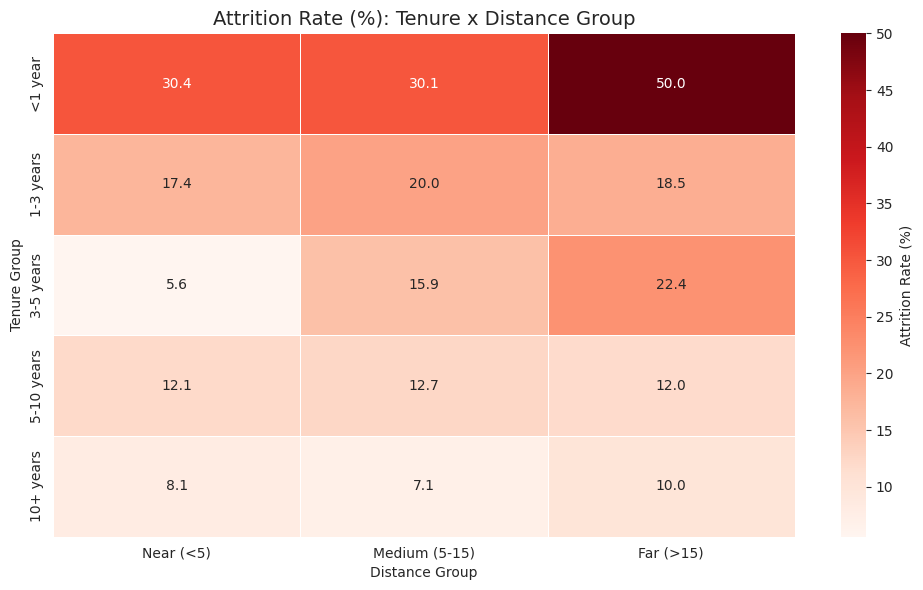


📌 Crosstab: Tenure Group vs Attrition
Attrition       No  Yes   All
tenure_group                 
<1 year        140   75   215
1-3 years      208   47   255
3-5 years      266   40   306
5-10 years     393   55   448
10+ years      226   20   246
All           1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition       No   Yes
tenure_group            
<1 year       65.1  34.9
1-3 years     81.6  18.4
3-5 years     86.9  13.1
5-10 years    87.7  12.3
10+ years     91.9   8.1


In [ ]:
# ============================================
# EDA - KOMPENSASI & PENGALAMAN: YEARS AT COMPANY (TENURE)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("YEARS AT COMPANY (TENURE) - DISTRIBUSI & ATTRITION")
print("="*50)

# 1. Distribusi Tenure Group
tenure_counts = df['tenure_group'].value_counts().sort_index()
print("\n📌 Distribusi Tenure Group:")
print(tenure_counts)
print(f"\nPersentase:")
print((tenure_counts / len(df) * 100).round(1).sort_index())

# 2. Attrition Rate per Tenure Group
tenure_attrition = df.groupby('tenure_group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Tenure Group:")
print(tenure_attrition.round(2))

# 3. Plot Distribusi Tenure Group
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='tenure_group', palette='Set2',
              order=['<1 year', '1-3 years', '3-5 years', '5-10 years', '10+ years'])
plt.title('Distribusi Karyawan Berdasarkan Masa Kerja', fontsize=14)
plt.xlabel('Tenure Group')
plt.ylabel('Jumlah Karyawan')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Plot Attrition Rate per Tenure Group
plt.figure(figsize=(10,5))
tenure_attrition.plot(kind='bar', color='steelblue')
plt.title('Attrition Rate per Tenure Group', fontsize=14)
plt.xlabel('Tenure Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, max(tenure_attrition) + 5)
for i, v in enumerate(tenure_attrition):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 5. TENURE x JOB SATISFACTION
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: TENURE GROUP x JOB SATISFACTION")
print("="*50)

pivot_tenure_jobsat = df.pivot_table(
    values='Attrition',
    index='tenure_group',
    columns='JobSatisfaction',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=True
).round(1)

print("\n📌 Attrition Rate (%) per Tenure x Job Satisfaction:")
print(pivot_tenure_jobsat)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_tenure_jobsat, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Tenure x Job Satisfaction', fontsize=14)
plt.xlabel('Job Satisfaction (1=Low, 4=High)')
plt.ylabel('Tenure Group')
plt.tight_layout()
plt.show()

# ============================================
# 6. TENURE x INCOME GROUP
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: TENURE GROUP x INCOME GROUP")
print("="*50)

pivot_tenure_income = df.pivot_table(
    values='Attrition',
    index='tenure_group',
    columns='income_group',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=True
).round(1)

print("\n📌 Attrition Rate (%) per Tenure x Income Group:")
print(pivot_tenure_income)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_tenure_income, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Tenure x Income Group', fontsize=14)
plt.xlabel('Income Group')
plt.ylabel('Tenure Group')
plt.tight_layout()
plt.show()

# ============================================
# 7. TENURE x DEPARTMENT
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: TENURE GROUP x DEPARTMENT")
print("="*50)

pivot_tenure_dept = df.pivot_table(
    values='Attrition',
    index='tenure_group',
    columns='Department',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=True
).round(1)

print("\n📌 Attrition Rate (%) per Tenure x Department:")
print(pivot_tenure_dept)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_tenure_dept, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Tenure x Department', fontsize=14)
plt.xlabel('Department')
plt.ylabel('Tenure Group')
plt.tight_layout()
plt.show()

# ============================================
# 8. TENURE x AGE GROUP
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: TENURE GROUP x AGE GROUP")
print("="*50)

pivot_tenure_age = df.pivot_table(
    values='Attrition',
    index='tenure_group',
    columns='age_group',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=True
).round(1)

print("\n📌 Attrition Rate (%) per Tenure x Age Group:")
print(pivot_tenure_age)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_tenure_age, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Tenure x Age Group', fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Tenure Group')
plt.tight_layout()
plt.show()

# ============================================
# 9. TENURE x DISTANCE GROUP
# ============================================

print("\n" + "="*50)
print("ATTRITION RATE: TENURE GROUP x DISTANCE GROUP")
print("="*50)

pivot_tenure_distance = df.pivot_table(
    values='Attrition',
    index='tenure_group',
    columns='distance_group',
    aggfunc=lambda x: (x == 'Yes').mean() * 100,
    observed=True
).round(1)

print("\n📌 Attrition Rate (%) per Tenure x Distance Group:")
print(pivot_tenure_distance)

plt.figure(figsize=(10,6))
sns.heatmap(pivot_tenure_distance, annot=True, cmap='Reds', fmt='.1f',
            linewidths=0.5, cbar_kws={'label': 'Attrition Rate (%)'})
plt.title('Attrition Rate (%): Tenure x Distance Group', fontsize=14)
plt.xlabel('Distance Group')
plt.ylabel('Tenure Group')
plt.tight_layout()
plt.show()

# ============================================
# 10. CROSSTAB
# ============================================

print("\n📌 Crosstab: Tenure Group vs Attrition")
crosstab_tenure = pd.crosstab(df['tenure_group'], df['Attrition'], margins=True)
print(crosstab_tenure)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_tenure_pct = pd.crosstab(df['tenure_group'], df['Attrition'], normalize='index') * 100
print(crosstab_tenure_pct.round(1))

## Analisa karyawan baru yang berusia lebih tua

Kita lihat bagaimana persebaran data pada karyawan baru yg berusia lebih tua secara statistik, persentase, dan juga visualisasi. Disini kita juga akan mengkombinasikan income dengan beberapa fitur lainnya

IS OLD BUT NEW - ANALISIS

📌 Distribusi is_old_but_new:
is_old_but_new
0    1380
1      90
Name: count, dtype: int64

Persentase:
is_old_but_new
0    93.9
1     6.1
Name: count, dtype: float64

📌 Total karyawan 'old but new': 90 orang

ATTRITION RATE: OLD BUT NEW vs BUKAN

📌 Attrition Rate:
is_old_but_new
0    16.45
1    11.11
Name: Attrition, dtype: float64


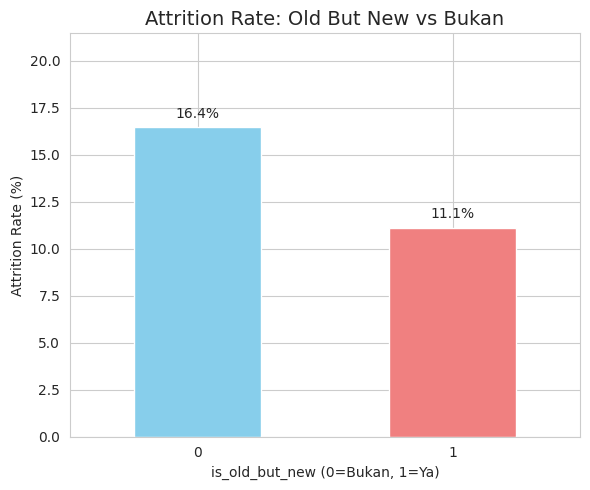


OLD BUT NEW x DEPARTMENT

📌 Distribusi Department (old but new):
Department
Research & Development    61
Sales                     26
Human Resources            3
Name: count, dtype: int64

Persentase:
Department
Research & Development    67.8
Sales                     28.9
Human Resources            3.3
Name: count, dtype: float64

📌 Attrition Rate per Department (old but new):
Department
Human Resources            0.00
Research & Development    11.48
Sales                     11.54
Name: Attrition, dtype: float64


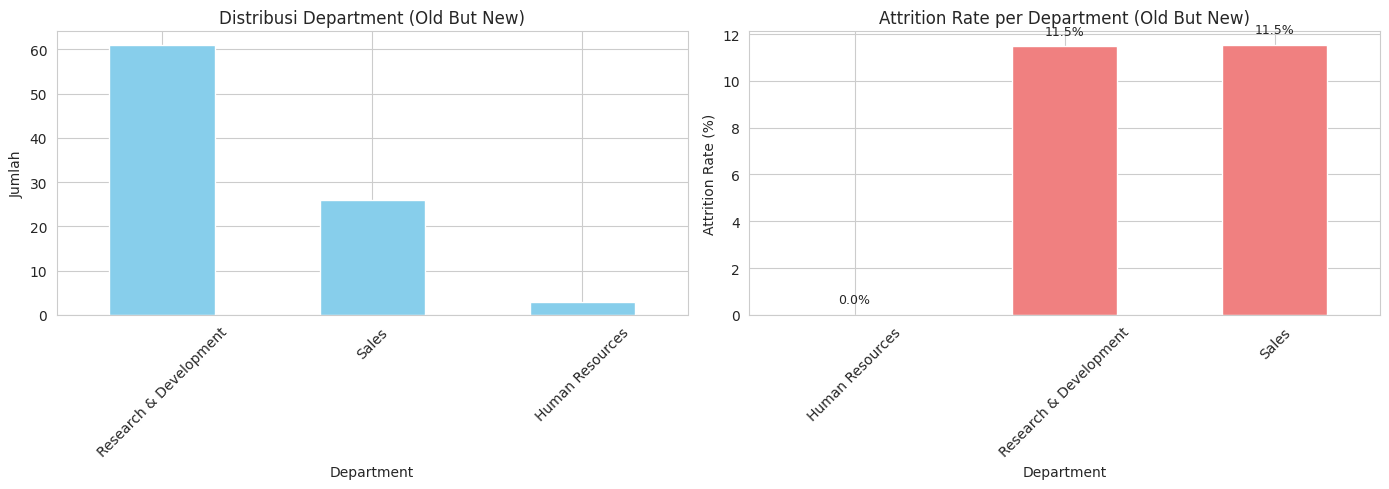


OLD BUT NEW x EDUCATION

📌 Distribusi Education (old but new):
Education
1     7
2    14
3    38
4    26
5     5
Name: count, dtype: int64

📌 Attrition Rate per Education (old but new):
Education
1    14.29
2    14.29
3    10.53
4    11.54
5     0.00
Name: Attrition, dtype: float64


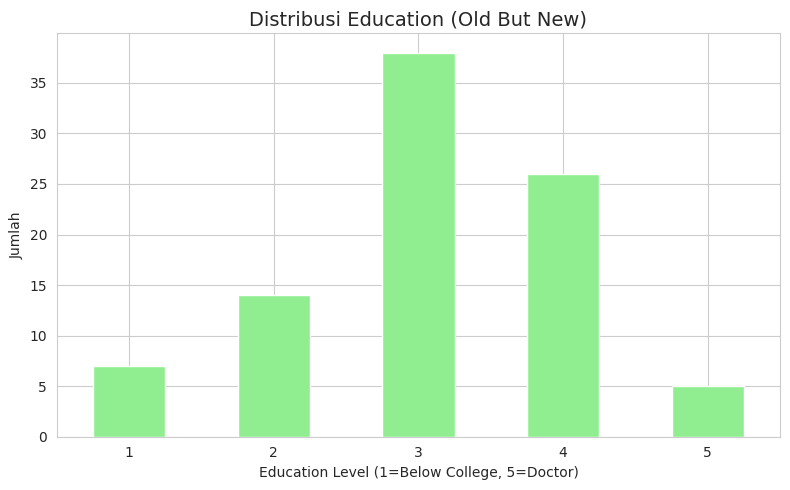


OLD BUT NEW x JOB SATISFACTION

📌 Distribusi Job Satisfaction (old but new):
JobSatisfaction
1    19
2    10
3    31
4    30
Name: count, dtype: int64

📌 Attrition Rate per Job Satisfaction (old but new):
JobSatisfaction
1    15.79
2     0.00
3    19.35
4     3.33
Name: Attrition, dtype: float64


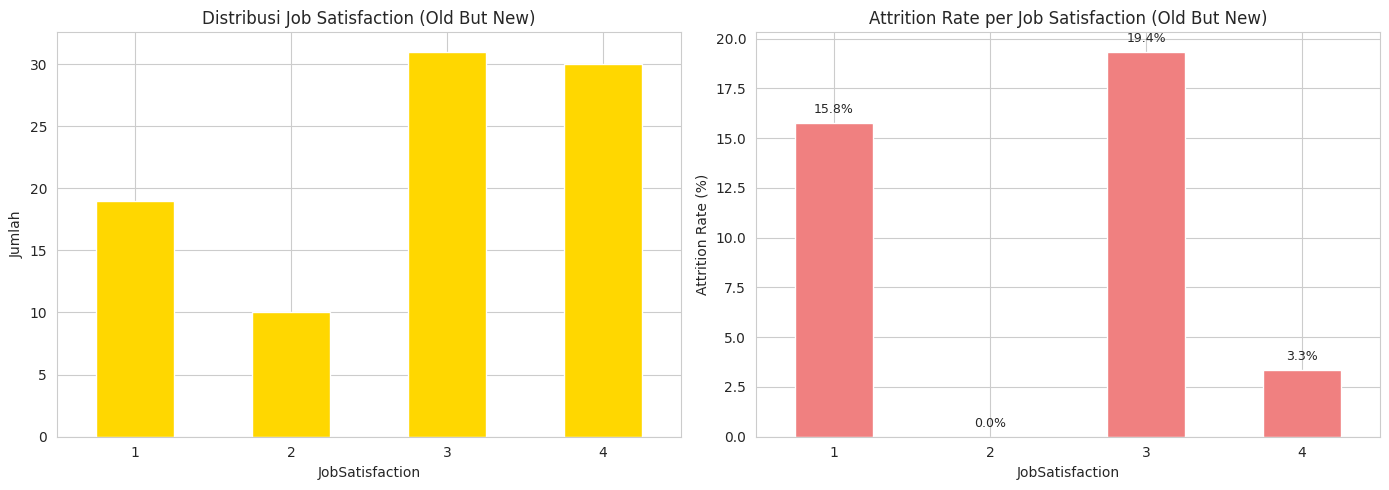


OLD BUT NEW x INCOME GROUP

📌 Distribusi Income Group (old but new):
income_group
Q1 (Terendah)     22
Q2                18
Q3                17
Q4 (Tertinggi)    33
Name: count, dtype: int64

📌 Attrition Rate per Income Group (old but new):
income_group
Q1 (Terendah)     22.73
Q2                16.67
Q3                 5.88
Q4 (Tertinggi)     3.03
Name: Attrition, dtype: float64


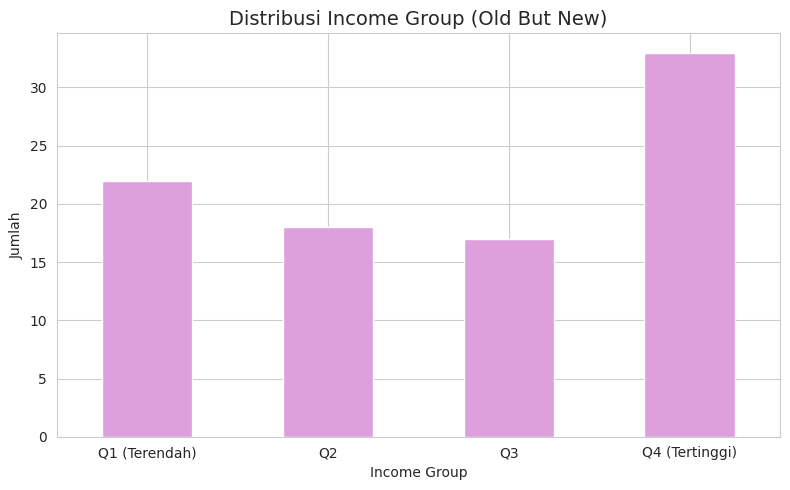


OLD BUT NEW x NUM COMPANIES WORKED

📌 Distribusi NumCompaniesWorked (old but new):
NumCompaniesWorked
1     3
2    15
3    19
4    23
5     7
6     7
7     6
8     6
9     4
Name: count, dtype: int64

📌 Attrition Rate per NumCompaniesWorked (old but new):
NumCompaniesWorked
1     0.00
2     6.67
3    10.53
4     4.35
5     0.00
6    42.86
7     0.00
8     0.00
9    75.00
Name: Attrition, dtype: float64


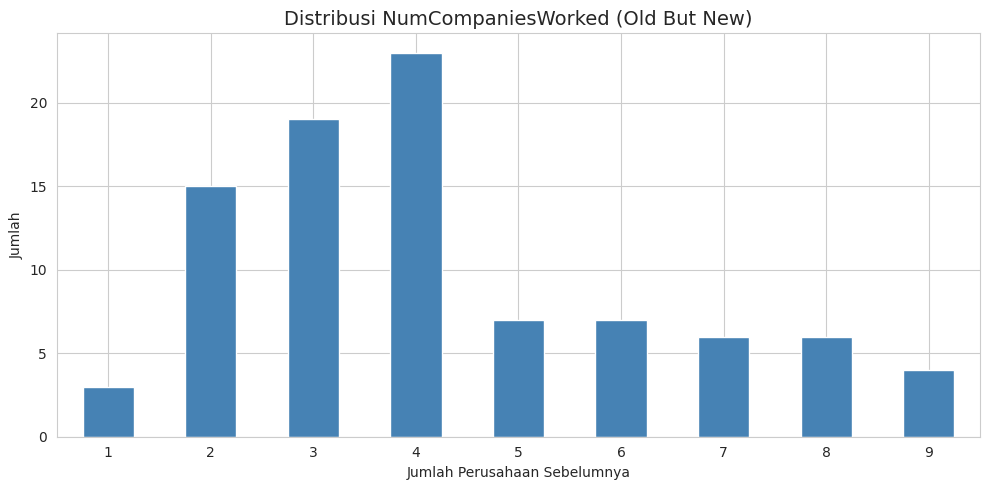

In [ ]:
# ============================================
# EDA - IS OLD BUT NEW
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("IS OLD BUT NEW - ANALISIS")
print("="*50)

# 1. Berapa banyak yang "old but new"?
old_new_count = df['is_old_but_new'].value_counts().sort_index()
print("\n📌 Distribusi is_old_but_new:")
print(old_new_count)
print(f"\nPersentase:")
print((old_new_count / len(df) * 100).round(1))

# Filter hanya yang is_old_but_new = 1
df_old_new = df[df['is_old_but_new'] == 1]
print(f"\n📌 Total karyawan 'old but new': {len(df_old_new)} orang")

# 2. Attrition Rate old but new vs bukan
print("\n" + "="*50)
print("ATTRITION RATE: OLD BUT NEW vs BUKAN")
print("="*50)

attrition_compare = df.groupby('is_old_but_new')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate:")
print(attrition_compare.round(2))

plt.figure(figsize=(6,5))
attrition_compare.plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Attrition Rate: Old But New vs Bukan', fontsize=14)
plt.xlabel('is_old_but_new (0=Bukan, 1=Ya)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(attrition_compare) + 5)
for i, v in enumerate(attrition_compare):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 3. OLD BUT NEW x DEPARTMENT
# ============================================

print("\n" + "="*50)
print("OLD BUT NEW x DEPARTMENT")
print("="*50)

dept_dist = df_old_new['Department'].value_counts()
print("\n📌 Distribusi Department (old but new):")
print(dept_dist)
print(f"\nPersentase:")
print((dept_dist / len(df_old_new) * 100).round(1))

dept_attrition = df_old_new.groupby('Department')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Department (old but new):")
print(dept_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
dept_dist.plot(kind='bar', ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Department (Old But New)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=45)

dept_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Department (Old But New)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(dept_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 4. OLD BUT NEW x EDUCATION
# ============================================

print("\n" + "="*50)
print("OLD BUT NEW x EDUCATION")
print("="*50)

edu_dist = df_old_new['Education'].value_counts().sort_index()
print("\n📌 Distribusi Education (old but new):")
print(edu_dist)

edu_attrition = df_old_new.groupby('Education')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Education (old but new):")
print(edu_attrition.round(2))

plt.figure(figsize=(8,5))
edu_dist.plot(kind='bar', color='lightgreen')
plt.title('Distribusi Education (Old But New)', fontsize=14)
plt.xlabel('Education Level (1=Below College, 5=Doctor)')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ============================================
# 5. OLD BUT NEW x JOB SATISFACTION
# ============================================

print("\n" + "="*50)
print("OLD BUT NEW x JOB SATISFACTION")
print("="*50)

jobsat_dist = df_old_new['JobSatisfaction'].value_counts().sort_index()
print("\n📌 Distribusi Job Satisfaction (old but new):")
print(jobsat_dist)

jobsat_attrition = df_old_new.groupby('JobSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Job Satisfaction (old but new):")
print(jobsat_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
jobsat_dist.plot(kind='bar', ax=axes[0], color='gold')
axes[0].set_title('Distribusi Job Satisfaction (Old But New)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

jobsat_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Job Satisfaction (Old But New)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(jobsat_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 6. OLD BUT NEW x INCOME GROUP
# ============================================

print("\n" + "="*50)
print("OLD BUT NEW x INCOME GROUP")
print("="*50)

income_dist = df_old_new['income_group'].value_counts().sort_index()
print("\n📌 Distribusi Income Group (old but new):")
print(income_dist)

income_attrition = df_old_new.groupby('income_group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Income Group (old but new):")
print(income_attrition.round(2))

plt.figure(figsize=(8,5))
income_dist.plot(kind='bar', color='plum')
plt.title('Distribusi Income Group (Old But New)', fontsize=14)
plt.xlabel('Income Group')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ============================================
# 7. OLD BUT NEW x NUM COMPANIES WORKED
# ============================================

print("\n" + "="*50)
print("OLD BUT NEW x NUM COMPANIES WORKED")
print("="*50)

ncomp_dist = df_old_new['NumCompaniesWorked'].value_counts().sort_index()
print("\n📌 Distribusi NumCompaniesWorked (old but new):")
print(ncomp_dist)

ncomp_attrition = df_old_new.groupby('NumCompaniesWorked')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per NumCompaniesWorked (old but new):")
print(ncomp_attrition.round(2))

plt.figure(figsize=(10,5))
ncomp_dist.plot(kind='bar', color='steelblue')
plt.title('Distribusi NumCompaniesWorked (Old But New)', fontsize=14)
plt.xlabel('Jumlah Perusahaan Sebelumnya')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Analisa karyawan berpengalaman dengan gaji rendah

IS UNDERPAID EXPERIENCED - ANALISIS

📌 Distribusi is_underpaid_experienced:
is_underpaid_experienced
0    1419
1      51
Name: count, dtype: int64

Persentase:
is_underpaid_experienced
0    96.5
1     3.5
Name: count, dtype: float64

📌 Total karyawan 'underpaid experienced': 51 orang

ATTRITION RATE: UNDERPAID vs BUKAN

📌 Attrition Rate:
is_underpaid_experienced
0    15.08
1    45.10
Name: Attrition, dtype: float64


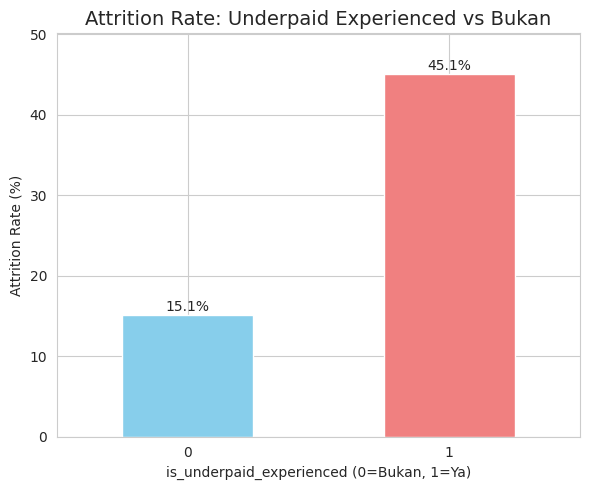


UNDERPAID x AGE GROUP

📌 Distribusi Age Group (underpaid):
age_group
18-25     0
26-35    28
36-45    16
46-60     7
Name: count, dtype: int64

📌 Attrition Rate per Age Group (underpaid):
age_group
26-35    53.57
36-45    31.25
46-60    42.86
Name: Attrition, dtype: float64


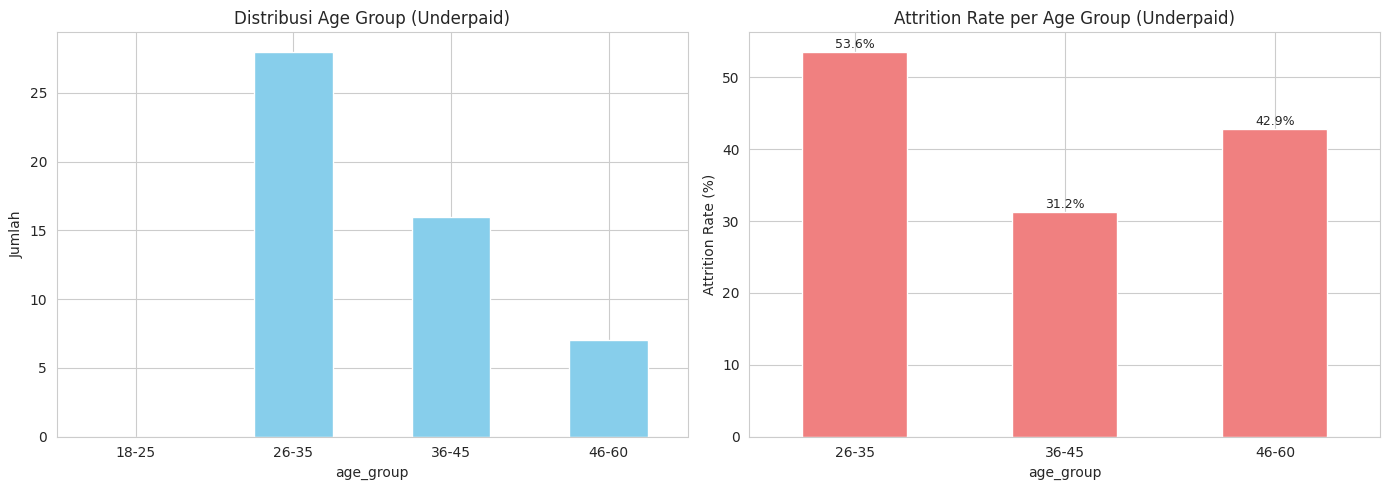


UNDERPAID x DEPARTMENT

📌 Distribusi Department (underpaid):
Department
Research & Development    43
Sales                      4
Human Resources            4
Name: count, dtype: int64

📌 Attrition Rate per Department (underpaid):
Department
Human Resources           25.00
Research & Development    46.51
Sales                     50.00
Name: Attrition, dtype: float64


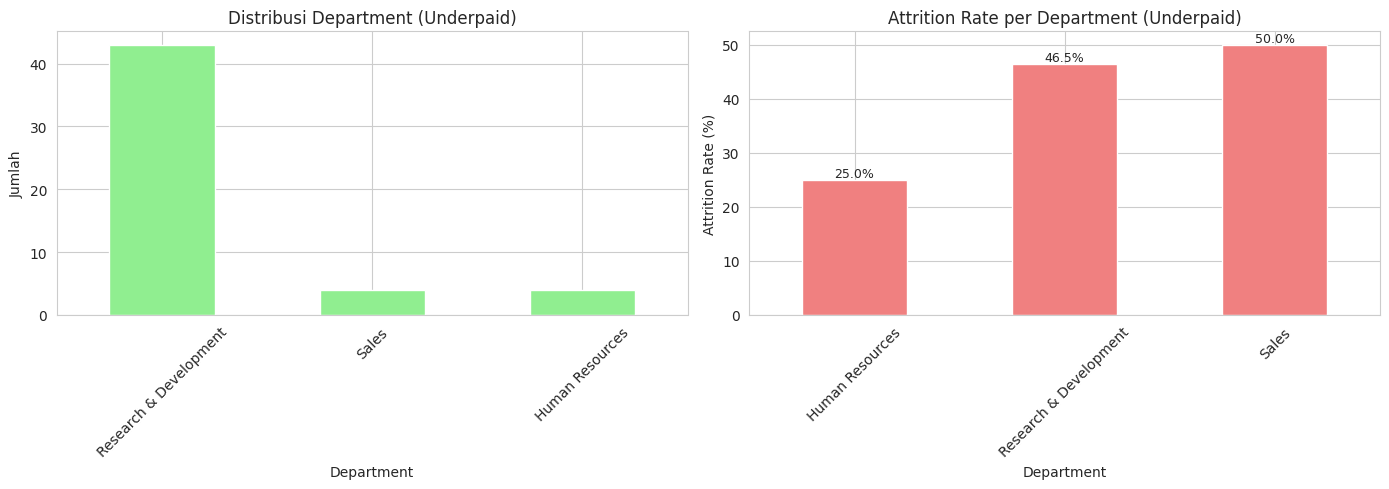


UNDERPAID x ENVIRONMENT SATISFACTION

📌 Distribusi Environment Satisfaction (underpaid):
EnvironmentSatisfaction
1    10
2     8
3    20
4    13
Name: count, dtype: int64

📌 Attrition Rate per Environment Satisfaction (underpaid):
EnvironmentSatisfaction
1    60.00
2    12.50
3    50.00
4    46.15
Name: Attrition, dtype: float64


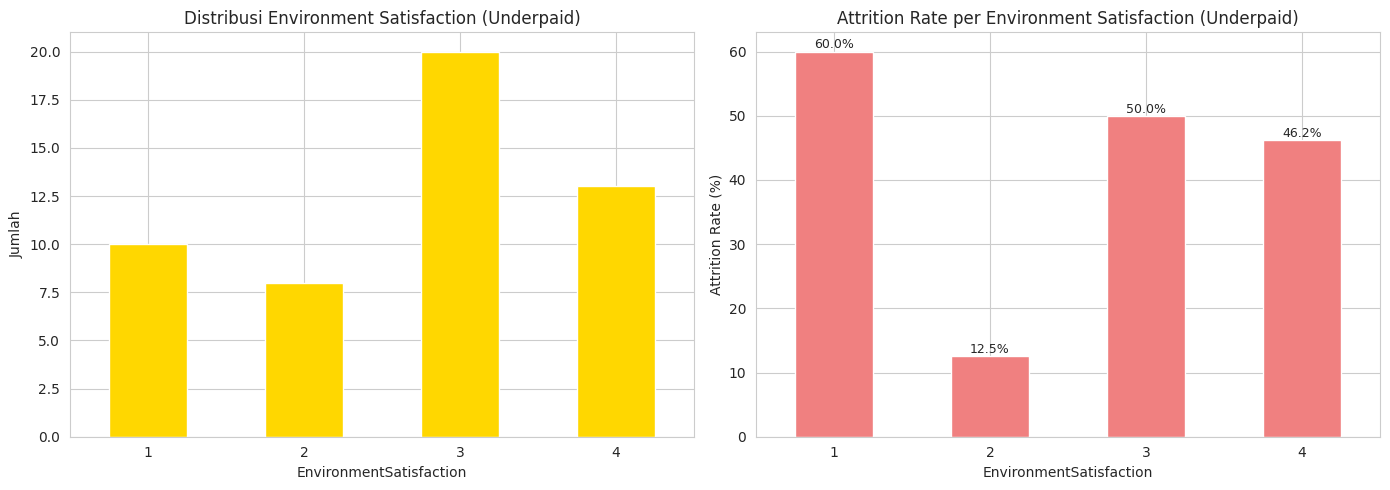


UNDERPAID x JOB SATISFACTION

📌 Distribusi Job Satisfaction (underpaid):
JobSatisfaction
1     9
2    12
3    14
4    16
Name: count, dtype: int64

📌 Attrition Rate per Job Satisfaction (underpaid):
JobSatisfaction
1    88.89
2    16.67
3    50.00
4    37.50
Name: Attrition, dtype: float64


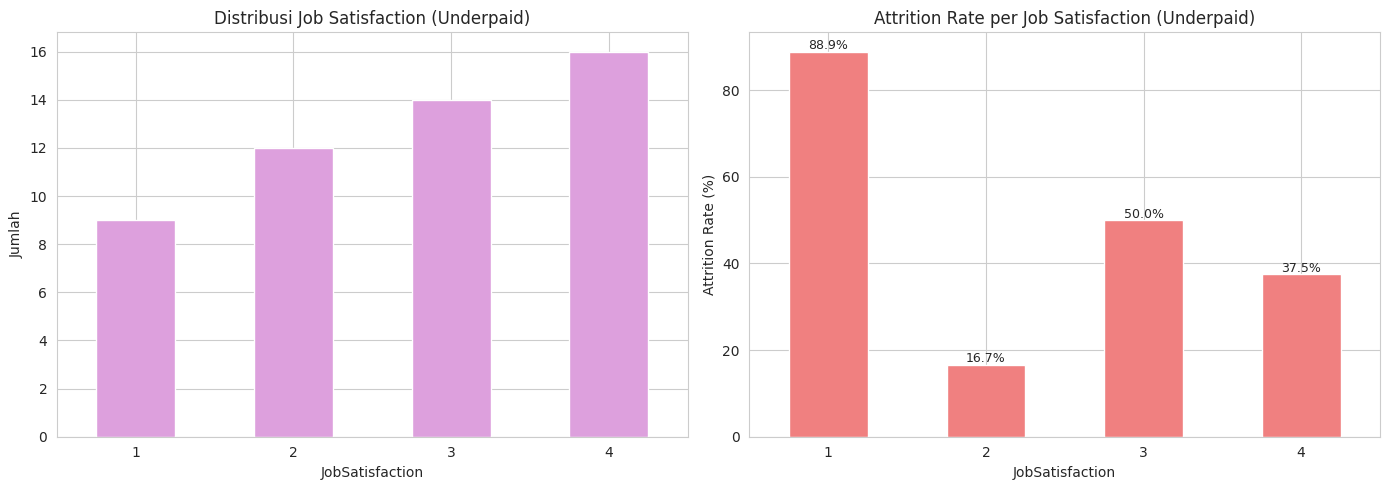


UNDERPAID x WORK LIFE BALANCE

📌 Distribusi Work Life Balance (underpaid):
WorkLifeBalance
1     7
2    10
3    28
4     6
Name: count, dtype: int64

📌 Attrition Rate per Work Life Balance (underpaid):
WorkLifeBalance
1    71.43
2    40.00
3    35.71
4    66.67
Name: Attrition, dtype: float64


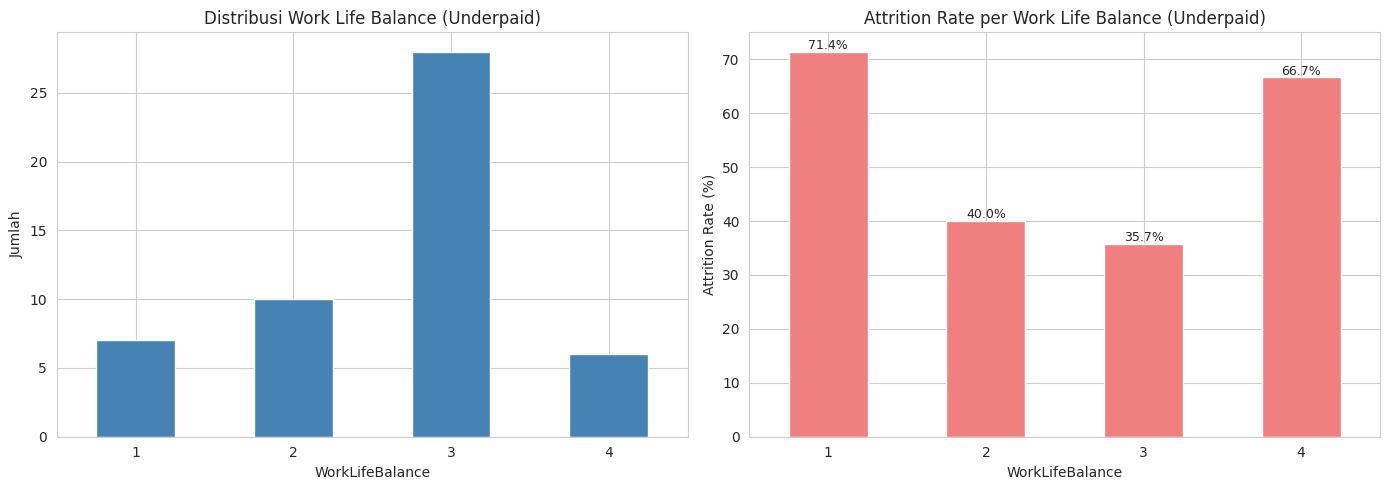


UNDERPAID x TENURE GROUP

📌 Distribusi Tenure Group (underpaid):
tenure_group
<1 year       14
1-3 years     17
3-5 years     10
5-10 years     8
10+ years      2
Name: count, dtype: int64

📌 Attrition Rate per Tenure Group (underpaid):
tenure_group
<1 year       57.14
1-3 years     29.41
3-5 years     50.00
5-10 years    62.50
10+ years      0.00
Name: Attrition, dtype: float64


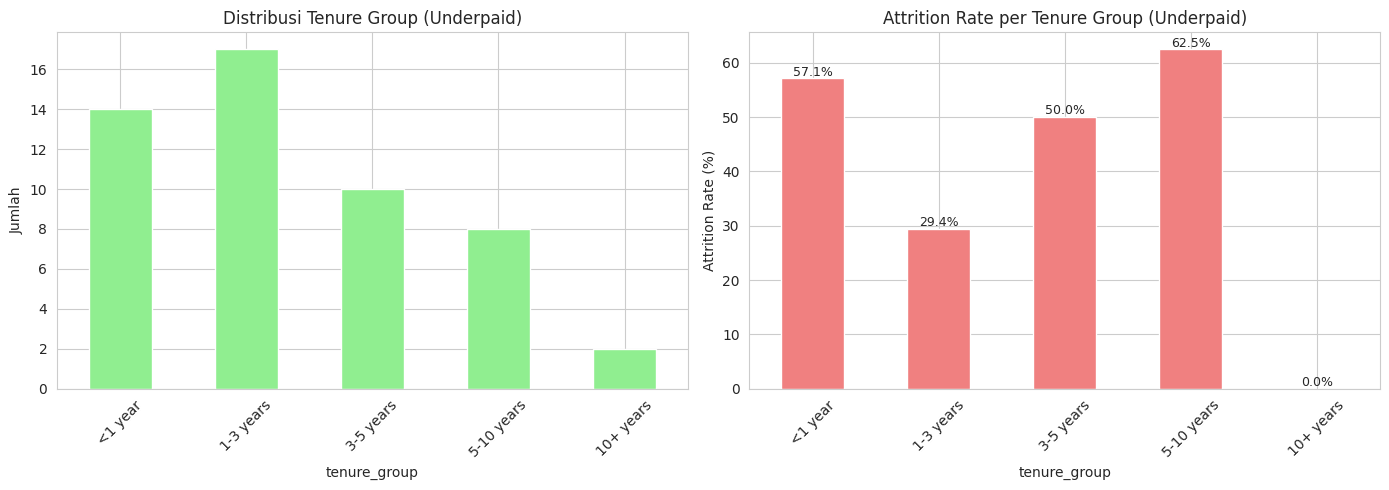


📌 Crosstab: Underpaid Experienced vs Attrition
Attrition                   No  Yes   All
is_underpaid_experienced                 
0                         1205  214  1419
1                           28   23    51
All                       1233  237  1470

📌 Crosstab (Persentase per Baris):
Attrition                   No   Yes
is_underpaid_experienced            
0                         84.9  15.1
1                         54.9  45.1


In [ ]:
# ============================================
# EDA - IS UNDERPAID EXPERIENCED
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

print("="*50)
print("IS UNDERPAID EXPERIENCED - ANALISIS")
print("="*50)

# 1. Berapa banyak yang "underpaid experienced"?
underpaid_count = df['is_underpaid_experienced'].value_counts().sort_index()
print("\n📌 Distribusi is_underpaid_experienced:")
print(underpaid_count)
print(f"\nPersentase:")
print((underpaid_count / len(df) * 100).round(1))

# Filter hanya yang is_underpaid_experienced = 1
df_underpaid = df[df['is_underpaid_experienced'] == 1]
print(f"\n📌 Total karyawan 'underpaid experienced': {len(df_underpaid)} orang")

# 2. Attrition Rate underpaid vs bukan
print("\n" + "="*50)
print("ATTRITION RATE: UNDERPAID vs BUKAN")
print("="*50)

attrition_compare = df.groupby('is_underpaid_experienced')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate:")
print(attrition_compare.round(2))

plt.figure(figsize=(6,5))
attrition_compare.plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Attrition Rate: Underpaid Experienced vs Bukan', fontsize=14)
plt.xlabel('is_underpaid_experienced (0=Bukan, 1=Ya)')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.ylim(0, max(attrition_compare) + 5)
for i, v in enumerate(attrition_compare):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 3. UNDERPAID x AGE GROUP
# ============================================

print("\n" + "="*50)
print("UNDERPAID x AGE GROUP")
print("="*50)

age_dist = df_underpaid['age_group'].value_counts().sort_index()
print("\n📌 Distribusi Age Group (underpaid):")
print(age_dist)

age_attrition = df_underpaid.groupby('age_group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Age Group (underpaid):")
print(age_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
age_dist.plot(kind='bar', ax=axes[0], color='skyblue')
axes[0].set_title('Distribusi Age Group (Underpaid)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

age_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Age Group (Underpaid)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(age_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 4. UNDERPAID x DEPARTMENT
# ============================================

print("\n" + "="*50)
print("UNDERPAID x DEPARTMENT")
print("="*50)

dept_dist = df_underpaid['Department'].value_counts()
print("\n📌 Distribusi Department (underpaid):")
print(dept_dist)

dept_attrition = df_underpaid.groupby('Department')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Department (underpaid):")
print(dept_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
dept_dist.plot(kind='bar', ax=axes[0], color='lightgreen')
axes[0].set_title('Distribusi Department (Underpaid)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=45)

dept_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Department (Underpaid)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(dept_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 5. UNDERPAID x ENVIRONMENT SATISFACTION
# ============================================

print("\n" + "="*50)
print("UNDERPAID x ENVIRONMENT SATISFACTION")
print("="*50)

envsat_dist = df_underpaid['EnvironmentSatisfaction'].value_counts().sort_index()
print("\n📌 Distribusi Environment Satisfaction (underpaid):")
print(envsat_dist)

envsat_attrition = df_underpaid.groupby('EnvironmentSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Environment Satisfaction (underpaid):")
print(envsat_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
envsat_dist.plot(kind='bar', ax=axes[0], color='gold')
axes[0].set_title('Distribusi Environment Satisfaction (Underpaid)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

envsat_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Environment Satisfaction (Underpaid)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(envsat_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 6. UNDERPAID x JOB SATISFACTION
# ============================================

print("\n" + "="*50)
print("UNDERPAID x JOB SATISFACTION")
print("="*50)

jobsat_dist = df_underpaid['JobSatisfaction'].value_counts().sort_index()
print("\n📌 Distribusi Job Satisfaction (underpaid):")
print(jobsat_dist)

jobsat_attrition = df_underpaid.groupby('JobSatisfaction')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Job Satisfaction (underpaid):")
print(jobsat_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
jobsat_dist.plot(kind='bar', ax=axes[0], color='plum')
axes[0].set_title('Distribusi Job Satisfaction (Underpaid)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

jobsat_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Job Satisfaction (Underpaid)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(jobsat_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 7. UNDERPAID x WORK LIFE BALANCE
# ============================================

print("\n" + "="*50)
print("UNDERPAID x WORK LIFE BALANCE")
print("="*50)

wlb_dist = df_underpaid['WorkLifeBalance'].value_counts().sort_index()
print("\n📌 Distribusi Work Life Balance (underpaid):")
print(wlb_dist)

wlb_attrition = df_underpaid.groupby('WorkLifeBalance')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).sort_index()
print("\n📌 Attrition Rate per Work Life Balance (underpaid):")
print(wlb_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
wlb_dist.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Work Life Balance (Underpaid)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

wlb_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Work Life Balance (Underpaid)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=0)
for i, v in enumerate(wlb_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 8. UNDERPAID x TENURE GROUP
# ============================================

print("\n" + "="*50)
print("UNDERPAID x TENURE GROUP")
print("="*50)

tenure_dist = df_underpaid['tenure_group'].value_counts().sort_index()
print("\n📌 Distribusi Tenure Group (underpaid):")
print(tenure_dist)

tenure_attrition = df_underpaid.groupby('tenure_group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100)
print("\n📌 Attrition Rate per Tenure Group (underpaid):")
print(tenure_attrition.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14,5))
tenure_dist.plot(kind='bar', ax=axes[0], color='lightgreen')
axes[0].set_title('Distribusi Tenure Group (Underpaid)')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=45)

tenure_attrition.plot(kind='bar', ax=axes[1], color='lightcoral')
axes[1].set_title('Attrition Rate per Tenure Group (Underpaid)')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(tenure_attrition):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ============================================
# 9. CROSSTAB
# ============================================

print("\n📌 Crosstab: Underpaid Experienced vs Attrition")
crosstab_underpaid = pd.crosstab(df['is_underpaid_experienced'], df['Attrition'], margins=True)
print(crosstab_underpaid)

print("\n📌 Crosstab (Persentase per Baris):")
crosstab_underpaid_pct = pd.crosstab(df['is_underpaid_experienced'], df['Attrition'], normalize='index') * 100
print(crosstab_underpaid_pct.round(1))

# Analisa Deskriptif (EDA Lanjutan)

ANALISIS DESKRIPTIF

📌 1. RINGKASAN UMUM DATASET
----------------------------------------
Jumlah baris    : 1470
Jumlah kolom    : 20
Missing values  : 0
Duplikat        : 0

📌 2. BASELINE ATTRITION RATE
----------------------------------------
Total karyawan       : 1470
Resign (Yes)         : 237 (16.1%)
Bertahan (No)        : 1233 (83.9%)


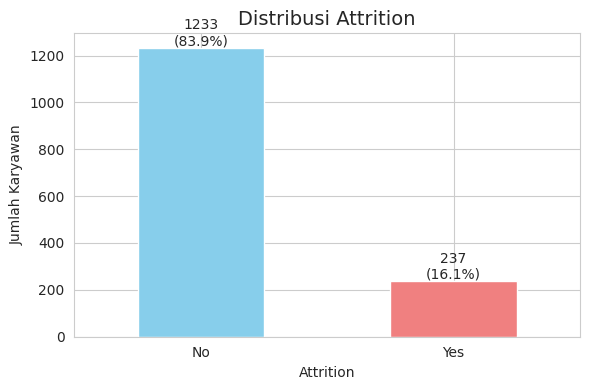


📌 3. STATISTIK DESKRIPTIF - KOLOM NUMERIK
----------------------------------------
                          count     mean      std     min     25%     50%  \
Age                      1470.0    36.92     9.14    18.0    30.0    36.0   
DistanceFromHome         1470.0     9.19     8.11     1.0     2.0     7.0   
Education                1470.0     2.91     1.02     1.0     2.0     3.0   
EnvironmentSatisfaction  1470.0     2.72     1.09     1.0     2.0     3.0   
JobSatisfaction          1470.0     2.73     1.10     1.0     2.0     3.0   
MonthlyIncome            1470.0  6502.93  4707.96  1009.0  2911.0  4919.0   
NumCompaniesWorked       1470.0     2.69     2.50     0.0     1.0     2.0   
WorkLifeBalance          1470.0     2.76     0.71     1.0     2.0     3.0   
YearsAtCompany           1470.0     7.01     6.13     0.0     3.0     5.0   

                            75%      max  skewness  kurtosis  
Age                        43.0     60.0      0.41     -0.40  
DistanceFromHome   

In [ ]:
# ============================================
# ANALISIS DESKRIPTIF (LENGKAP)
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("ANALISIS DESKRIPTIF")
print("="*60)

# ============================================
# 1. RINGKASAN UMUM DATASET
# ============================================

print("\n📌 1. RINGKASAN UMUM DATASET")
print("-"*40)
print(f"Jumlah baris    : {df.shape[0]}")
print(f"Jumlah kolom    : {df.shape[1]}")
print(f"Missing values  : {df.isnull().sum().sum()}")
print(f"Duplikat        : {df.duplicated().sum()}")

# ============================================
# 2. BASELINE ATTRITION RATE
# ============================================

print("\n📌 2. BASELINE ATTRITION RATE")
print("-"*40)
attrition_counts = df['Attrition'].value_counts()
attrition_pct = df['Attrition'].value_counts(normalize=True) * 100

print(f"Total karyawan       : {len(df)}")
print(f"Resign (Yes)         : {attrition_counts['Yes']} ({attrition_pct['Yes']:.1f}%)")
print(f"Bertahan (No)        : {attrition_counts['No']} ({attrition_pct['No']:.1f}%)")

# Plot
plt.figure(figsize=(6,4))
colors = ['skyblue', 'lightcoral']
attrition_counts.plot(kind='bar', color=colors)
plt.title('Distribusi Attrition', fontsize=14)
plt.xlabel('Attrition')
plt.ylabel('Jumlah Karyawan')
plt.xticks(rotation=0)
for i, v in enumerate(attrition_counts):
    plt.text(i, v + 10, f'{v}\n({attrition_pct.iloc[i]:.1f}%)', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

# ============================================
# 3. STATISTIK DESKRIPTIF - KOLOM NUMERIK
# ============================================

print("\n📌 3. STATISTIK DESKRIPTIF - KOLOM NUMERIK")
print("-"*40)

# Pilih kolom numerik aja (exclude flag 0/1)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
numeric_cols = [col for col in numeric_cols if df[col].nunique() > 2]  # exclude flag

desc_stats = df[numeric_cols].describe().T
desc_stats['skewness'] = df[numeric_cols].skew()
desc_stats['kurtosis'] = df[numeric_cols].kurtosis()

print(desc_stats.round(2))

# ============================================
# 4. STATISTIK DESKRIPTIF - KOLOM KATEGORIK
# ============================================

print("\n📌 4. STATISTIK DESKRIPTIF - KOLOM KATEGORIK")
print("-"*40)

categorical_cols = df.select_dtypes(include=['object']).columns
categorical_cols = [col for col in categorical_cols if col != 'Attrition']

for col in categorical_cols:
    print(f"\n{col}:")
    print(f"  Jumlah unique : {df[col].nunique()}")
    print(f"  Modus         : {df[col].mode()[0]}")
    print(f"  Distribusi    :")
    print(df[col].value_counts().to_string())

# ============================================
# 5. RINGKASAN PER KELOMPOK (GROUP SUMMARY)
# ============================================

print("\n📌 5. RINGKASAN PER KELOMPOK")
print("-"*40)

# 5.1 Attrition Rate per Department
print("\nAttrition Rate per Department:")
print(df.groupby('Department')['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(2).sort_values(ascending=False))

# 5.2 Rata-rata Income per Department
print("\nRata-rata MonthlyIncome per Department:")
print(df.groupby('Department')['MonthlyIncome'].mean().round(0).sort_values(ascending=False))

# 5.3 Rata-rata Job Satisfaction per Department
print("\nRata-rata JobSatisfaction per Department:")
print(df.groupby('Department')['JobSatisfaction'].mean().round(2).sort_values(ascending=False))

# 5.4 Attrition Rate per Age Group
print("\nAttrition Rate per Age Group:")
print(df.groupby('age_group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(2))

# 5.5 Attrition Rate per Income Group
print("\nAttrition Rate per Income Group:")
print(df.groupby('income_group', observed=True)['Attrition'].apply(lambda x: (x == 'Yes').mean() * 100).round(2))

# ============================================
# 6. TABEL RINGKASAN FINAL (BUAT PORTOFOLIO)
# ============================================

print("\n📌 6. TABEL RINGKASAN FINAL")
print("-"*40)

summary_table = pd.DataFrame({
    'Fitur': ['Total Karyawan', 'Resign', 'Bertahan', 'Attrition Rate'],
    'Nilai': [
        len(df),
        attrition_counts['Yes'],
        attrition_counts['No'],
        f"{attrition_pct['Yes']:.1f}%"
    ]
})
print(summary_table.to_string(index=False))

# ============================================
# 7. KESIMPULAN DESKRIPTIF
# ============================================

print("\n" + "="*60)
print("✅ ANALISIS DESKRIPTIF SELESAI")
print("="*60)

### Inferential Test

In [ ]:
# ============================================
# INFERENTIAL TEST - CHI-SQUARE (RINGKAS)
# ============================================

import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("INFERENTIAL TEST: CHI-SQUARE")
print("="*60)
print("H₀: Tidak ada hubungan antara variabel X dengan Attrition")
print("H₁: Ada hubungan antara variabel X dengan Attrition")
print("α = 0.05")
print("="*60)

# ============================================
# DAFTAR VARIABEL YANG DIUJI
# ============================================

variabel_uji = [
    ('Department', 'Department'),
    ('Age Group', 'age_group'),
    ('Income Group', 'income_group'),
    ('Job Satisfaction', 'JobSatisfaction'),
    ('Work Life Balance', 'WorkLifeBalance'),
    ('Environment Satisfaction', 'EnvironmentSatisfaction'),
    ('Marital Status', 'MaritalStatus'),
    ('Tenure Group', 'tenure_group')
]

# ============================================
# LOOP: UJI SEMUA VARIABEL
# ============================================

results = []

for nama, kolom in variabel_uji:
    print(f"\n📌 {nama.upper()}")
    print("-"*40)

    # Bikin crosstab
    crosstab = pd.crosstab(df[kolom], df['Attrition'])

    # Uji Chi-Square
    chi2, p_value, dof, expected = chi2_contingency(crosstab)

    print(f"Chi-Square : {chi2:.4f} | p-value : {p_value:.4f} | dof : {dof}")

    # Interpretasi
    if p_value < 0.05:
        print(f"✅ SIGNIFIKAN (p < 0.05)")
        status = '✅ Ya'
    else:
        print(f"❌ TIDAK SIGNIFIKAN (p ≥ 0.05)")
        status = '❌ Tidak'

    # Simpan hasil
    results.append({
        'Variabel': nama,
        'Chi-Square': round(chi2, 4),
        'p-value': round(p_value, 4),
        'Signifikan': status
    })

# ============================================
# RINGKASAN HASIL
# ============================================

print("\n" + "="*60)
print("📊 RINGKASAN HASIL CHI-SQUARE")
print("="*60)

summary = pd.DataFrame(results)
print(summary.to_string(index=False))

print("\n" + "="*60)
print("✅ INFERENTIAL TEST SELESAI")
print("="*60)

INFERENTIAL TEST: CHI-SQUARE
H₀: Tidak ada hubungan antara variabel X dengan Attrition
H₁: Ada hubungan antara variabel X dengan Attrition
α = 0.05

📌 DEPARTMENT
----------------------------------------
Chi-Square : 10.7960 | p-value : 0.0045 | dof : 2
✅ SIGNIFIKAN (p < 0.05)

📌 AGE GROUP
----------------------------------------
Chi-Square : 58.5630 | p-value : 0.0000 | dof : 3
✅ SIGNIFIKAN (p < 0.05)

📌 INCOME GROUP
----------------------------------------
Chi-Square : 65.4868 | p-value : 0.0000 | dof : 3
✅ SIGNIFIKAN (p < 0.05)

📌 JOB SATISFACTION
----------------------------------------
Chi-Square : 17.5051 | p-value : 0.0006 | dof : 3
✅ SIGNIFIKAN (p < 0.05)

📌 WORK LIFE BALANCE
----------------------------------------
Chi-Square : 16.3251 | p-value : 0.0010 | dof : 3
✅ SIGNIFIKAN (p < 0.05)

📌 ENVIRONMENT SATISFACTION
----------------------------------------
Chi-Square : 22.5039 | p-value : 0.0001 | dof : 3
✅ SIGNIFIKAN (p < 0.05)

📌 MARITAL STATUS
--------------------------------

## Cek normalitas

UJI NORMALITAS - SHAPIRO-WILK
H₀: Data berdistribusi NORMAL
H₁: Data TIDAK berdistribusi normal
α = 0.05

📌 Age
----------------------------------------
Shapiro-Wilk Statistic : 0.9774
p-value                : 0.0000
❌ p-value < 0.05 → TOLAK H₀
   Kesimpulan: Data TIDAK normal


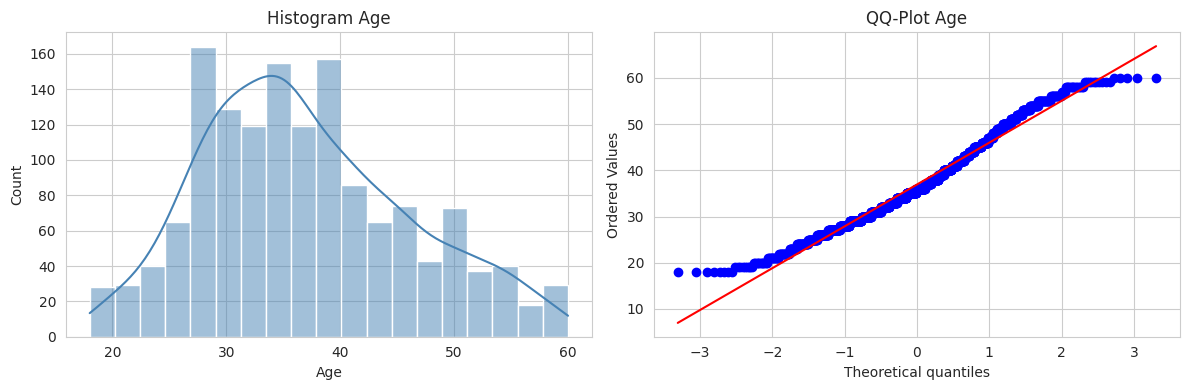


📌 MonthlyIncome
----------------------------------------
Shapiro-Wilk Statistic : 0.8279
p-value                : 0.0000
❌ p-value < 0.05 → TOLAK H₀
   Kesimpulan: Data TIDAK normal


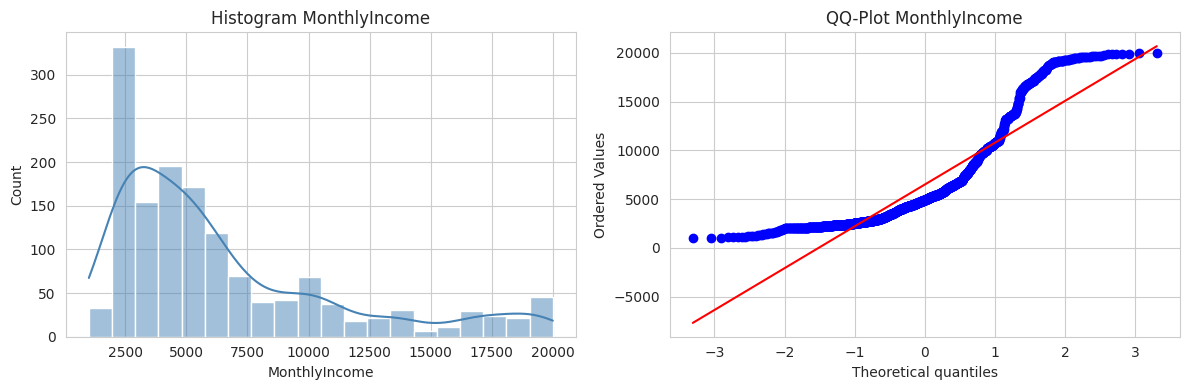


📌 DistanceFromHome
----------------------------------------
Shapiro-Wilk Statistic : 0.8616
p-value                : 0.0000
❌ p-value < 0.05 → TOLAK H₀
   Kesimpulan: Data TIDAK normal


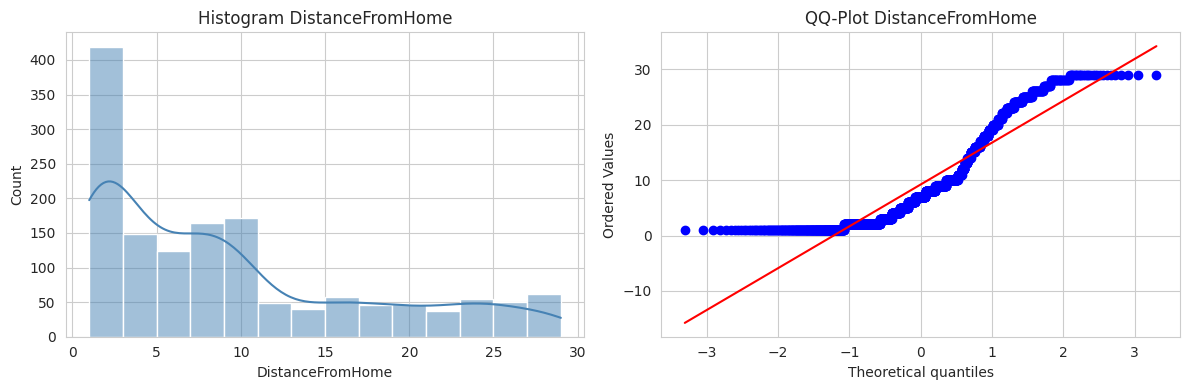


📌 NumCompaniesWorked
----------------------------------------
Shapiro-Wilk Statistic : 0.8488
p-value                : 0.0000
❌ p-value < 0.05 → TOLAK H₀
   Kesimpulan: Data TIDAK normal


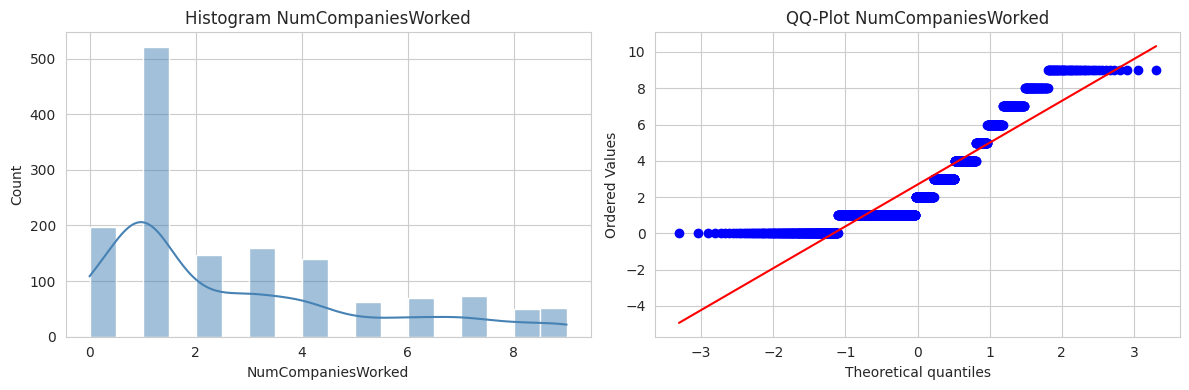


✅ UJI NORMALITAS SELESAI


In [ ]:
# ============================================
# UJI NORMALITAS (SHAPIRO-WILK)
# ============================================

import pandas as pd
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("UJI NORMALITAS - SHAPIRO-WILK")
print("="*60)
print("H₀: Data berdistribusi NORMAL")
print("H₁: Data TIDAK berdistribusi normal")
print("α = 0.05")
print("="*60)

# Variabel numerik yang mau diuji
numeric_vars = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'NumCompaniesWorked']

for var in numeric_vars:
    print(f"\n📌 {var}")
    print("-"*40)

    # Shapiro-Wilk Test
    stat, p_value = shapiro(df[var].dropna())

    print(f"Shapiro-Wilk Statistic : {stat:.4f}")
    print(f"p-value                : {p_value:.4f}")

    if p_value < 0.05:
        print("❌ p-value < 0.05 → TOLAK H₀")
        print("   Kesimpulan: Data TIDAK normal")
    else:
        print("✅ p-value ≥ 0.05 → GAGAL TOLAK H₀")
        print("   Kesimpulan: Data NORMAL")

    # Visualisasi: Histogram + QQ-Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogram
    sns.histplot(df[var], kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Histogram {var}')
    axes[0].set_xlabel(var)

    # QQ-Plot
    from scipy import stats
    stats.probplot(df[var].dropna(), dist="norm", plot=axes[1])
    axes[1].set_title(f'QQ-Plot {var}')

    plt.tight_layout()
    plt.show()

print("\n" + "="*60)
print("✅ UJI NORMALITAS SELESAI")
print("="*60)

# Mann-Whitney u test

INFERENTIAL TEST: MANN-WHITNEY U
H₀: Tidak ada perbedaan median antara grup resign vs bertahan
H₁: Ada perbedaan median antara grup resign vs bertahan
α = 0.05

📌 Age
----------------------------------------
Resign (Yes)  - n=237, median=32.0, mean=33.6
Bertahan (No) - n=1233, median=36.0, mean=37.6

Mann-Whitney U Statistic : 106859.0000
p-value                  : 0.0000

✅ p-value (0.0000) < 0.05 → TOLAK H₀
   Kesimpulan: Ada perbedaan SIGNIFIKAN antara yang resign vs bertahan


/tmp/ipykernel_3120/438353686.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Attrition', y=var, palette='Set2')


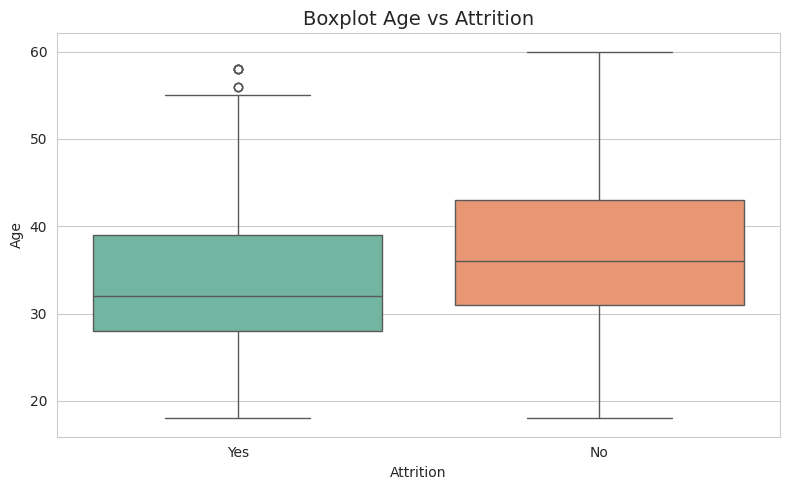


📌 MonthlyIncome
----------------------------------------
Resign (Yes)  - n=237, median=3202.0, mean=4787.1
Bertahan (No) - n=1233, median=5204.0, mean=6832.7

Mann-Whitney U Statistic : 100620.5000
p-value                  : 0.0000

✅ p-value (0.0000) < 0.05 → TOLAK H₀
   Kesimpulan: Ada perbedaan SIGNIFIKAN antara yang resign vs bertahan


/tmp/ipykernel_3120/438353686.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Attrition', y=var, palette='Set2')


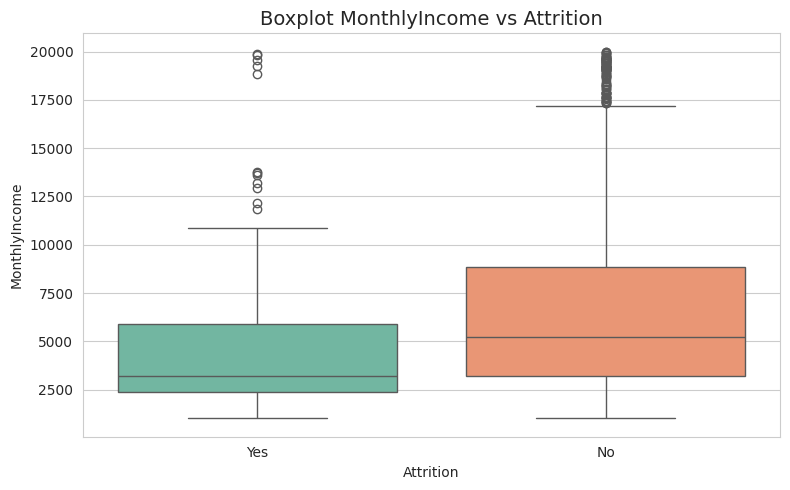


📌 DistanceFromHome
----------------------------------------
Resign (Yes)  - n=237, median=9.0, mean=10.6
Bertahan (No) - n=1233, median=7.0, mean=8.9

Mann-Whitney U Statistic : 164225.5000
p-value                  : 0.0024

✅ p-value (0.0024) < 0.05 → TOLAK H₀
   Kesimpulan: Ada perbedaan SIGNIFIKAN antara yang resign vs bertahan


/tmp/ipykernel_3120/438353686.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Attrition', y=var, palette='Set2')


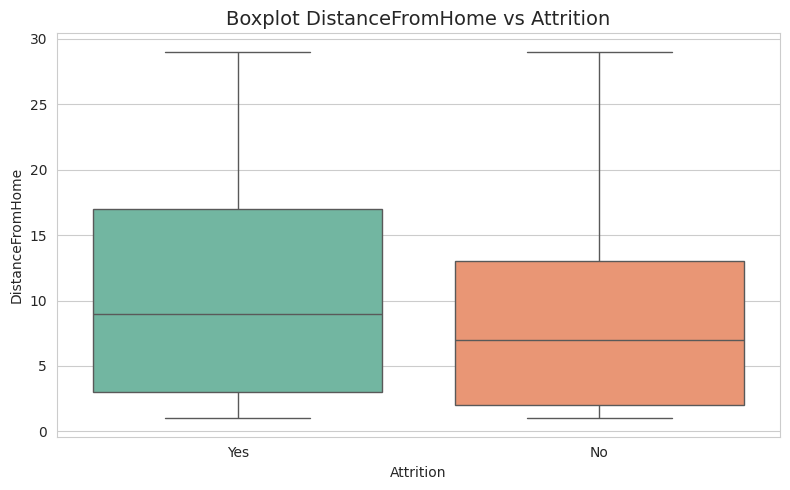


📌 NumCompaniesWorked
----------------------------------------
Resign (Yes)  - n=237, median=1.0, mean=2.9
Bertahan (No) - n=1233, median=2.0, mean=2.6

Mann-Whitney U Statistic : 152929.5000
p-value                  : 0.2424

❌ p-value (0.2424) ≥ 0.05 → GAGAL TOLAK H₀
   Kesimpulan: Tidak ada perbedaan signifikan


/tmp/ipykernel_3120/438353686.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Attrition', y=var, palette='Set2')


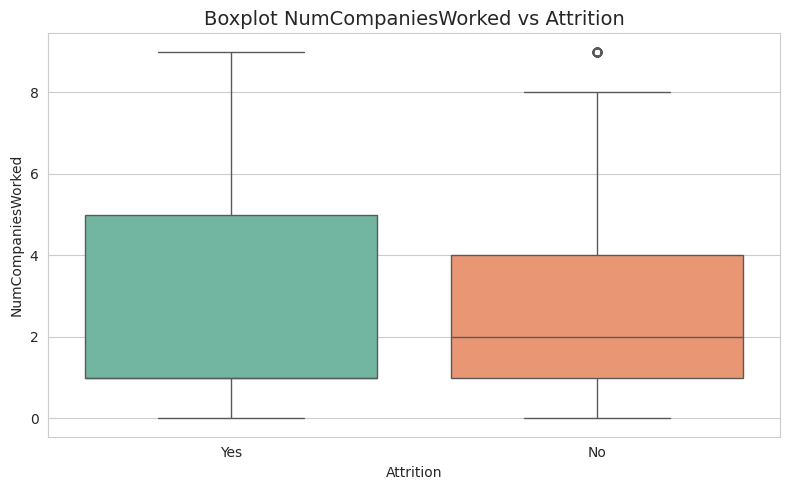


📊 RINGKASAN HASIL MANN-WHITNEY U
          Variabel  Median (Resign)  Median (Bertahan)  p-value Signifikan
               Age             32.0               36.0   0.0000       ✅ Ya
     MonthlyIncome           3202.0             5204.0   0.0000       ✅ Ya
  DistanceFromHome              9.0                7.0   0.0024       ✅ Ya
NumCompaniesWorked              1.0                2.0   0.2424    ❌ Tidak

✅ MANN-WHITNEY U SELESAI


In [ ]:
# ============================================
# INFERENTIAL TEST - MANN-WHITNEY U
# ============================================

import pandas as pd
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("INFERENTIAL TEST: MANN-WHITNEY U")
print("="*60)
print("H₀: Tidak ada perbedaan median antara grup resign vs bertahan")
print("H₁: Ada perbedaan median antara grup resign vs bertahan")
print("α = 0.05")
print("="*60)

# Variabel numerik yang mau diuji
numeric_vars = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'NumCompaniesWorked']

# Simpan hasil buat ringkasan
results_mw = []

for var in numeric_vars:
    print(f"\n📌 {var}")
    print("-"*40)

    # Pisahin grup berdasarkan Attrition
    group_yes = df[df['Attrition'] == 'Yes'][var]
    group_no = df[df['Attrition'] == 'No'][var]

    # Statistik deskriptif
    print(f"Resign (Yes)  - n={len(group_yes)}, median={group_yes.median():.1f}, mean={group_yes.mean():.1f}")
    print(f"Bertahan (No) - n={len(group_no)}, median={group_no.median():.1f}, mean={group_no.mean():.1f}")

    # Mann-Whitney U Test
    stat, p_value = mannwhitneyu(group_yes, group_no, alternative='two-sided')

    print(f"\nMann-Whitney U Statistic : {stat:.4f}")
    print(f"p-value                  : {p_value:.4f}")

    # Interpretasi
    if p_value < 0.05:
        print(f"\n✅ p-value ({p_value:.4f}) < 0.05 → TOLAK H₀")
        print(f"   Kesimpulan: Ada perbedaan SIGNIFIKAN antara yang resign vs bertahan")
    else:
        print(f"\n❌ p-value ({p_value:.4f}) ≥ 0.05 → GAGAL TOLAK H₀")
        print(f"   Kesimpulan: Tidak ada perbedaan signifikan")

    # Simpan hasil
    results_mw.append({
        'Variabel': var,
        'Median (Resign)': round(group_yes.median(), 1),
        'Median (Bertahan)': round(group_no.median(), 1),
        'p-value': round(p_value, 4),
        'Signifikan': '✅ Ya' if p_value < 0.05 else '❌ Tidak'
    })

    # Visualisasi: Boxplot
    plt.figure(figsize=(8,5))
    sns.boxplot(data=df, x='Attrition', y=var, palette='Set2')
    plt.title(f'Boxplot {var} vs Attrition', fontsize=14)
    plt.xlabel('Attrition')
    plt.ylabel(var)
    plt.tight_layout()
    plt.show()

# ============================================
# RINGKASAN HASIL MANN-WHITNEY
# ============================================

print("\n" + "="*60)
print("📊 RINGKASAN HASIL MANN-WHITNEY U")
print("="*60)

summary_mw = pd.DataFrame(results_mw)
print(summary_mw.to_string(index=False))

print("\n" + "="*60)
print("✅ MANN-WHITNEY U SELESAI")
print("="*60)

## Insight dan Rekomendasi

# 📊 Insight Final — Employee Attrition Analysis

---

## 1. Gambaran Umum Attrition

Dari **1.470 karyawan**, sebanyak **237 karyawan (16,1%)** resign. Angka ini menjadi **baseline** untuk menilai apakah suatu kelompok memiliki risiko resign yang lebih tinggi atau lebih rendah dari rata-rata perusahaan.

---

## 2. Faktor Paling Berpengaruh

**Ranking berdasarkan kekuatan hubungan (χ²):**

| Rank | Variabel | χ² | p-value |
|------|----------|-----|---------|
| 1 | **Tenure Group** | 75.59 | <0.0001 |
| 2 | **Income Group** | 65.49 | <0.0001 |
| 3 | **Age Group** | 58.56 | <0.0001 |
| 4 | **Marital Status** | 46.16 | <0.0001 |
| 5 | Environment Satisfaction | 22.50 | <0.0001 |
| 6 | Job Satisfaction | 17.51 | 0.0006 |
| 7 | Work Life Balance | 16.33 | 0.0010 |
| 8 | Department | 10.80 | 0.0045 |

**Dari Mann-Whitney U Test:**

- **Age:** p<0.0001 (median resign 32 vs bertahan 36) → SIGNIFIKAN
- **MonthlyIncome:** p<0.0001 (median resign 3.202 vs bertahan 5.204) → SIGNIFIKAN
- **DistanceFromHome:** p=0.0024 (median resign 9 vs bertahan 7) → SIGNIFIKAN
- **NumCompaniesWorked:** p=0.2424 → **TIDAK SIGNIFIKAN**

---

## 3. Insight Utama

### 📌 Insight 1: Masa Kerja = Faktor Terkuat

Karyawan dengan masa kerja **<1 tahun** memiliki attrition **34,9%** (75 dari 215) — hampir **3x lipat** dibanding karyawan 3-5 tahun (13,1%) dan 10+ tahun (8,1%). Hasil Chi-Square menunjukkan Tenure Group sebagai faktor **PALING KUAT** (χ²=75.59, p<0.0001). Artinya: **risiko resign paling tinggi terjadi di tahun pertama kerja.**

### 📌 Insight 2: Gaji Rendah = Risiko 2-3x Lipat

Karyawan dengan gaji **Q1 (terendah)** memiliki attrition **29,3%** — hampir **2x lipat** Q2 (14,2%) dan **3x lipat** Q3-Q4 (±10%). Dari Mann-Whitney, median gaji yang resign **Rp 3.202** vs bertahan **Rp 5.204** — selisih **±Rp 2 juta**.. Income Group adalah faktor terkuat kedua (χ²=65.49).

### 📌 Insight 3: Karyawan Muda Resign Bukan Karena Kepuasan

Usia **18-25** memiliki attrition **35,8%** — tertinggi, **4x lipat** usia 36-45 (9,2%). Yang menarik: dari heatmap EDA, kelompok 18-25 menunjukkan attrition **TINGGI di SEMUA level kepuasan** (Job, Environment, WLB) — **berbeda** dengan usia 26+ yang attrition-nya **turun** seiring naiknya kepuasan. Artinya: untuk anak muda, **meningkatkan kepuasan kerja saja TIDAK CUKUP.**

### 📌 Insight 4: Karyawan Single Paling Berisiko

Single: **25,5%** (120/470) — **2x lipat** married (12,5%) dan **2,5x lipat** divorced (10,1%). Chi-Square: χ²=46.16, p<0.0001 → SIGNIFIKAN. Karyawan single lebih **fleksibel** untuk pindah kerja (tanpa tanggungan keluarga).

### 📌 Insight 5: Jarak Rumah Berpengaruh Signifikan

Median jarak yang resign **9 km** vs bertahan **7 km** (p=0.0024). Karyawan yang **jauh dari rumah** cenderung lebih berisiko resign — *commuting fatigue*.

### 📌 Insight 6: Jumlah Perusahaan Sebelumnya TIDAK Signifikan

NumCompaniesWorked: **p=0.2424** → **TIDAK SIGNIFIKAN.** Meskipun EDA menunjukkan pola (angka 5+ punya attrition >20%), secara statistik perbedaan ini **TIDAK bisa digeneralisasi.** Artinya: "sering pindah kerja" **BUKAN prediktor yang valid** untuk attrition di dataset ini.

### 📌 Insight 7: Department Paling Lemah

Department: **χ²=10.80** (paling lemah dari semua variabel). Sales memang tertinggi (20,6%) dan R&D terendah (13,8%), tapi perbedaan ini kemungkinan disebabkan oleh **komposisi karyawan** (lebih banyak usia muda & gaji rendah di Sales), bukan oleh faktor "departemen" itu sendiri.

---

## 4. Rekomendasi

### 🎯 Prioritas 1: Program Retensi Karyawan Baru (<1 Tahun)

- **Fokus:** onboarding yang lebih kuat, mentoring, dan check-in rutin di 3-6 bulan pertama.
- **Target:** turunkan attrition <1 tahun dari 34,9% ke <20%.
- **Dasar:** Tenure Group adalah faktor terkuat (χ²=75.59).

### 🎯 Prioritas 2: Review Struktur Gaji (Terutama Q1)

- **Fokus:** evaluasi apakah gaji Q1 kompetitif; pertimbangkan kenaikan minimal ke level Q2 untuk kelompok berisiko.
- **Target:** turunkan attrition Q1 dari 29,3% ke <15%.
- **Dasar:** Income Group faktor terkuat kedua (χ²=65.49), selisih median gaji Rp 2 juta antara resign vs bertahan.

### 🎯 Prioritas 3: Program Khusus untuk Talenta Muda (18-25)

- **Fokus:** jalur karier yang jelas, rotasi peran, program pengembangan skill.
- **Kenapa:** attrition tinggi di SEMUA level kepuasan → bukan soal kepuasan, tapi soal fase eksplorasi karier.
- **Target:** turunkan attrition 18-25 dari 35,8% ke <25%.

### 🎯 Prioritas 4: Benefit & Fleksibilitas untuk Karyawan Single

- **Fokus:** benefit non-finansial (fleksibilitas kerja, pengembangan karier) karena karyawan single lebih fleksibel pindah.
- **Target:** turunkan attrition single dari 25,5% ke <18%.

### 🎯 Prioritas 5: Subsidi Transportasi / Fleksibilitas Lokasi

- **Fokus:** untuk karyawan dengan jarak >15 km, pertimbangkan subsidi transportasi atau opsi hybrid.
- **Dasar:** median jarak resign 9 km vs bertahan 7 km (p=0.0024).

### ⚠️ Catatan: JANGAN Fokus ke "Departemen"

Department adalah faktor **PALING LEMAH** (χ²=10.80). Intervensi berbasis departemen (misal: "program khusus Sales") **kurang efektif** dibanding intervensi berbasis **tenure, gaji, dan usia.**

---

## 5. Kesimpulan

Attrition di perusahaan ini dipengaruhi oleh **faktor demografis & kompensasi** (tenure, gaji, usia, status pernikahan) — **BUKAN** oleh departemen atau kepuasan kerja semata. Prioritas intervensi harus fokus pada:

1. **Karyawan baru** (<1 tahun)
2. **Karyawan bergaji rendah** (Q1)
3. **Karyawan muda** (18-25)
4. **Karyawan single**

Rekomendasi ini didukung oleh **validasi statistik** (Chi-Square & Mann-Whitney) sehingga dapat dijadikan dasar pengambilan keputusan HR.